# GNN Project — GAT for next-period category recommendation (Retail POS dataset)

This notebook repeats the GAT pipeline of `DataCleaningData_Dataset2.ipynb` (EuroMart) on a second dataset, `Data/retail_pos_transactions_v3.csv`. Only **GAT** is trained (no GCN). It is compared with the same baselines: **Popularity, Repeat-last-period, Repeat-frequent, Logistic Regression and MLP**.

**Task.** Given a customer's purchases up to period *t*, predict which product categories they buy in *t+1*. Output: a customer × category probability matrix (multi-label link prediction on a customer–item bipartite graph).

**Working style (same as the EuroMart notebook).** A *what & why* markdown cell before each code cell and an **Insight** cell after each result. Lessons carried over from EuroMart are applied from the start and flagged where they are used (degree-preserving edge-swap null, controlled persistence test, 50-epoch warm-up before early stopping, 0.01 adoption rule, seed-std rule plus a paired bootstrap on the test set).

**Evaluation protocol (group-agreed, same for every model in the comparison)**
- **Split:** 12 months in total, on whole-month boundaries: **Train 8 months (Jan–Aug), Validation 2 (Sep–Oct), Test 2 (Nov–Dec)**.
- **Loss:** **full BCE** over every (customer, category) cell of each training snapshot (no negative sampling).
- **Final seeds:** **42, 43, 44**.
- **Metrics:** Recall / Precision / NDCG / HitRate at **@3, @5, @10**, plus **PR-AUC**. **Headline metric: NDCG@5** (also used for early stopping and tuning decisions).
- **Decoder:** the **dot-product decoder score(u, c) = z_u · z_c is kept fixed** across the feature-aware architecture comparison, so differences between architectures come from the encoder only.

**Data dictionary (retail_pos_transactions_v3.csv)**

| Column | Meaning |
|---|---|
| `source_dataset` | name of the source system (constant: `retail_pos`) |
| `order_id` | integer id of a POS transaction (basket) |
| `event_time` | timestamp of the transaction (minute resolution) |
| `customer_id` | integer customer id |
| `category` | product category (17 values, e.g. Grains & Staples, Dairy & Eggs, Electronics) |
| `product_name` | product (68 values; each belongs to exactly one category) |
| `quantity` | units on the line (1–3) |
| `value_proxy` | monetary value of the line (a proxy for sales amount) |
| `month` | `YYYY-MM` of `event_time` |

## Experiment Log

*Protocol: 12 months = train 8 / val 2 / test 2; full BCE; dot-product decoder fixed; final seeds 42, 43, 44; headline metric NDCG@5.*

*Validation set (targets 2024-09 and 2024-10, 255 customer-months). Adoption rule: change kept only if val NDCG@5 improves by >= 0.01. Reference: Popularity NDCG@5 0.483 / Recall@5 0.438 / NDCG@10 0.625 / PR-AUC 0.415.*

| Round | Model | Change | Val NDCG@5 | Val Recall@5 | Val NDCG@10 | Val PR-AUC | Conclusion |
|---|---|---|---|---|---|---|---|
| G1 | GAT | baseline (2L, 4 heads, d64, att-drop .1) | 0.4939 | 0.4460 | 0.6287 | 0.3991 | GAT reference |
| G2 | GAT | heads = 1 | 0.4916 | 0.4475 | 0.6264 | 0.4054 |  |
| G2 | GAT | heads = 2 | 0.4966 | 0.4489 | 0.6295 | 0.3996 |  |
| G2 | GAT | heads = 8 | 0.4975 | 0.4489 | 0.6283 | 0.3947 | best heads=8 gain +0.004 -> adopt 4 |
| G3 | GAT | layers = 1 | 0.4942 | 0.4466 | 0.6277 | 0.3888 |  |
| G3 | GAT | layers = 3 | 0.4915 | 0.4455 | 0.6285 | 0.4126 | best layers=1 gain +0.000 -> adopt 2 |
| G4 | GAT | att_dropout = 0.0 | 0.4839 | 0.4323 | 0.6275 | 0.3743 |  |
| G4 | GAT | att_dropout = 0.3 | 0.4908 | 0.4396 | 0.6286 | 0.3987 | best att_dropout=0.1 gain +0.000 -> adopt 0.1 |
| G5 | GAT | dropout = 0.1 | 0.4919 | 0.4412 | 0.6291 | 0.4005 |  |
| G5 | GAT | dropout = 0.3 | 0.4867 | 0.4323 | 0.6281 | 0.3788 |  |
| G5 | GAT | dropout = 0.5 | 0.4801 | 0.4419 | 0.6172 | 0.4050 | best dropout=0.0 gain +0.000 -> adopt 0.0 |
| G6 | GAT | wd = 1e-06 | 0.4933 | 0.4449 | 0.6289 | 0.3938 |  |
| G6 | GAT | wd = 1e-05 | 0.4958 | 0.4499 | 0.6288 | 0.3922 |  |
| G6 | GAT | wd = 0.0001 | 0.4985 | 0.4514 | 0.6308 | 0.3953 |  |
| G6 | GAT | wd = 0.001 | 0.4916 | 0.4437 | 0.6289 | 0.3814 | best wd=0.0001 gain +0.005 -> adopt 0.0 |

**Final GAT config:** {'hidden': 64, 'layers': 2, 'heads': 4, 'att_dropout': 0.1, 'dropout': 0.0, 'lr': 0.001, 'wd': 0.0}

**Final TEST results (targets 2024-11 and 2024-12, 262 customer-months; mean ± std over seeds 42, 43, 44):**

| Model | **NDCG@5** | Recall@5 | Precision@5 | HitRate@5 | NDCG@3 | NDCG@10 | Recall@10 | PR-AUC | Params | GAT vs this model (gap > seed std; NDCG@5 / NDCG@3 / NDCG@10 / PR-AUC) |
|---|---|---|---|---|---|---|---|---|---|---|
| Popularity | 0.4894 ± 0.0000 | 0.4482 ± 0.0000 | 0.4214 ± 0.0000 | 0.9580 ± 0.0000 | 0.4761 ± 0.0000 | 0.6250 ± 0.0000 | 0.7626 ± 0.0000 | 0.4153 ± 0.0000 | 17 | WORSE / no difference / WORSE / WORSE |
| Repeat-last-period | 0.4323 ± 0.0000 | 0.3995 ± 0.0000 | 0.3802 ± 0.0000 | 0.9237 ± 0.0000 | 0.4202 ± 0.0000 | 0.5738 ± 0.0000 | 0.7265 ± 0.0000 | 0.3559 ± 0.0000 | 0 | BETTER / BETTER / BETTER / BETTER |
| Repeat-frequent | 0.4449 ± 0.0000 | 0.4113 ± 0.0000 | 0.3916 ± 0.0000 | 0.9160 ± 0.0000 | 0.4337 ± 0.0000 | 0.5795 ± 0.0000 | 0.7261 ± 0.0000 | 0.3632 ± 0.0000 | 0 | BETTER / BETTER / BETTER / BETTER |
| LogReg | 0.4858 ± 0.0000 | 0.4347 ± 0.0000 | 0.4137 ± 0.0000 | 0.9313 ± 0.0000 | 0.4834 ± 0.0000 | 0.6283 ± 0.0000 | 0.7638 ± 0.0000 | 0.4183 ± 0.0000 | 37 | WORSE / WORSE / WORSE / WORSE |
| MLP | 0.4383 ± 0.0272 | 0.4055 ± 0.0220 | 0.3845 ± 0.0209 | 0.9237 ± 0.0165 | 0.4243 ± 0.0287 | 0.5714 ± 0.0315 | 0.7165 ± 0.0323 | 0.3497 ± 0.0355 | 2,433 | BETTER / BETTER / BETTER / no difference |
| GAT | 0.4747 ± 0.0077 | 0.4304 ± 0.0165 | 0.4084 ± 0.0141 | 0.9517 ± 0.0018 | 0.4722 ± 0.0085 | 0.6194 ± 0.0025 | 0.7664 ± 0.0027 | 0.3810 ± 0.0056 | 23,232 | reference |

*Generated by the `exp_log_markdown()` cell near the end of the notebook. The G1 config is the reference for G2; values equal to the current config are not repeated.*

## Phase 0 — Setup

**What:** import libraries, set seeds (random / numpy / torch), choose the device, and check that PyTorch Geometric's `GATConv` is available.

**Why:** reproducibility for the tuning rounds and the final evaluation with seeds 42, 43, 44 depends on one `set_seed()` helper called before every run. Same environment as the EuroMart notebook (torch + torch_geometric already installed there), so no installs are needed. CPU is used, as before: the graph is small and PyG scatter ops are most reliable on CPU.

In [1]:
import os, random, time, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
warnings.filterwarnings('ignore', category=FutureWarning)

import torch_geometric
from torch_geometric.nn import GATConv
print('torch', torch.__version__, '| torch_geometric', torch_geometric.__version__)
try:
    import umap
    print('umap-learn', umap.__version__)
except Exception as e:
    print('umap unavailable ->', e)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed()
DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print('using DEVICE =', DEVICE)
pd.set_option('display.width', 200, 'display.max_columns', 30)

torch 2.14.1 | torch_geometric 2.8.0.post1
umap-learn 0.5.12
using DEVICE = cpu


## Phase 1 — Dataset audit

**What:** load the CSV into `raw` (parsing `event_time`) and print shape, dtypes and head.

**Why:** a basic structural check. `raw` stays untouched so every later drop or merge can be logged against it.

In [2]:
DATA_PATH = '/Users/engyixuan/Documents/Y4S1/SC4020 Data Mining/Project/Data/retail_pos_transactions_v3.csv'
raw = pd.read_csv(DATA_PATH, parse_dates=['event_time'])
print('shape:', raw.shape)
print()
print(raw.dtypes.to_string())
raw.head()

shape: (10000, 9)

source_dataset               str
order_id                   int64
event_time        datetime64[us]
customer_id                int64
category                     str
product_name                 str
quantity                 float64
value_proxy              float64
month                        str


,source_dataset,order_id,event_time,customer_id,category,product_name,quantity,value_proxy,month
0,retail_pos,1000,2024-09-04 15:43:00,341,Grains & Staples,Wheat Flour,1.0,333.44,2024-09
1,retail_pos,1000,2024-09-04 15:43:00,341,Household,Dishwashing Liquid,2.0,811.84,2024-09
2,retail_pos,1000,2024-09-04 15:43:00,341,Bakery,Pastry,2.0,228.30,2024-09
3,retail_pos,1000,2024-09-04 15:43:00,341,Stationery,Marker,2.0,342.66,2024-09
4,retail_pos,1001,2024-03-07 08:45:00,324,Clothing,Saree,2.0,82.32,2024-03


**Insight (load).** 10,000 rows × 9 columns. `event_time` parses as a datetime, `quantity` and `value_proxy` are numeric, and there is a real integer `customer_id` (EuroMart only had a name). There are **no customer attributes at all** (no segment, no location), so every customer feature will have to be derived from purchase history.

**What next:** missing values, duplicates at several grains (full row, order+product, order+category), header consistency (one customer and one timestamp per order), numeric ranges, date range and cardinality.

In [3]:
na = raw.isna().sum()
print('Missing values per column:', 'none' if na.sum() == 0 else na[na > 0].to_dict())
txt_cols = ['source_dataset', 'category', 'product_name', 'month']
print('Empty / whitespace-only strings:', int(raw[txt_cols].apply(lambda s: s.astype(str).str.strip() == '').sum().sum()))
print()
print('Exact duplicate rows            :', raw.duplicated().sum())
print('Dup (order_id, product_name)    :', raw.duplicated(['order_id', 'product_name']).sum())
print('Dup (order_id, category)        :', raw.duplicated(['order_id', 'category']).sum(), '(expected: baskets hold several products of one category)')
print('Orders with >1 customer         :', (raw.groupby('order_id')['customer_id'].nunique() > 1).sum())
print('Orders with >1 timestamp        :', (raw.groupby('order_id')['event_time'].nunique() > 1).sum())
print('Products in >1 category         :', (raw.groupby('product_name')['category'].nunique() > 1).sum())
print("'month' consistent with event_time:", (raw['month'] == raw['event_time'].dt.strftime('%Y-%m')).all())
print('source_dataset values           :', raw['source_dataset'].unique().tolist())
print()
print('Date range:', raw['event_time'].min(), '->', raw['event_time'].max())
print()
print(raw[['quantity', 'value_proxy']].describe().T.to_string())
print('quantity values:', raw['quantity'].value_counts().sort_index().to_dict())
print('corr(quantity, value_proxy):', round(raw[['quantity', 'value_proxy']].corr().iloc[0, 1], 3))
print('coefficient of variation of unit value within a product (median over products):',
      round(raw.assign(u=raw.value_proxy / raw.quantity).groupby('product_name')['u'].agg(lambda s: s.std() / s.mean()).median(), 3))
print()
print('Cardinality:'); print(raw.nunique().to_string())

Missing values per column: none
Empty / whitespace-only strings: 0

Exact duplicate rows            : 0
Dup (order_id, product_name)    : 299
Dup (order_id, category)        : 1477 (expected: baskets hold several products of one category)
Orders with >1 customer         : 0
Orders with >1 timestamp        : 0
Products in >1 category         : 0
'month' consistent with event_time: True
source_dataset values           : ['retail_pos']

Date range: 2024-01-01 06:23:00 -> 2024-12-31 21:33:00

               count        mean         std    min      25%      50%     75%      max
quantity     10000.0    2.009400    0.820597   1.00    1.000    2.000    3.00     3.00
value_proxy  10000.0  516.010636  372.479825  10.09  219.765  424.385  768.45  1499.82
quantity values: {1.0: 3320, 2.0: 3266, 3.0: 3414}
corr(quantity, value_proxy): 0.574
coefficient of variation of unit value within a product (median over products): 0.549

Cardinality:
source_dataset       1
order_id          1991
event_time   

**Insight (integrity).** No missing values, no blank strings, no exact duplicate rows. Every order has exactly one customer and one timestamp, every product belongs to exactly one category, and `month` agrees with `event_time`. `source_dataset` is constant, so it is dropped as a feature.

- **Time span is only one year (2024-01 → 2024-12, 12 months).** EuroMart had 48 months, which is why it could use quarters. Here quarters would give only 4 periods (3 targets), which is not enough for train/val/test. Phase 2 checks whether **monthly** periods are dense enough.
- **`value_proxy` is not price × quantity.** The unit value of the *same product* varies with a coefficient of variation of ~0.55, and corr(quantity, value) is only 0.57. It is a noisy value signal, so it is used only as a log-scaled spend feature, never as an edge weight.
- **Quantity is uniform on {1, 2, 3}** (about 1/3 each), another sign of generated data.
- **299 rows repeat an (order, product) pair.** Inspected next.

*Next:* look at the repeated order–product lines, then per-customer activity.

In [4]:
dup_mask = raw.duplicated(['order_id', 'product_name'], keep=False)
print('rows involved:', dup_mask.sum(), '| orders involved:', raw.loc[dup_mask, 'order_id'].nunique())
display(raw.loc[dup_mask].sort_values(['order_id', 'product_name']).head(8)[['order_id', 'event_time', 'customer_id', 'category', 'product_name', 'quantity', 'value_proxy']])
grp = raw[dup_mask].groupby(['order_id', 'product_name'])
print('pairs with identical quantity AND value:', int((grp['quantity'].nunique().eq(1) & grp['value_proxy'].nunique().eq(1)).sum()), 'of', grp.ngroups)
print('lines per order (all orders):', raw.groupby('order_id').size().value_counts().sort_index().to_dict())

rows involved: 595 | orders involved: 283


,order_id,event_time,customer_id,category,product_name,quantity,value_proxy
32,1008,2024-10-17 18:35:00,129,Bakery,Cookies,3.0,1441.83
37,1008,2024-10-17 18:35:00,129,Bakery,Cookies,1.0,330.59
83,1019,2024-07-13 12:58:00,405,Household,Tissue,2.0,745.48
84,1019,2024-07-13 12:58:00,405,Household,Tissue,3.0,1180.77
129,1028,2024-08-22 12:39:00,427,Grains & Staples,Spices,2.0,312.38
131,1028,2024-08-22 12:39:00,427,Grains & Staples,Spices,2.0,236.50
148,1033,2024-10-27 12:25:00,347,Stationery,Marker,3.0,275.79
150,1033,2024-10-27 12:25:00,347,Stationery,Marker,1.0,482.51


pairs with identical quantity AND value: 0 of 296
lines per order (all orders): {2: 1, 3: 388, 4: 388, 5: 428, 6: 360, 7: 426}


**Insight (repeated lines).** 296 (order, product) pairs appear on 2–3 lines (595 rows, 283 orders). No pair has identical quantity and value, so these are **split lines** (the same product scanned twice), not duplicate records. Same treatment as EuroMart: **merge** each pair into one line (sum quantity and value). Lines per order are spread almost uniformly over 3–7 (one order has 2), which again looks generated rather than organic (real baskets are right-skewed).

**What:** create the GNN-ready interaction table `df`: drop rows with invalid keys or non-positive quantity/value (expected: none), merge split lines, add contiguous integer ids for customers, categories and products, and add `month` and `m_idx` (0–11) period columns. Every change is recorded in `clean_log`.

In [5]:
clean_log = []
def log(step, before, after, why):
    clean_log.append({'step': step, 'rows_before': before, 'rows_after': after, 'rows_removed': before - after, 'reason': why})

df = raw.drop(columns=['source_dataset']).copy()

# 1) invalid / empty keys
n0 = len(df)
key_cols = ['order_id', 'customer_id', 'product_name', 'category', 'event_time']
df = df.dropna(subset=key_cols)
df = df[~df[['product_name', 'category']].apply(lambda s: s.astype(str).str.strip().eq('')).any(axis=1)]
log('drop invalid/empty keys', n0, len(df), 'null or blank key column')

# 2) non-positive quantity or value
n0 = len(df)
df = df[(df['quantity'] > 0) & (df['value_proxy'] > 0)]
log('drop non-positive qty/value', n0, len(df), 'quantity<=0 or value_proxy<=0')

# 3) merge split lines (same order_id + product_name)
n0 = len(df)
pair_keys = ['order_id', 'product_name']
other = [c for c in df.columns if c not in pair_keys + ['quantity', 'value_proxy']]
agg = {c: 'first' for c in other}; agg.update({'quantity': 'sum', 'value_proxy': 'sum'})
df = df.groupby(pair_keys, as_index=False, sort=False).agg(agg)
log('merge split lines', n0, len(df), 'same order+product on several lines -> summed quantity/value')
assert not df.duplicated(pair_keys).any()

# 4) integer ids + periods
df = df.sort_values(['event_time', 'order_id']).reset_index(drop=True)
for col, new in [('customer_id', 'cust_id'), ('category', 'cat_id'), ('product_name', 'prod_id')]:
    df[new] = df[col].astype('category').cat.codes.astype(int)
df['month'] = df['event_time'].dt.to_period('M')
MONTHS = sorted(df['month'].unique())
df['m_idx'] = df['month'].map({m: i for i, m in enumerate(MONTHS)}).astype(int)

display(pd.DataFrame(clean_log))
print(f'raw rows {len(raw)} -> clean rows {len(df)} (net change {len(df) - len(raw)})')
print('customers', df.cust_id.nunique(), '| categories', df.cat_id.nunique(), '| products', df.prod_id.nunique(), '| orders', df.order_id.nunique(), '| months', len(MONTHS))
print('quantity/value totals preserved:', np.allclose(raw[['quantity', 'value_proxy']].sum().values, df[['quantity', 'value_proxy']].sum().values))

,step,rows_before,rows_after,rows_removed,reason
0,drop invalid/empty keys,10000,10000,0,null or blank key column
1,drop non-positive qty/value,10000,10000,0,quantity<=0 or value_proxy<=0
2,merge split lines,10000,9701,299,same order+product on several lines -> summed ...


raw rows 10000 -> clean rows 9701 (net change -299)
customers 488 | categories 17 | products 68 | orders 1991 | months 12
quantity/value totals preserved: True


**Insight (cleaning).** 10,000 → **9,701 rows** (299 split lines merged, 0 dropped); quantity and value totals are preserved exactly. 488 customers, 17 categories, 68 products, 1,991 orders, 12 months.

**What next:** outliers in quantity/value and activity per customer (orders, active months, distinct categories). Inspect only, as in EuroMart: large baskets are real behaviour and an interaction graph does not need them removed.

value_proxy :    4 rows (0.0%) outside 3*IQR [-1458, 2470]
quantity    :    0 rows (0.0%) outside 3*IQR [-5, 9]

Per-customer activity:
           mean   50%  min   max
n_orders   4.08   4.0  1.0  10.0
n_lines   19.88  19.0  2.0  55.0
n_months   3.45   3.0  1.0   9.0
n_cats    10.42  11.0  2.0  16.0
n_prods   17.33  17.0  2.0  41.0


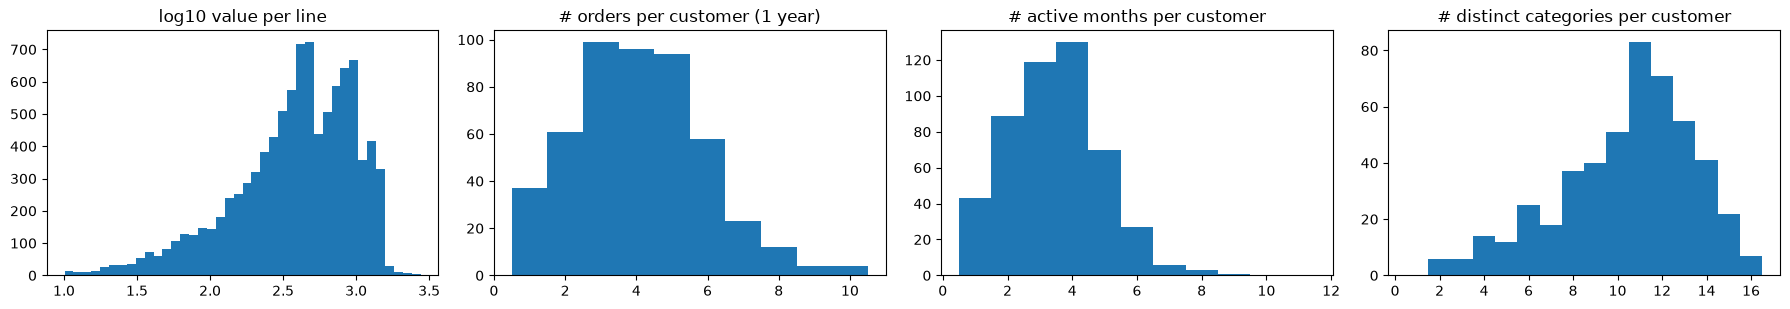

In [6]:
def iqr_flags(s, k=3.0):
    q1, q3 = s.quantile([.25, .75]); lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
    return (s < lo) | (s > hi), lo, hi
for col in ['value_proxy', 'quantity']:
    m, lo, hi = iqr_flags(df[col])
    print(f'{col:12s}: {m.sum():4d} rows ({m.mean():.1%}) outside 3*IQR [{lo:.0f}, {hi:.0f}]')

cust = df.groupby('cust_id').agg(n_orders=('order_id', 'nunique'), n_lines=('order_id', 'size'), n_months=('month', 'nunique'),
                                 n_cats=('cat_id', 'nunique'), n_prods=('prod_id', 'nunique'))
print('\nPer-customer activity:'); print(cust.describe().T[['mean', '50%', 'min', 'max']].round(2).to_string())

fig, ax = plt.subplots(1, 4, figsize=(18, 3.2))
ax[0].hist(np.log10(df['value_proxy']), bins=40); ax[0].set_title('log10 value per line')
ax[1].hist(cust['n_orders'], bins=np.arange(0.5, cust.n_orders.max() + 1.5)); ax[1].set_title('# orders per customer (1 year)')
ax[2].hist(cust['n_months'], bins=np.arange(0.5, 12.5)); ax[2].set_title('# active months per customer')
ax[3].hist(cust['n_cats'], bins=np.arange(0.5, 17.5)); ax[3].set_title('# distinct categories per customer')
plt.tight_layout(); plt.show()

**Insight (outliers and activity).** Only 4 merged lines fall outside 3×IQR on value (they are merged split lines), and none on quantity. **Decision: keep all rows.**

Activity is the important number: the median customer places **4 orders in the year, in 3 of 12 months**, yet already touches **11 of 17 categories**. Baskets are wide (~5 lines over ~4 categories), so a single order covers a quarter of the catalogue. Two consequences for the task: (1) in any month only ~28% of customers buy anything, so most customer–month targets are empty and evaluation must be restricted to customers who buy in t+1 (the standard next-basket protocol, as in EuroMart); (2) the customer–category graph will be **dense**, which Phase 2 quantifies.

### Phase 1 summary — column mapping

| Role | Column(s) | Notes |
|---|---|---|
| **Customer ID** | `customer_id` → `cust_id` | 488 customers; a real id |
| **Item (category level)** | `category` → `cat_id` | **17 values**, same item count as EuroMart's sub-category level |
| **Item (product level)** | `product_name` → `prod_id` | 68 products, 1–8 per category |
| **Interaction / event** | each row = purchase line | purchases only |
| **Timestamp** | `event_time` → `month`, `m_idx` | minute resolution, 2024-01 → 2024-12 (12 months) |
| **Customer attributes** | none | no segment / location; all features come from history (incl. time-of-day and weekend shares) |
| **Transaction attributes** | `quantity`, `value_proxy` | used for spend/quantity summaries only |

**Rows:** 10,000 → 9,701 (299 split lines merged, 0 dropped).

## Phase 2 — Graph feasibility audit

**What:** build the customer–item bipartite graph at two item granularities (Category 17, Product 68), aggregating repeat purchases into one weighted edge. For each: size, density, degree statistics, connected components, degree-1 share, 5-core/10-core survival and repeat rates.

**Why:** the same decision gates as EuroMart. A near-complete graph gives message passing nothing to discriminate, and a graph that collapses under k-core filtering is too sparse. The audit uses the full-year graph because it is descriptive only; no model sees it.

In [7]:
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components

LEVELS = {'category': 'cat_id', 'product': 'prod_id'}

def bipartite_edges(d, item_col):
    """one edge per (customer, item); weight = #lines, #orders, spend, quantity"""
    return d.groupby(['cust_id', item_col]).agg(n_lines=('order_id', 'size'), n_orders=('order_id', 'nunique'),
                                               spend=('value_proxy', 'sum'), qty=('quantity', 'sum')).reset_index()

def kcore_bipartite(e, item_col, k):
    e = e[['cust_id', item_col]]
    while True:
        du = e.groupby('cust_id').size(); di = e.groupby(item_col).size()
        keep = e['cust_id'].map(du).ge(k) & e[item_col].map(di).ge(k)
        if keep.all(): return e
        e = e[keep]

def graph_stats(d, item_col):
    e = bipartite_edges(d, item_col)
    U, I, E = d['cust_id'].nunique(), d[item_col].nunique(), len(e)
    du, di = e.groupby('cust_id').size(), e.groupby(item_col).size()
    uid = e['cust_id'].astype('category').cat.codes.values.astype(np.int64)
    iid = e[item_col].astype('category').cat.codes.values.astype(np.int64) + U     # int64: avoids the int8 overflow seen in EuroMart
    A = sp.coo_matrix((np.ones(E), (uid, iid)), shape=(U + I, U + I))
    ncomp, lab = connected_components(A, directed=False)
    out = {'|U|': U, '|I|': I, '|E|': E, 'density': E / (U * I),
           'cust deg mean': du.mean(), 'cust deg median': du.median(), 'item deg mean': di.mean(), 'item deg median': di.median(),
           'components': ncomp, 'largest comp %': np.bincount(lab).max() / (U + I),
           '% cust deg=1': (du == 1).mean(), '% items deg=1': (di == 1).mean(),
           'repeat-edge rate': (e['n_orders'] > 1).mean(),
           'repeat-purchase share': 1 - E / e['n_orders'].sum()}
    for k in (5, 10):
        kc = kcore_bipartite(e, item_col, k)
        out[f'{k}-core cust %'] = kc['cust_id'].nunique() / U
        out[f'{k}-core item %'] = kc[item_col].nunique() / I
    return out, e

stats, edges = {}, {}
for name, col in LEVELS.items():
    stats[name], edges[name] = graph_stats(df, col)
stats_df = pd.DataFrame(stats)
fmt = stats_df.copy().astype(object)
for r in stats_df.index:
    fmt.loc[r] = [f'{v:.1%}' if ('%' in r or 'rate' in r or 'share' in r or r == 'density') else (f'{v:,.0f}' if float(v).is_integer() else f'{v:,.2f}') for v in stats_df.loc[r]]
fmt

,category,product
|U|,488,488
|I|,17,68
|E|,"5,084","8,457"
density,61.3%,25.5%
cust deg mean,10.42,17.33
cust deg median,11,17
item deg mean,299.06,124.37
item deg median,324,125
components,1,1
largest comp %,100.0%,100.0%


**Insight (structure).**

| | Category (17) | Product (68) |
|---|---|---|
| density | **61%** | **25.5%** |
| median customer degree | 11 of 17 | 17 of 68 |
| repeat-edge rate | 45% | 13% |
| 10-core survival (customers) | 68% | 86% |

- Both graphs are a **single connected component** with **no degree-1 nodes**, and every item survives the 10-core. Unlike EuroMart there is no sparsity problem at either level.
- **Category level is dense** (61%, vs 40% for EuroMart sub-categories): the median customer has already bought 11 of the 17 categories within one year. Ranking will be about the *remaining* few categories plus repeats.
- **Product level is workable here** (EuroMart's product level was 0.6% dense with 0.4% repeats; here 25% and 13%), because there are only 68 products.

*Decision:* keep **Category (17 items)** as the prediction level. It matches the task ("which categories next period"), and it keeps the item count identical to the EuroMart sub-category run, so the two datasets are directly comparable. Product level is used below only as a diagnostic for whether finer-grained structure exists.

*Next:* degree distributions.

**What:** customer and item degree histograms per level (log-scaled counts), plus the list of category degrees.

**Why:** GAT learns its own neighbour weights, but skewed item degrees still matter: hub items send messages to almost every customer. The shape shows whether there are hubs and a long tail where learned weighting could help.

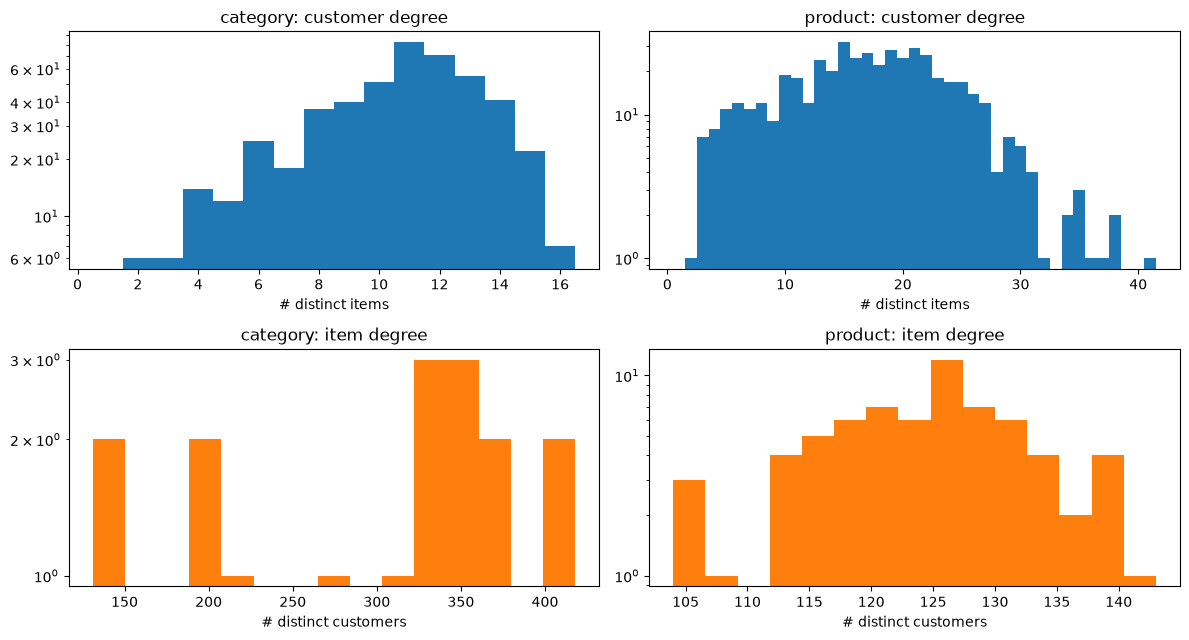

category degrees (customers per category):
cat_id
Fruits & Vegetables     418
Grains & Staples        415
Household               372
Bakery                  366
Dairy & Eggs            359
Beverages               352
Electronics             351
Snacks                  333
Personal Care           324
Meat & Seafood          323
Clothing                322
Stationery              270
Baby Care               220
Health & Wellness       202
Books                   189
Clothing Accessories    137
Footwear                131

products per category: {'Fruits & Vegetables': 8, 'Grains & Staples': 8, 'Household': 5, 'Beverages': 5, 'Dairy & Eggs': 5, 'Electronics': 5, 'Bakery': 5, 'Snacks': 4, 'Clothing': 4, 'Personal Care': 4, 'Meat & Seafood': 4, 'Stationery': 3, 'Baby Care': 2, 'Health & Wellness': 2, 'Books': 2, 'Clothing Accessories': 1, 'Footwear': 1}


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for j, (name, col) in enumerate(LEVELS.items()):
    e = edges[name]
    du, di = e.groupby('cust_id').size(), e.groupby(col).size()
    axes[0, j].hist(du, bins=np.arange(1, du.max() + 2) - 0.5, color='tab:blue')
    axes[0, j].set_yscale('log'); axes[0, j].set_title(f'{name}: customer degree'); axes[0, j].set_xlabel('# distinct items')
    axes[1, j].hist(di, bins=15, color='tab:orange')
    axes[1, j].set_yscale('log'); axes[1, j].set_title(f'{name}: item degree'); axes[1, j].set_xlabel('# distinct customers')
plt.tight_layout(); plt.show()
cat_names = df.drop_duplicates('cat_id').set_index('cat_id')['category'].sort_index()
print('category degrees (customers per category):')
print(edges['category'].groupby('cat_id').size().rename(index=cat_names.to_dict()).sort_values(ascending=False).to_string())
print('\nproducts per category:', df.groupby('category')['prod_id'].nunique().sort_values(ascending=False).to_dict())

**Insight (degrees).** Customer degree at category level is bell-shaped around 10–11 of 17, with no heavy tail. Item degrees fall into tiers: Fruits & Vegetables and Grains & Staples (~415 customers, 85%), a large middle block of 11 categories (320–370), and a weak tail of Baby Care, Health & Wellness, Books, Clothing Accessories and Footwear (130–220). There is no long tail at product level either: every product is bought by many customers.

The category tiers line up suspiciously well with **how many products each category has** (8, 8, 5, 5, …, 1, 1). *Next:* test that directly.

**What:** lines per product, and lines per category divided by the number of products in it.

**Why:** if every product is drawn with (almost) equal probability, category popularity is just "number of products in the category", a fixed catalogue property rather than a customer behaviour.

In [9]:
lines_per_prod = df.groupby('prod_id').size()
print(f'lines per product: mean {lines_per_prod.mean():.1f}, std {lines_per_prod.std():.1f}, CV {lines_per_prod.std() / lines_per_prod.mean():.3f} '
      f'(CV expected under uniform random sampling = 1/sqrt(mean) = {1 / np.sqrt(lines_per_prod.mean()):.3f})')
lc = df.groupby('category').agg(lines=('order_id', 'size'), products=('prod_id', 'nunique'))
lc['lines per product'] = (lc.lines / lc.products).round(1)
print(f'corr(# products in category, # lines in category) = {np.corrcoef(lc.lines, lc.products)[0, 1]:.3f}')
lc.sort_values('lines', ascending=False).T

lines per product: mean 142.7, std 10.5, CV 0.074 (CV expected under uniform random sampling = 1/sqrt(mean) = 0.084)
corr(# products in category, # lines in category) = 0.998


category,Grains & Staples,Fruits & Vegetables,Bakery,Household,Beverages,Dairy & Eggs,Electronics,Snacks,Meat & Seafood,Personal Care,Clothing,Stationery,Baby Care,Health & Wellness,Books,Footwear,Clothing Accessories
lines,1152.0,1125.0,743.0,741.0,722.0,716.0,707.0,588.0,583.0,564.0,548.0,402.0,295.0,273.0,242.0,152.0,148.0
products,8.0,8.0,5.0,5.0,5.0,5.0,5.0,4.0,4.0,4.0,4.0,3.0,2.0,2.0,2.0,1.0,1.0
lines per product,144.0,140.6,148.6,148.2,144.4,143.2,141.4,147.0,145.8,141.0,137.0,134.0,147.5,136.5,121.0,152.0,148.0


**Insight (catalogue effect). This is the first strong hint about the data-generating process.** Every product is sold on 143 ± 10 lines: the spread (CV 0.074) is *smaller* than pure random sampling would produce (0.084). Category volume is almost perfectly explained by the number of products in it (r = 0.998). So **category popularity is a catalogue artefact**: each line picks a product (close to) uniformly at random, and a category with 8 products simply gets 8× the lines of a category with 1. Popularity will therefore be a strong, stable ranker, and it is known in advance.

*Next:* the time dimension. How many periods are usable and how many customers are active in each, for monthly and quarterly periods.

**What:** for monthly and quarterly periods: active customers per period, new (first-seen) customers, and the share of active customers already seen before.

**Why:** a period is usable as a target only if it has enough active customers with prior history. Customers first seen in t+1 are cold-start and cannot be scored by a transductive model.

MONTH: 12 periods | active/period mean 140 (min 130, max 156) | active as % of 488: 28.8%
QUARTER: 4 periods | active/period mean 313 (min 303, max 321) | active as % of 488: 64.1%


,period,active,new,returning,cum_seen,pct_returning,pct_seen
0,2024-01,152,152,0,152,0.000,0.311
1,2024-02,131,88,43,240,0.328,0.492
2,2024-03,140,79,61,319,0.436,0.654
3,2024-04,140,50,90,369,0.643,0.756
4,2024-05,145,36,109,405,0.752,0.830
5,2024-06,136,24,112,429,0.824,0.879
6,2024-07,144,19,125,448,0.868,0.918
7,2024-08,156,16,140,464,0.897,0.951
8,2024-09,130,6,124,470,0.954,0.963
9,2024-10,139,8,131,478,0.942,0.980


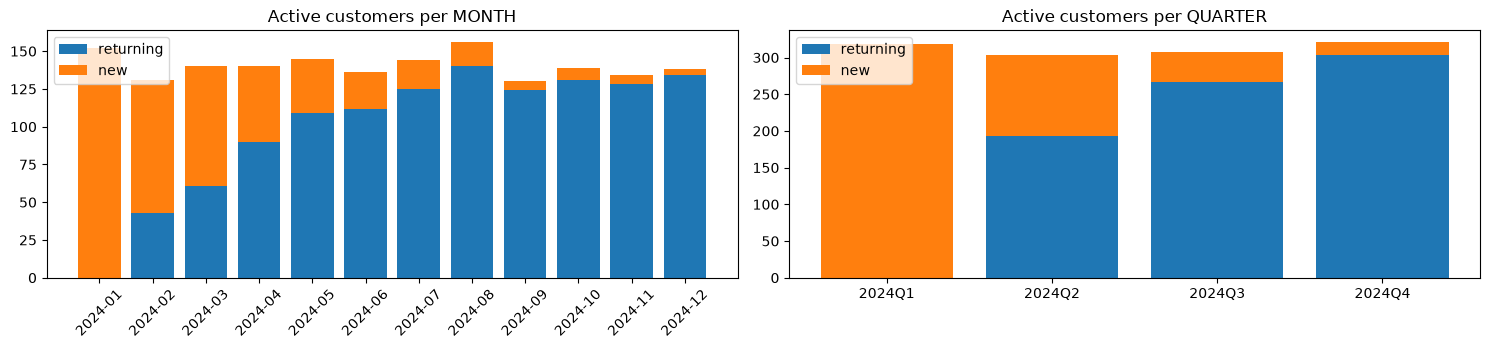

In [10]:
df['quarter'] = df['event_time'].dt.to_period('Q')
N_CUST = df['cust_id'].nunique()

def temporal_profile(period_col):
    rows, seen = [], set()
    for p, g in df.groupby(period_col, sort=True):
        act = set(g['cust_id']); new = act - seen
        rows.append({'period': str(p), 'active': len(act), 'new': len(new), 'returning': len(act & seen), 'cum_seen': len(seen | act)})
        seen |= act
    t = pd.DataFrame(rows); t['pct_returning'] = t['returning'] / t['active']
    return t

tm, tq = temporal_profile('month'), temporal_profile('quarter')
for name, t in [('MONTH', tm), ('QUARTER', tq)]:
    print(f'{name}: {len(t)} periods | active/period mean {t.active.mean():.0f} (min {t.active.min()}, max {t.active.max()}) '
          f'| active as % of {N_CUST}: {t.active.mean() / N_CUST:.1%}')
display(tm.assign(pct_returning=tm.pct_returning.round(3), pct_seen=(tm.cum_seen / N_CUST).round(3)))

fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
ax[0].bar(range(len(tm)), tm['returning'], label='returning'); ax[0].bar(range(len(tm)), tm['new'], bottom=tm['returning'], label='new')
ax[0].set_xticks(range(len(tm))); ax[0].set_xticklabels(tm.period, rotation=45); ax[0].set_title('Active customers per MONTH'); ax[0].legend()
ax[1].bar(range(len(tq)), tq['returning'], label='returning'); ax[1].bar(range(len(tq)), tq['new'], bottom=tq['returning'], label='new')
ax[1].set_xticks(range(len(tq))); ax[1].set_xticklabels(tq.period); ax[1].set_title('Active customers per QUARTER'); ax[1].legend()
plt.tight_layout(); plt.show()

**Insight (time).** All 12 months have data and activity is **flat**: 130–156 active customers per month (~29% of 488), with no visible seasonal peak (EuroMart had a clear Q3/Q4 surge). New customers arrive fast: 49% seen by February, 83% by May, 95% by August, so from September onward only 4–8 active customers per month are cold-start.

*Decision on periods:* **monthly**. Quarters would give only 3 target periods (impossible to split into train/val/test). Monthly gives 11 targets with ~125–135 evaluable returning customers each in the second half of the year. That is a small evaluation set, so the statistical-power caveats from EuroMart apply even more here.

*Next:* relationship diagnostics, starting with Jaccard overlap against a degree-preserving null.

**What:** Jaccard similarity |N(u)∩N(v)| / |N(u)∪N(v)| between the item neighbourhoods of 20,000 random customer pairs, at both levels, compared with a **degree-preserving null built by random double-edge swaps** (u1–i1, u2–i2 → u1–i2, u2–i1, rejected if it would create a duplicate edge). This keeps every customer's degree and every item's popularity *exactly*.

**Why:** collaborative signal exists only if real neighbourhoods overlap more than chance. *Carried over from EuroMart:* the naive "shuffle the item column" null is biased at dense levels (it creates duplicates whose removal lowers degrees), so I go straight to the edge-swap null. The category graph here is 61% dense, where that bias would be worst.

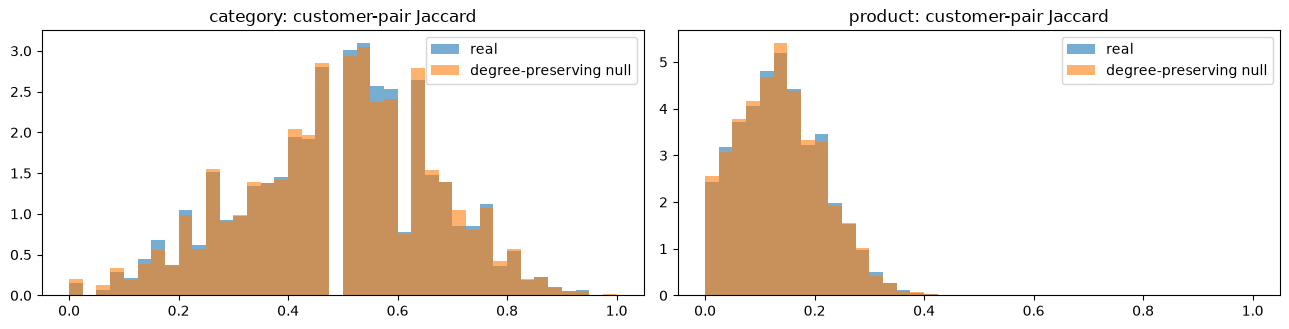

,category,product
accepted swaps,4221.0000,42166.0000
real mean J,0.4906,0.1369
null mean J,0.4914,0.1358
ratio,0.9984,1.0086
real 90th pct,0.7143,0.2400
null 90th pct,0.7143,0.2381


In [11]:
rng = np.random.default_rng(SEED)
def jaccard_sample(e, item_col, n_pairs=20000, rng=rng):
    nb = e.groupby('cust_id')[item_col].apply(frozenset)
    ids = nb.index.values
    a, b = rng.choice(ids, n_pairs), rng.choice(ids, n_pairs)
    m = a != b
    return np.array([len(nb[x] & nb[y]) / len(nb[x] | nb[y]) for x, y in zip(a[m], b[m])])

def edge_swap_null(e, item_col, n_swaps_per_edge=10, rng=None):
    rng = rng if rng is not None else np.random.default_rng(SEED)
    u = e['cust_id'].to_numpy().copy(); it = e[item_col].to_numpy().copy()
    present = set(zip(u, it)); E = len(u); done = 0
    for _ in range(n_swaps_per_edge * E):
        a, b = rng.integers(E, size=2)
        if u[a] == u[b] or it[a] == it[b]: continue
        if (u[a], it[b]) in present or (u[b], it[a]) in present: continue
        present -= {(u[a], it[a]), (u[b], it[b])}; present |= {(u[a], it[b]), (u[b], it[a])}
        it[a], it[b] = it[b], it[a]; done += 1
    return pd.DataFrame({'cust_id': u, item_col: it}), done

rows = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, (name, col) in zip(axes, LEVELS.items()):
    e = edges[name][['cust_id', col]]
    null_e, done = edge_swap_null(e, col)
    assert (null_e.groupby('cust_id').size().sort_index().values == e.groupby('cust_id').size().sort_index().values).all()
    assert (null_e.groupby(col).size().sort_index().values == e.groupby(col).size().sort_index().values).all()
    real = jaccard_sample(e, col, rng=np.random.default_rng(1)); null = jaccard_sample(null_e, col, rng=np.random.default_rng(1))
    rows[name] = {'accepted swaps': done, 'real mean J': real.mean(), 'null mean J': null.mean(), 'ratio': real.mean() / null.mean(),
                  'real 90th pct': np.quantile(real, .9), 'null 90th pct': np.quantile(null, .9)}
    bins = np.linspace(0, 1, 41)
    ax.hist(real, bins=bins, alpha=.6, density=True, label='real'); ax.hist(null, bins=bins, alpha=.6, density=True, label='degree-preserving null')
    ax.set_title(f'{name}: customer-pair Jaccard'); ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(4)

**Insight (Jaccard).** Real and null overlap are **identical at both levels**: ratio 0.998 (category) and 1.009 (product), with the same 90th percentiles. The asserts confirm degrees are preserved exactly. (At category level the graph is so dense that only 4.2k of 51k proposed swaps are valid, i.e. each edge moves ~1.7 times; the identical 90th percentiles suggest that is enough mixing.)

*Meaning:* the same signature as EuroMart. Once you know how many categories a customer buys and how popular each category is, **who buys what together looks random**. *Next:* pairwise item associations (lift), the structure a 2-hop path item → customer → item could exploit.

**What:** category co-occurrence **lift** = P(a,b) / (P(a)P(b)) over (i) customer baskets (all-time sets) and (ii) order baskets, compared with the lift matrix of the edge-swap null graph.

**Why:** lift ≠ 1 for specific pairs (e.g. Baby Care with Dairy & Eggs, or Clothing with Footwear) would be item–item structure that the global Jaccard could hide.

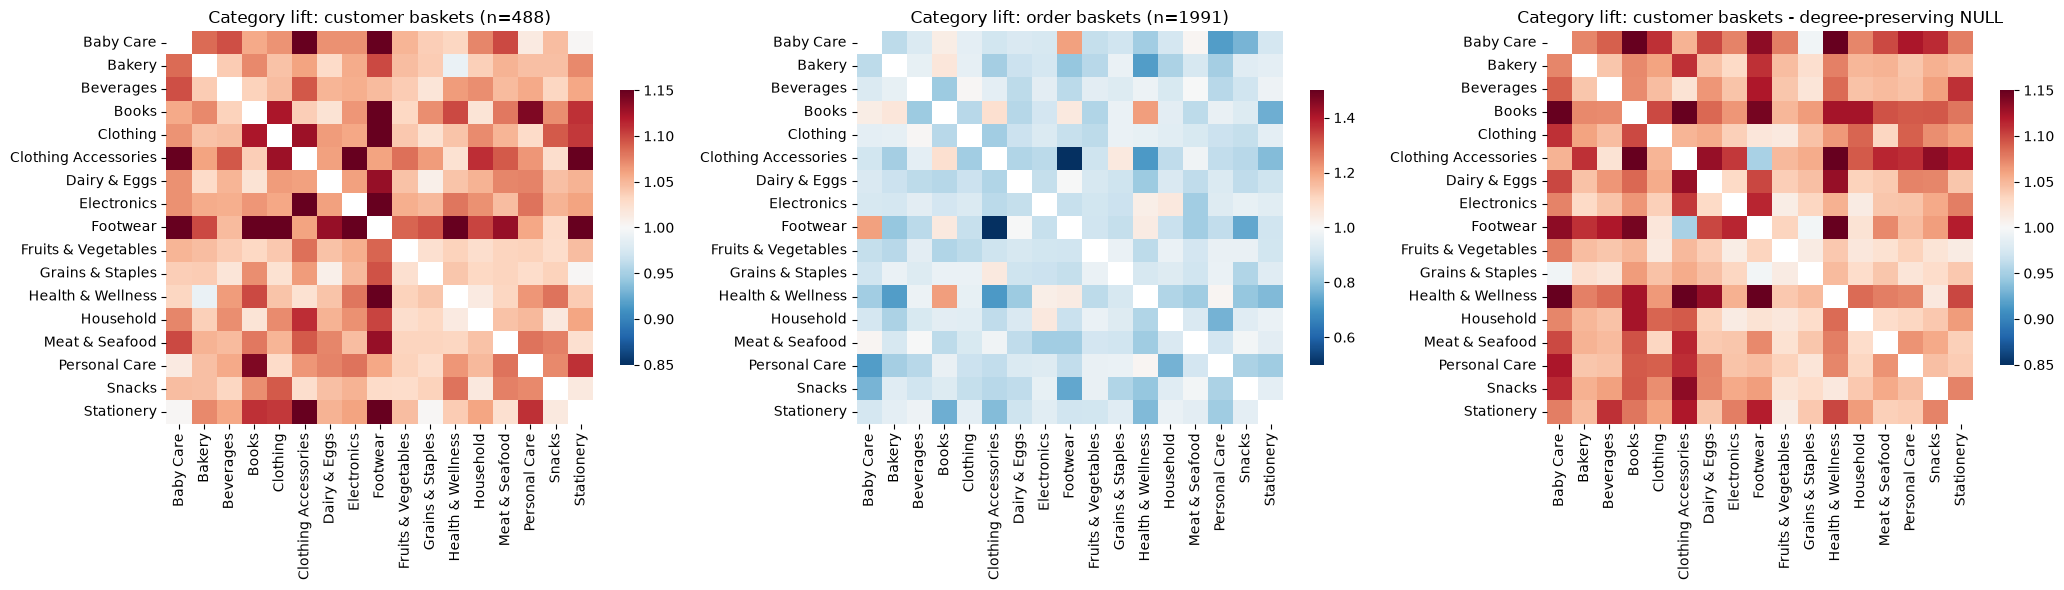

customer  lift: mean 1.066  std 0.049  min 0.99  max 1.31
order     lift: mean 0.906  std 0.089  min 0.44  max 1.21
null      lift: mean 1.067  std 0.046  min 0.95  max 1.36

strongest order-level pairs: [('Books', 'Health & Wellness', np.float64(1.21)), ('Baby Care', 'Footwear', np.float64(1.2)), ('Books', 'Clothing Accessories', np.float64(1.08)), ('Bakery', 'Books', np.float64(1.06))]
weakest  order-level pairs: [('Baby Care', 'Personal Care', np.float64(0.72)), ('Bakery', 'Health & Wellness', np.float64(0.72)), ('Clothing Accessories', 'Health & Wellness', np.float64(0.71)), ('Clothing Accessories', 'Footwear', np.float64(0.44))]


In [12]:
K = len(cat_names)
def lift_matrix(baskets_df, key, item_col='cat_id'):
    X = pd.crosstab(baskets_df[key], baskets_df[item_col]).clip(upper=1).reindex(columns=range(K), fill_value=0).values.astype(float)
    n = len(X); p = X.mean(0); co = (X.T @ X) / n
    L = co / np.outer(p, p); np.fill_diagonal(L, np.nan)
    return L, n

L_cust, n_c = lift_matrix(df[['cust_id', 'cat_id']], 'cust_id')
L_order, n_o = lift_matrix(df[['order_id', 'cat_id']], 'order_id')
null_e, _ = edge_swap_null(edges['category'][['cust_id', 'cat_id']], 'cat_id', rng=np.random.default_rng(7))
L_null, _ = lift_matrix(null_e, 'cust_id')

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, L, title in zip(axes, [L_cust, L_order, L_null], [f'customer baskets (n={n_c})', f'order baskets (n={n_o})', 'customer baskets - degree-preserving NULL']):
    sns.heatmap(L, ax=ax, cmap='RdBu_r', center=1, vmin=0.5 if 'order' in title else 0.85, vmax=1.5 if 'order' in title else 1.15,
                xticklabels=cat_names.values, yticklabels=cat_names.values, cbar_kws={'shrink': .7})
    ax.set_title('Category lift: ' + title)
plt.tight_layout(); plt.show()
off = ~np.eye(K, dtype=bool)
for nm, L in [('customer', L_cust), ('order', L_order), ('null', L_null)]:
    v = L[off]; print(f'{nm:9s} lift: mean {np.nanmean(v):.3f}  std {np.nanstd(v):.3f}  min {np.nanmin(v):.2f}  max {np.nanmax(v):.2f}')
iu = np.triu_indices(K, 1)
top = sorted(zip(L_order[iu], cat_names.values[iu[0]], cat_names.values[iu[1]]), reverse=True)
print('\nstrongest order-level pairs:', [(a, b, round(l, 2)) for l, a, b in top[:4]])
print('weakest  order-level pairs:', [(a, b, round(l, 2)) for l, a, b in top[-4:]])

**Insight (lift).** The customer-basket lift matrix is indistinguishable from the null (mean 1.066 vs 1.067, std 0.049 vs 0.046). Values sit slightly above 1 only because heavy buyers co-occur with everything. Order-level lift averages *below* 1 (0.91): an order has ~4 categories, so including one category leaves less room for any particular other one. The "strongest" order pairs (Books–Health & Wellness 1.21, Baby Care–Footwear 1.20) and the weakest (Clothing Accessories–Footwear 0.44) all involve the smallest categories, where cells are tiny; they are not intuitive pairings (e.g. clothing accessories *avoid* footwear) and look like noise. **No item–item co-preference structure beyond popularity.**

*Next:* temporal persistence, the signal a next-period model needs most.

**What:** for consecutive months (t, t+1), using customers active in **both** periods:
- persistence = P(buy c in t+1 | bought c in t) vs baseline P(buy c in t+1 | not bought in t)
- the same contrast with the **full history** (bought c at any time ≤ t)

plus target sparsity (evaluable customers per t+1 and positives per customer). Computed at category and product level, monthly and quarterly.

**Why:** persistence > baseline means repeat-style baselines are strong and history matters. Raw persistence is confounded by popularity and volume, which is tested next.

In [13]:
def persistence(period_col, item_col):
    periods = sorted(df[period_col].unique())
    sets = df.groupby([period_col, 'cust_id'])[item_col].apply(set)
    hist = {}
    agg = dict(pers_n=0, pers_k=0, base_n=0, base_k=0, hp_n=0, hp_k=0, hb_n=0, hb_k=0)
    eval_custs, pos_per_cust = [], []
    n_items = df[item_col].nunique()
    for t, t1 in zip(periods[:-1], periods[1:]):
        cur = sets.loc[t].to_dict()
        for c, s in cur.items(): hist.setdefault(c, set()).update(s)
        nxt = sets.loc[t1].to_dict()
        ev = [c for c in nxt if c in hist]
        eval_custs.append(len(ev)); pos_per_cust += [len(nxt[c]) for c in ev]
        for c in ev:
            y, h = nxt[c], hist[c]
            agg['hp_n'] += len(h); agg['hp_k'] += len(h & y)
            agg['hb_n'] += n_items - len(h); agg['hb_k'] += len(y - h)
            if c in cur:
                x = cur[c]
                agg['pers_n'] += len(x); agg['pers_k'] += len(x & y)
                agg['base_n'] += n_items - len(x); agg['base_k'] += len(y - x)
    r = lambda k, n: agg[k] / max(agg[n], 1)
    return {'P(c|c in t)': r('pers_k', 'pers_n'), 'P(c|c not in t)': r('base_k', 'base_n'),
            'lift last-period': r('pers_k', 'pers_n') / max(r('base_k', 'base_n'), 1e-9),
            'P(c|c in history)': r('hp_k', 'hp_n'), 'P(c|c not in history)': r('hb_k', 'hb_n'),
            'lift history': r('hp_k', 'hp_n') / r('hb_k', 'hb_n'),
            'eval custs / period (mean)': np.mean(eval_custs), 'eval custs / period (min)': np.min(eval_custs),
            'positives / eval cust (mean)': np.mean(pos_per_cust), 'positives / eval cust (median)': np.median(pos_per_cust)}

res = {}
for per in ['month', 'quarter']:
    for name in ['category', 'product']:
        res[f'{per} | {name}'] = persistence(per, LEVELS[name])
pd.DataFrame(res).round(3)

,month | category,month | product,quarter | category,quarter | product
P(c|c in t),0.351,0.088,0.400,0.111
P(c|c not in t),0.245,0.080,0.320,0.110
lift last-period,1.434,1.102,1.249,1.013
P(c|c in history),0.330,0.085,0.394,0.109
P(c|c not in history),0.247,0.083,0.309,0.110
lift history,1.339,1.017,1.274,0.993
eval custs / period (mean),108.818,108.818,254.333,254.333
eval custs / period (min),43.000,43.000,193.000,193.000
positives / eval cust (mean),4.837,5.683,5.899,7.438
positives / eval cust (median),5.000,5.000,6.000,7.000


**Insight (persistence, raw).** At category level history *looks* predictive: P(c in t+1 | c in history) = 0.33 vs 0.25 otherwise (**lift 1.34**), and last-month-only lift is 1.43. At product level it is flat (lift 1.02 history, 1.10 last month). Target sparsity is much better than EuroMart because baskets are wide: **~109 evaluable customers per target month (min 43, in February) with ~5 positive categories each** (EuroMart: ~2 per customer-quarter).

**But raw lift is confounded**, exactly as in EuroMart: items in anyone's history are mostly the popular ones (which are also more likely next month for everyone), and heavy buyers have longer histories and bigger next baskets. *Next:* the controlled test.

**What:** logistic regression of y = 1[c bought in t+1] on **item fixed effects + log customer t+1 basket size + log history size + in_history**, over all (evaluable customer, item) pairs. The in_history odds ratio is persistence net of popularity and volume. Then a 95% interval via a **customer-cluster bootstrap** (200 reps) for the monthly category version.

**Why:** the same test that overturned the raw persistence in EuroMart (1.48 → 1.01). Diagnostic only: using the t+1 basket size is deliberate here and would be leakage in a model.

In [14]:
from sklearn.linear_model import LogisticRegression

def persistence_rows(period_col, item_col):
    periods = sorted(df[period_col].unique()); n_items = df[item_col].nunique()
    sets = df.groupby([period_col, 'cust_id'])[item_col].apply(set)
    hist, rows = {}, []
    for t, t1 in zip(periods[:-1], periods[1:]):
        for c, s in sets.loc[t].items(): hist.setdefault(c, set()).update(s)
        for c, y in sets.loc[t1].items():
            if c in hist:
                h = hist[c]
                rows += [(c, i, int(i in h), np.log(len(h)), np.log(len(y)), int(i in y)) for i in range(n_items)]
    return pd.DataFrame(rows, columns=['cust', 'item', 'in_hist', 'log_hist', 'log_basket', 'y'])

def controlled_or(R):
    X = pd.concat([pd.get_dummies(R['item'], prefix='it', drop_first=True, dtype=float), R[['log_hist', 'log_basket', 'in_hist']]], axis=1)
    m = LogisticRegression(C=1e6, max_iter=5000).fit(X.values, R['y'].values)
    coef = dict(zip(X.columns, m.coef_[0]))
    p1, p0 = R.query('in_hist==1').y.mean(), R.query('in_hist==0').y.mean()
    return {'rows': len(R), 'OR in_hist (controlled)': np.exp(coef['in_hist']), 'OR log basket_t1': np.exp(coef['log_basket']),
            'OR log hist_size': np.exp(coef['log_hist']), 'raw OR in_hist': (p1 / (1 - p1)) / (p0 / (1 - p0))}

PR = {f'{per} | {name}': persistence_rows(per, LEVELS[name]) for per in ['month', 'quarter'] for name in ['category', 'product']}
display(pd.DataFrame({k: controlled_or(R) for k, R in PR.items()}).round(3))

# customer-cluster bootstrap, month | category
R = PR['month | category']
Xfull = pd.concat([pd.get_dummies(R['item'], prefix='it', drop_first=True, dtype=float), R[['log_hist', 'log_basket', 'in_hist']]], axis=1).values
yfull = R['y'].values
cust_rows = R.groupby('cust').indices; custs = np.array(list(cust_rows))
boot_rng = np.random.default_rng(SEED); ors = []
t0 = time.time()
for b in range(200):
    pick = boot_rng.choice(custs, len(custs))
    idx = np.concatenate([cust_rows[c] for c in pick])
    ors.append(np.exp(LogisticRegression(C=1e6, max_iter=3000).fit(Xfull[idx], yfull[idx]).coef_[0][-1]))
ors = np.array(ors)
print(f'controlled OR(in_hist), category, monthly: median {np.median(ors):.3f}, 95% CI [{np.quantile(ors, .025):.3f}, {np.quantile(ors, .975):.3f}]  ({time.time() - t0:.0f}s)')

,month | category,month | product,quarter | category,quarter | product
rows,20349.000,81396.000,12971.000,51884.000
OR in_hist (controlled),1.021,1.023,0.992,1.014
OR log basket_t1,4.918,3.042,5.779,3.140
OR log hist_size,0.984,0.996,1.004,0.997
raw OR in_hist,1.506,1.019,1.451,0.992


controlled OR(in_hist), category, monthly: median 1.016, 95% CI [0.945, 1.095]  (5s)


**Insight (controlled persistence). Same result as EuroMart.** After controlling for item popularity and the customer's next-period basket size, the odds ratio for "c is in the customer's history" collapses from **1.51 → 1.02** (category, monthly) and 1.45 → 0.99 (quarterly); at product level it is ~1.0 both raw and controlled. The cluster bootstrap gives **OR = 1.016, 95% CI [0.945, 1.095]**, which includes 1. History size adds nothing (OR ≈ 1.0); next-basket size dominates (OR ≈ 5 per log unit): "customers who buy more buy more of everything".

### Phase 2 summary and recommendation

| Gate | **Category (17)** | Product (68) |
|---|---|---|
| density | 61% (dense, but not degenerate) | 25.5% |
| connectivity / degree-1 customers | 1 comp / 0% | 1 comp / 0% |
| 5-core / 10-core customers kept | 95% / 68% | 97% / 86% |
| repeat-edge rate | 45% | 13% |
| Jaccard real ÷ degree-preserving null | **1.00** | **1.01** |
| category lift std, real vs null | 0.049 vs 0.046 | — |
| raw → controlled persistence OR (monthly) | 1.51 → **1.02** [0.95, 1.10] | 1.02 → 1.02 |
| category volume explained by # products | r = 0.998 | lines/product CV 0.074 (≈ uniform sampling) |

**Recommendation: Category level (17 items) with monthly periods.** It answers the task directly and keeps the setup comparable with EuroMart (17 items). Monthly is the only granularity with enough target periods in one year.

**Expectation set now:** this dataset shows **no collaborative, item–item or temporal signal beyond popularity and customer volume**, and the popularity itself is a catalogue artefact (products are sampled near-uniformly). That is an even cleaner "independent draws" signature than EuroMart. I expect **Popularity to be close to optimal and GAT at best to match it**. The pipeline is still run in full, because it tests this rigorously and the GAT attention analysis can show *what* the model learns when there is nothing beyond popularity to learn.

## Research questions and hypotheses (stated before any modelling)

Shopping question: *for each category, what % of customers will buy it next month, and which customers?* The model output, a customer × category probability matrix P, answers both: a column mean of P is the expected % buying that category, and the row ranking says who.

| ID | Hypothesis | How it is tested |
|---|---|---|
| **H1** | GAT (graph structure) beats the non-graph baselines | test **NDCG@5 (headline)**, plus Recall / Precision / HitRate / NDCG @3, @5, @10 and PR-AUC; seeds 42, 43, 44; gap must exceed seed std; plus paired bootstrap |
| **H2** | GAT's learned neighbour weights help most for low-degree customers | per-degree-bin NDCG@5 vs popularity |
| **H3** | A customer's own history raises their chance of rebuying a category | Phase 2 controlled OR (already 1.02, CI [0.95, 1.10]: **not supported**) |
| **H4** | The % of customers buying each category next month can be predicted accurately | predicted vs actual % per category on test months (MAE in pp) |
| **H5** | *When* people shop (weekend vs weekday, time of day) changes *what* they buy | χ² test of shopper daypart × category (replaces EuroMart's Segment test: this dataset has no customer attributes) |
| **H6** | Purchasing is seasonal by month | % of customers active by month (χ²) and category mix by month |

*Prior from Phase 2:* H1 and H2 unlikely; H4 likely, since popularity is stable.

## Phase 3 — Leakage-safe split and features

**What:** months indexed 0–11 (2024-01 … 2024-12). A *sample* is a snapshot pair (graph G_t from all data in months ≤ t, targets Y_{t+1}). The split is on the **target month**, on whole-month boundaries:
- train targets: months 1–7 (Feb–Aug); all data used is ≤ month 7
- validation targets: months 8–9 (Sep–Oct)
- test targets: months 10–11 (Nov–Dec)

That is 8 / 2 / 2 months of data = 67 / 17 / 17%, the closest whole-month version of 70/15/15 that leaves 2 test periods.

This is the group protocol: **12 months = Train 8 / Validation 2 / Test 2**.

In [15]:
Q_END = {i: m.end_time for i, m in enumerate(MONTHS)}
TRAIN_T1, VAL_T1, TEST_T1 = list(range(1, 8)), [8, 9], [10, 11]
SPLIT_OF = {**{t: 'train' for t in TRAIN_T1}, **{t: 'val' for t in VAL_T1}, **{t: 'test' for t in TEST_T1}}
N_ITEMS = df['cat_id'].nunique()
ITEM_NAMES = cat_names.values
print(pd.DataFrame({'target month': [str(MONTHS[t]) for t in SPLIT_OF], 'split': list(SPLIT_OF.values()),
                    'history up to': [str(MONTHS[t - 1]) for t in SPLIT_OF]}).groupby('split', sort=False)
      .agg(first=('target month', 'first'), last=('target month', 'last'), n=('target month', 'size'), history_through=('history up to', 'last')))

         first     last  n history_through
split                                     
train  2024-02  2024-08  7         2024-07
val    2024-09  2024-10  2         2024-09
test   2024-11  2024-12  2         2024-11


**What:** `build_snapshot(t)` uses **only rows with m_idx ≤ t** to build:
- *eligible customers*: everyone seen at or before t (customers first seen in t+1 are cold-start, excluded and counted).
- *customer features* (raw, unscaled; all history-derived because there are no static attributes): log #orders, log spend, log quantity, #distinct categories, #distinct products, tenure (months since first purchase), recency (months since last purchase), active-in-t flag, mean lines per order, log mean value per line, and shopping-time shares (weekend, morning < 12:00, evening ≥ 17:00).
- *edges* customer–category with #orders, spend and quantity.
- *pair features* (n_cust × 17) for the baselines: lifetime count, count in month t, months since last bought, share of the customer's orders.
- *labels* Y (n_cust × 17) = 1 if bought in t+1.

An in-function assert checks that the latest date used is ≤ the end of month t and the earliest label date is after it.

In [16]:
CUST_FEATS = ['log_orders', 'log_spend', 'log_qty', 'n_cats', 'n_prods', 'tenure_m', 'recency_m', 'active_t',
              'lines_per_order', 'log_line_value', 'share_weekend', 'share_morning', 'share_evening']
BINARY_FEATS = ['active_t']
df['weekend'] = (df['event_time'].dt.dayofweek >= 5).astype(float)
df['morning'] = (df['event_time'].dt.hour < 12).astype(float)
df['evening'] = (df['event_time'].dt.hour >= 17).astype(float)

def build_snapshot(t):
    hist = df[df.m_idx <= t]; tgt = df[df.m_idx == t + 1]
    assert hist['event_time'].max() <= Q_END[t] < tgt['event_time'].min(), 'temporal leakage!'
    custs = np.sort(hist['cust_id'].unique()); n = len(custs)
    cidx = pd.Series(np.arange(n), index=custs)
    g = hist.groupby('cust_id'); orders = hist.drop_duplicates('order_id').groupby('cust_id')
    X = pd.DataFrame(index=custs)
    X['log_orders'] = np.log1p(g['order_id'].nunique()); X['log_spend'] = np.log1p(g['value_proxy'].sum())
    X['log_qty'] = np.log1p(g['quantity'].sum()); X['n_cats'] = g['cat_id'].nunique(); X['n_prods'] = g['prod_id'].nunique()
    X['tenure_m'] = t - g['m_idx'].min(); X['recency_m'] = t - g['m_idx'].max()
    X['active_t'] = (X['recency_m'] == 0).astype(float)
    X['lines_per_order'] = g.size() / g['order_id'].nunique(); X['log_line_value'] = np.log(g['value_proxy'].mean())
    X['share_weekend'] = orders['weekend'].mean(); X['share_morning'] = orders['morning'].mean(); X['share_evening'] = orders['evening'].mean()
    X = X[CUST_FEATS]
    e = hist.groupby(['cust_id', 'cat_id']).agg(n_orders=('order_id', 'nunique'), spend=('value_proxy', 'sum'),
                                                qty=('quantity', 'sum'), last_m=('m_idx', 'max')).reset_index()
    e['u'] = cidx[e['cust_id']].values
    cnt = np.zeros((n, N_ITEMS)); cnt[e.u, e.cat_id] = e.n_orders
    rec = np.full((n, N_ITEMS), np.nan); rec[e.u, e.cat_id] = t - e.last_m
    last = hist[hist.m_idx == t].groupby(['cust_id', 'cat_id'])['order_id'].nunique()
    cnt_t = np.zeros((n, N_ITEMS)); cnt_t[cidx[last.index.get_level_values(0)].values, last.index.get_level_values(1)] = last.values
    share = cnt / np.maximum(np.expm1(X['log_orders'].values)[:, None], 1)
    tg = tgt[tgt.cust_id.isin(custs)]
    Y = np.zeros((n, N_ITEMS), dtype=np.int8); Y[cidx[tg.cust_id].values, tg.cat_id.values] = 1
    return dict(t=t, t1=t + 1, split=SPLIT_OF[t + 1], custs=custs, X=X, edges=e[['u', 'cat_id', 'n_orders', 'spend', 'qty']],
                cnt=cnt, cnt_t=cnt_t, rec=rec, share=share, Y=Y,
                n_cold=tgt.loc[~tgt.cust_id.isin(custs), 'cust_id'].nunique(), max_hist_date=hist['event_time'].max())

SNAP = {t1: build_snapshot(t1 - 1) for t1 in SPLIT_OF}
summary = pd.DataFrame([{'target': str(MONTHS[s['t1']]), 'split': s['split'], 'eligible custs': len(s['custs']),
                         'custs w/ positives': int((s['Y'].sum(1) > 0).sum()), 'cold-start excluded': s['n_cold'], 'edges': len(s['edges']),
                         'density': len(s['edges']) / (len(s['custs']) * N_ITEMS), 'pos rate (all eligible)': s['Y'].mean()} for s in SNAP.values()])
summary.round(3)

,target,split,eligible custs,custs w/ positives,cold-start excluded,edges,density,pos rate (all eligible)
0,2024-02,train,152,43,88,745,0.288,0.076
1,2024-03,train,240,61,79,1340,0.328,0.071
2,2024-04,train,319,90,50,1903,0.351,0.078
3,2024-05,train,369,109,36,2356,0.376,0.082
4,2024-06,train,405,112,24,2779,0.404,0.077
5,2024-07,train,429,125,19,3170,0.435,0.086
6,2024-08,train,448,140,16,3596,0.472,0.090
7,2024-09,val,464,124,6,3977,0.504,0.075
8,2024-10,val,470,131,8,4261,0.533,0.082
9,2024-11,test,478,128,6,4568,0.562,0.075


**Insight (snapshots).** 11 snapshots built and the in-function temporal assert passed for all. Eligible customers grow from 152 to 484 and graph density from 29% to 59% as history accumulates. Cold-start is large early (88 new customers in February) but **only 4–8 per month in val/test**. Customers with ≥ 1 positive: **val 124 + 131 = 255** customer-months, **test 128 + 134 = 262**. That is about 40% of EuroMart's evaluation size, so expect wider noise bands (NDCG@5 SE ≈ 0.02). The positive rate over all eligible cells is 7–9%.

*Next:* standardise continuous customer features with statistics from **training snapshots only**, then run the explicit leakage checks.

In [17]:
CONT_FEATS = [c for c in CUST_FEATS if c not in BINARY_FEATS]
train_X = pd.concat([SNAP[t]['X'] for t in TRAIN_T1])
SCALER = {'mean': train_X[CONT_FEATS].mean(), 'std': train_X[CONT_FEATS].std().replace(0, 1)}
for s in SNAP.values():
    Xs = s['X'].copy(); Xs[CONT_FEATS] = (Xs[CONT_FEATS] - SCALER['mean']) / SCALER['std']
    s['Xs'] = Xs.values.astype(np.float32)

# ---------------- explicit leakage checks ----------------
for t1, s in SNAP.items():
    assert s['max_hist_date'] <= Q_END[t1 - 1], f'snapshot {t1}: features use data after t'
    assert np.isnan(s['rec']).sum() + (s['rec'] >= 0).sum() == s['rec'].size, 'negative recency => future data'
    tgt_dates = df.loc[(df.m_idx == t1) & df.cust_id.isin(s['custs']), 'event_time']
    assert tgt_dates.min() > Q_END[t1 - 1] and tgt_dates.max() <= Q_END[t1]
assert all(SNAP[t]['max_hist_date'] <= Q_END[max(TRAIN_T1)] for t in TRAIN_T1)      # scaler only sees training-period data
assert len(train_X) == sum(len(SNAP[t]['custs']) for t in TRAIN_T1)
assert min(VAL_T1) > max(TRAIN_T1) and min(TEST_T1) > max(VAL_T1)
# strongest check: rebuild snapshots after deleting every row later than t+1
for t1 in [3, 8, 10]:
    saved = df
    try:
        df = saved[saved.m_idx <= t1].copy()
        s2 = build_snapshot(t1 - 1)
    finally:
        df = saved
    assert np.allclose(s2['X'].values, SNAP[t1]['X'].values) and (s2['Y'] == SNAP[t1]['Y']).all()
print('All leakage checks passed.')
print('scaler mean (train only):'); print(SCALER['mean'].round(2).to_string())

All leakage checks passed.
scaler mean (train only):
log_orders         1.03
log_spend          8.33
log_qty            2.87
n_cats             6.73
n_prods            9.18
tenure_m           2.43
recency_m          1.21
lines_per_order    4.88
log_line_value     6.23
share_weekend      0.28
share_morning      0.37
share_evening      0.33


**Insight (leakage).** Every check passed, including the strongest: rebuilding a train, a val and a test snapshot after **deleting every row later than t+1** gives identical features and labels. Scaler statistics come only from the 7 training snapshots.

*Next:* convert each snapshot to a PyG-style graph. Node order is [customers 0..n-1 | categories n..n+16], edges are undirected (both directions). No edge weights: GAT ignores them, and EuroMart showed repeat counts add nothing (consistent with OR ≈ 1 here).

In [18]:
for s in SNAP.values():
    n = len(s['custs']); e = s['edges']
    u = torch.tensor(e['u'].values, dtype=torch.long); i = torch.tensor(e['cat_id'].values + n, dtype=torch.long)
    s['edge_index'] = torch.stack([torch.cat([u, i]), torch.cat([i, u])]).to(DEVICE)
    s['x'] = torch.tensor(s['Xs']).to(DEVICE)
    s['n'] = n
s = SNAP[10]
print('example (test 2024-11): nodes', s['n'] + N_ITEMS, '| directed edges', s['edge_index'].shape[1], '| x', tuple(s['x'].shape))
assert s['edge_index'][0].max() < s['n'] + N_ITEMS

example (test 2024-11): nodes 495 | directed edges 9136 | x (478, 13)


## Phase 4 — Evaluation function and baselines

**What:** one `evaluate(scores, ground_truth)` used for every model, computed over **customers with ≥ 1 purchase in t+1** (standard next-basket protocol, as in EuroMart), with full ranking over all 17 categories:
- **Recall, Precision, NDCG and HitRate at K = 3, 5, 10** (group protocol);
- **PR-AUC** (micro average precision over all cells of those customers).

**Headline metric: NDCG@5.** Buying customers have ~5 positive categories per month, so @5 matches a short recommendation list, and NDCG rewards putting the right categories first. NDCG@5 also drives early stopping and the tuning decisions below.

Sanity check on synthetic random / oracle / constant scores first.

In [19]:
from sklearn.metrics import average_precision_score
KS = (3, 5, 10)            # reported cut-offs; headline metric = NDCG@5

def evaluate(scores, ground_truth, ks=KS, tie_rng_seed=0):
    S = np.asarray(scores, dtype=float); Y = np.asarray(ground_truth).astype(int)
    keep = Y.sum(1) > 0; S, Y = S[keep], Y[keep]
    jitter = np.random.default_rng(tie_rng_seed).random(S.shape) * 1e-9          # random tie-breaking
    order = np.argsort(-(S + jitter), axis=1)
    ranked = np.take_along_axis(Y, order, axis=1); npos = Y.sum(1); out = {}
    for k in ks:
        kk = min(k, S.shape[1]); hits = ranked[:, :kk].sum(1)
        disc = 1 / np.log2(np.arange(2, kk + 2))
        idcg = np.array([disc[:min(p, kk)].sum() for p in npos])
        out[f'Recall@{k}'] = (hits / npos).mean(); out[f'NDCG@{k}'] = ((ranked[:, :kk] * disc).sum(1) / idcg).mean()
        out[f'Precision@{k}'] = (hits / kk).mean(); out[f'HitRate@{k}'] = (hits > 0).mean()
    out['PR-AUC'] = average_precision_score(Y.ravel(), S.ravel())
    out['n_cust'] = int(keep.sum())
    return out

def stack(snaps, key):
    return np.vstack([s[key] for s in snaps])

_r = np.random.default_rng(123)   # NB: must differ from the tie-break seed (0), otherwise the toy labels and the jitter share one random stream
Ytoy = (_r.random((500, N_ITEMS)) < .28).astype(int)
print('oracle  :', {k: round(v, 3) for k, v in evaluate(Ytoy + 0.0, Ytoy).items() if k in ('Recall@5', 'NDCG@5', 'PR-AUC')})
print('random  :', {k: round(v, 3) for k, v in evaluate(_r.random(Ytoy.shape), Ytoy).items() if k in ('Recall@5', 'NDCG@5', 'PR-AUC')},
      '| expected Recall@5 ~ 5/17 =', round(5 / 17, 3), '| base rate', Ytoy.mean().round(3))
print('constant:', {k: round(v, 3) for k, v in evaluate(np.zeros(Ytoy.shape), Ytoy).items() if k in ('Recall@5', 'NDCG@5')})

oracle  : {'Recall@5': np.float64(0.915), 'NDCG@5': np.float64(1.0), 'PR-AUC': 1.0}
random  : {'Recall@5': np.float64(0.306), 'NDCG@5': np.float64(0.317), 'PR-AUC': 0.286} | expected Recall@5 ~ 5/17 = 0.294 | base rate 0.28
constant: {'Recall@5': np.float64(0.302), 'NDCG@5': np.float64(0.315)}


**Insight (evaluate sanity).** Oracle: NDCG@5 = PR-AUC = 1 (Recall@5 < 1 only because many toy customers have > 5 positives). Random: Recall@5 ≈ 0.31 vs the expected 5/17 ≈ 0.29, PR-AUC ≈ base rate. Constant scores land at chance thanks to random tie-breaking.

*A pitfall found on the way:* the first version generated the toy labels with `default_rng(0)`, the same seed as the tie-break jitter, so the "constant" scores were secretly anti-correlated with the labels (Recall@5 0.07). The toy seed was changed; `evaluate` itself was fine.

**What next:** the three heuristic baselines, scored from snapshot data ≤ t only:
- **Popularity:** number of distinct customers who bought c up to t (same ranking for everyone).
- **Repeat-last-period:** count of c in month t; ties broken by lifetime count, then popularity.
- **Repeat-frequent:** lifetime count of c; ties broken by popularity.

In [20]:
def pop_vec(s):
    return (s['cnt'] > 0).sum(0).astype(float)

HEURISTICS = {
    'Popularity': lambda s: np.tile(pop_vec(s) / pop_vec(s).max(), (s['n'], 1)),
    'Repeat-last-period': lambda s: s['cnt_t'] * 1e4 + s['cnt'] * 1e2 + pop_vec(s) / pop_vec(s).max(),
    'Repeat-frequent': lambda s: s['cnt'] * 1e2 + pop_vec(s) / pop_vec(s).max(),
}
SPLIT_SNAPS = {'train': [SNAP[t] for t in TRAIN_T1], 'val': [SNAP[t] for t in VAL_T1], 'test': [SNAP[t] for t in TEST_T1]}

def eval_split(score_fn, split):
    snaps = SPLIT_SNAPS[split]
    return evaluate(np.vstack([score_fn(s) for s in snaps]), stack(snaps, 'Y'))

SHOW = ['NDCG@5', 'Recall@5', 'Precision@5', 'HitRate@5', 'NDCG@3', 'Recall@3', 'NDCG@10', 'Recall@10', 'PR-AUC', 'n_cust']
RESULTS_VAL = {name: eval_split(fn, 'val') for name, fn in HEURISTICS.items()}
pd.DataFrame(RESULTS_VAL).T[SHOW].round(4)

,NDCG@5,Recall@5,Precision@5,HitRate@5,NDCG@3,Recall@3,NDCG@10,Recall@10,PR-AUC,n_cust
Popularity,0.4832,0.4382,0.4180,0.9333,0.4671,0.2822,0.6251,0.7695,0.4147,255.0
Repeat-last-period,0.4197,0.3874,0.3749,0.9059,0.4077,0.2478,0.5664,0.7226,0.3633,255.0
Repeat-frequent,0.4157,0.3834,0.3710,0.8980,0.3970,0.2371,0.5659,0.7238,0.3628,255.0


**Insight (heuristics).** Same ordering as EuroMart: **Popularity is the best heuristic on the headline metric** (val **NDCG@5 0.483**, Recall@5 0.438, HitRate@5 0.933, NDCG@10 0.625, PR-AUC 0.415). Both repeat baselines are clearly worse (NDCG@5 0.420 and 0.416): ranking a customer's own past categories first pushes the catalogue-heavy categories down, and history is not more predictive than popularity (controlled OR ≈ 1). Absolute numbers are higher than EuroMart's because each buying customer has ~5 positives out of 17 (vs ~2), not because the task is easier to *learn*.

**What next:** learned non-graph baselines, Logistic Regression and an MLP on (customer, category) rows, with the scaled customer features, a category one-hot and the historical pair features (log lifetime count, count last month, ever-bought flag, recency of c, share of orders containing c, log popularity ≤ t). They are trained on **all eligible rows** of the training snapshots with log-loss, i.e. the same **full BCE** objective the GAT uses below, so their outputs are probabilities.

In [21]:
from sklearn.neural_network import MLPClassifier
PAIR_FEATS = ['log_cnt', 'cnt_last_m', 'ever', 'recency_c', 'share_c', 'log_pop']

def pair_matrix(s):
    n = s['n']; ever = (s['cnt'] > 0).astype(float)
    rec = np.where(np.isnan(s['rec']), s['t'] + 1, s['rec'])                     # never bought -> max possible gap
    pair = np.stack([np.log1p(s['cnt']), s['cnt_t'], ever, rec / 11.0, s['share'],
                     np.tile(np.log1p(pop_vec(s)), (n, 1))], axis=-1)              # (n, 17, 6)
    cust = np.repeat(s['Xs'][:, None, :], N_ITEMS, axis=1)                        # (n, 17, 13)
    item = np.tile(np.eye(N_ITEMS)[None], (n, 1, 1))                              # (n, 17, 17)
    return np.concatenate([cust, item, pair], -1).reshape(n * N_ITEMS, -1).astype(np.float32)

Xtr = np.vstack([pair_matrix(s) for s in SPLIT_SNAPS['train']]); ytr = np.concatenate([s['Y'].ravel() for s in SPLIT_SNAPS['train']])
print('LR/MLP training rows:', Xtr.shape, '| positive rate', ytr.mean().round(4))

def fit_lr(seed=SEED):
    return LogisticRegression(C=1.0, max_iter=3000, random_state=seed).fit(Xtr, ytr)
def fit_mlp(seed=SEED):
    return MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, early_stopping=True, validation_fraction=0.15,
                         max_iter=300, random_state=seed).fit(Xtr, ytr)

t0 = time.time(); LR = fit_lr(); t_lr = time.time() - t0
t0 = time.time(); MLP = fit_mlp(); t_mlp = time.time() - t0
sk_score = lambda model: (lambda s: model.predict_proba(pair_matrix(s))[:, 1].reshape(s['n'], N_ITEMS))
RESULTS_VAL['LogReg'] = eval_split(sk_score(LR), 'val'); RESULTS_VAL['MLP'] = eval_split(sk_score(MLP), 'val')
print(f'fit time LR {t_lr:.1f}s, MLP {t_mlp:.1f}s')
print('LR pair-feature coefficients:', pd.Series(LR.coef_[0][-len(PAIR_FEATS):], index=PAIR_FEATS).round(3).to_dict())
print('LR customer-feature coefficients:', pd.Series(LR.coef_[0][:len(CUST_FEATS)], index=CUST_FEATS).round(3).to_dict())
pd.DataFrame(RESULTS_VAL).T[SHOW].round(4)

LR/MLP training rows: (40154, 36) | positive rate 0.0815
fit time LR 0.3s, MLP 0.7s
LR pair-feature coefficients: {'log_cnt': 0.1340000033378601, 'cnt_last_m': 0.10100000351667404, 'ever': -0.07000000029802322, 'recency_c': 0.23999999463558197, 'share_c': 0.004999999888241291, 'log_pop': 0.17800000309944153}
LR customer-feature coefficients: {'log_orders': 0.6499999761581421, 'log_spend': -0.5199999809265137, 'log_qty': -0.07500000298023224, 'n_cats': -0.14900000393390656, 'n_prods': -0.0560000017285347, 'tenure_m': -0.04800000041723251, 'recency_m': -0.014999999664723873, 'active_t': -0.013000000268220901, 'lines_per_order': 0.32199999690055847, 'log_line_value': 0.25200000405311584, 'share_weekend': -0.01899999938905239, 'share_morning': 0.02500000037252903, 'share_evening': 0.017999999225139618}


,NDCG@5,Recall@5,Precision@5,HitRate@5,NDCG@3,Recall@3,NDCG@10,Recall@10,PR-AUC,n_cust
Popularity,0.4832,0.4382,0.4180,0.9333,0.4671,0.2822,0.6251,0.7695,0.4147,255.0
Repeat-last-period,0.4197,0.3874,0.3749,0.9059,0.4077,0.2478,0.5664,0.7226,0.3633,255.0
Repeat-frequent,0.4157,0.3834,0.3710,0.8980,0.3970,0.2371,0.5659,0.7238,0.3628,255.0
LogReg,0.4797,0.4298,0.4141,0.9216,0.4790,0.2921,0.6241,0.7669,0.4185,255.0
MLP,0.3818,0.3647,0.3475,0.9137,0.3568,0.2198,0.5071,0.6516,0.2994,255.0


**Insight (learned baselines).** **LogReg ties Popularity** on the headline metric (val NDCG@5 0.480 vs 0.483; PR-AUC 0.419 vs 0.415) and is marginally ahead at the very top (NDCG@3 0.479 vs 0.467). Its coefficients say why it cannot do more: the pair features that would express personal taste are small, and the largest effects are customer-level *volume* terms (log #orders +0.65, lines per order +0.32), which shift all 17 scores of a customer together and do not change their ranking. The **MLP is clearly worse** (NDCG@5 0.382): with 40k rows, an 8% positive rate and early stopping on a random 15% of rows, it stops in a poor, nearly flat state. It is kept as a baseline as specified, but it is a weak one here.

**Baseline bar for GAT (validation): Popularity NDCG@5 = 0.483** (Recall@5 0.438, NDCG@10 0.625, PR-AUC 0.415).

## Phase 5 — GAT

**What:** the bipartite GNN from EuroMart, with GAT as the encoder:
- per-type input projection: customers `Linear(13 → d)`, categories a learned `Embedding(17, d)` (the model is *feature-aware*: customer nodes carry the 13 history features)
- L `GATConv` layers: hidden layers concatenate H heads (total width d), the last layer averages its heads; ReLU and dropout between layers; attention dropout inside each layer
- **decoder: dot product, score(u, c) = z_u · z_c, kept fixed** (group protocol: the decoder is identical across the feature-aware architecture comparison, so only the encoder differs)
- **loss: full BCE** over all (eligible customer, category) cells of each training snapshot, unweighted. *Changed from EuroMart*, which used 4 sampled negatives per positive with `pos_weight = 4`. With full BCE every cell is seen every step and the outputs are directly probabilities.
- Adam; one optimiser step per training snapshot (7 per epoch)

In [22]:
class BipartiteGAT(nn.Module):
    def __init__(self, hidden=64, layers=2, heads=4, att_dropout=0.1, dropout=0.0, n_feat=len(CUST_FEATS)):
        super().__init__()
        self.dropout = dropout
        self.cust_proj = nn.Linear(n_feat, hidden)          # node-type-specific input projections
        self.item_emb = nn.Embedding(N_ITEMS, hidden)
        self.convs = nn.ModuleList()
        for l in range(layers):
            if l == layers - 1:                              # last layer: average heads
                self.convs.append(GATConv(hidden, hidden, heads=heads, concat=False, dropout=att_dropout))
            else:                                            # hidden layer: concat heads, total width = hidden
                assert hidden % heads == 0
                self.convs.append(GATConv(hidden, hidden // heads, heads=heads, concat=True, dropout=att_dropout))

    def encode(self, s, return_layers=False, return_att=False):
        h = torch.cat([self.cust_proj(s['x']), self.item_emb.weight], 0)
        layers_out, atts = [h], []
        for l, conv in enumerate(self.convs):
            h = F.dropout(h, self.dropout, self.training)
            if return_att:
                h, (ei, a) = conv(h, s['edge_index'], return_attention_weights=True); atts.append((ei, a))
            else:
                h = conv(h, s['edge_index'])
            if l < len(self.convs) - 1: h = F.relu(h)
            layers_out.append(h)
        n = s['n']
        if return_layers or return_att: return h[:n], h[n:], layers_out, atts
        return h[:n], h[n:]

    def forward(self, s):                                    # logits (n_cust, 17)
        zc, zi = self.encode(s)[:2]
        return zc @ zi.T

def snapshot_loss(model, s, rng=None):
    """Full BCE: every (eligible customer, category) cell of the snapshot is a training example.
    Positives = categories bought in t+1, negatives = all other cells. No negative sampling, no pos_weight.
    (rng is unused; kept so the training loop is unchanged.)"""
    Yt = torch.as_tensor(s['Y'], dtype=torch.float32, device=DEVICE)
    return F.binary_cross_entropy_with_logits(model(s), Yt)

@torch.no_grad()
def gnn_scores(model, snaps):
    model.eval(); return np.vstack([torch.sigmoid(model(s)).cpu().numpy() for s in snaps])

def n_params(m): return sum(p.numel() for p in m.parameters())
print('GAT default params:', n_params(BipartiteGAT()))

GAT default params: 23232


**Observation.** The default 2-layer GAT has 23,232 parameters (EuroMart: 23.3k with 14 customer features; 13 here).

**What:** the training loop `train_gnn(cfg, seed)`, returning the best-on-validation model, per-epoch history (train loss, val loss = full BCE on the validation snapshots, val NDCG@5 / Recall@5 / NDCG@10 / Recall@10 / PR-AUC) and runtime. Protocol: max 300 epochs, a **50-epoch warm-up before checkpoint selection** (carried over from EuroMart), then **early stopping on val NDCG@5** (NDCG@10 as tie-break) with patience 50.

**G1 (starting config, EuroMart's final GAT):** 2 layers, 4 heads, d = 64, attention dropout 0.1, dropout 0, lr 1e-3, wd 0. A long run *without* early stopping is plotted first to see the whole trajectory under full BCE.

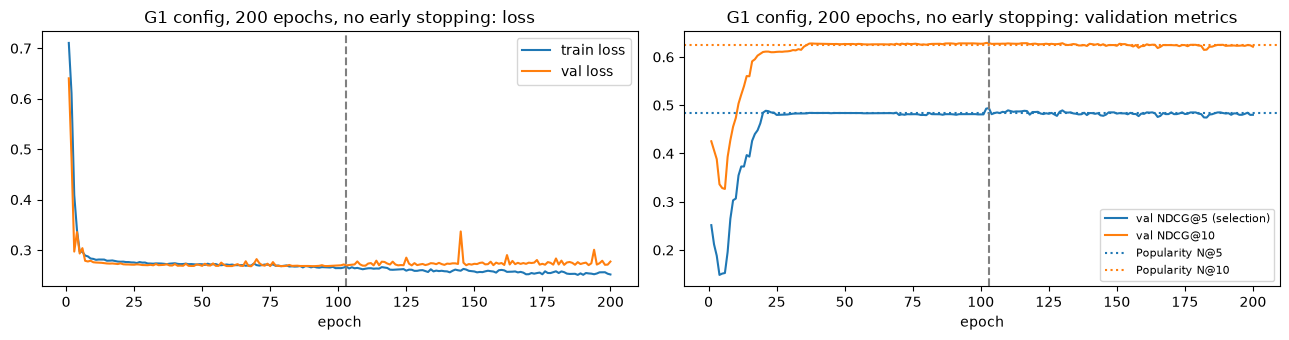

runtime 16s | epoch-1 val N@5 0.2515 | max val N@5 0.4939 at epoch 103 | val-loss min 0.2679 at epoch 68 | final train/val loss 0.2517 / 0.2773
Popularity val N@5 = 0.4832


In [23]:
MIN_EP, PATIENCE, MAX_EP = 50, 50, 300
EXP_LOG, SENS, RUN_CACHE = [], {}, {}

def train_gnn(cfg, seed=SEED, max_epochs=MAX_EP, patience=PATIENCE, min_epochs=MIN_EP):
    set_seed(seed); rng = np.random.default_rng(seed)
    model = BipartiteGAT(**{k: v for k, v in cfg.items() if k not in ('lr', 'wd')}).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    train_snaps, val_snaps = SPLIT_SNAPS['train'], SPLIT_SNAPS['val']
    yv = stack(val_snaps, 'Y'); hist = []; best = (-1, -1); best_state, best_ep, wait, best_m = None, 0, 0, None
    t0 = time.time()
    for ep in range(1, max_epochs + 1):
        model.train(); losses = []
        for k in rng.permutation(len(train_snaps)):
            opt.zero_grad(); loss = snapshot_loss(model, train_snaps[k], rng); loss.backward(); opt.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            vrng = np.random.default_rng(123); vloss = np.mean([snapshot_loss(model, s, vrng).item() for s in val_snaps])
            m = evaluate(gnn_scores(model, val_snaps), yv)
        hist.append({'epoch': ep, 'train_loss': np.mean(losses), 'val_loss': vloss, 'val_recall10': m['Recall@10'],
                     'val_ndcg10': m['NDCG@10'], 'val_prauc': m['PR-AUC'], 'val_ndcg5': m['NDCG@5'], 'val_recall5': m['Recall@5']})
        if ep < min_epochs: continue                                   # warm-up: no checkpoint selection yet
        key = (round(m['NDCG@5'], 6), m['NDCG@10'])            # select on the headline metric, NDCG@5
        if key > best:
            best, best_ep, wait, best_m = key, ep, 0, m; best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    return dict(model=model, hist=pd.DataFrame(hist), best_epoch=best_ep, val=best_m, runtime=time.time() - t0,
                params=n_params(model), cfg=cfg, seed=seed)

def log_run(rnd, change, run, conclusion=''):
    v = run['val']
    EXP_LOG.append({'round': rnd, 'model': 'GAT', 'change': change, 'Val NDCG@5': v['NDCG@5'], 'Val Recall@5': v['Recall@5'], 'Val Recall@10': v['Recall@10'], 'Val NDCG@10': v['NDCG@10'],
                    'Val PR-AUC': v['PR-AUC'], 'best_epoch': run['best_epoch'], 'runtime_s': run['runtime'], 'conclusion': conclusion})

def plot_curves(run, title, ax=None):
    h = run['hist']
    if ax is None: fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
    ax[0].plot(h.epoch, h.train_loss, label='train loss'); ax[0].plot(h.epoch, h.val_loss, label='val loss')
    ax[0].axvline(run['best_epoch'], ls='--', c='grey'); ax[0].set_title(f'{title}: loss'); ax[0].legend(); ax[0].set_xlabel('epoch')
    ax[1].plot(h.epoch, h.val_ndcg5, label='val NDCG@5 (selection)'); ax[1].plot(h.epoch, h.val_ndcg10, label='val NDCG@10')
    ax[1].axhline(RESULTS_VAL['Popularity']['NDCG@5'], ls=':', c='C0', label='Popularity N@5')
    ax[1].axhline(RESULTS_VAL['Popularity']['NDCG@10'], ls=':', c='C1', label='Popularity N@10')
    ax[1].axvline(run['best_epoch'], ls='--', c='grey'); ax[1].set_title(f'{title}: validation metrics'); ax[1].legend(fontsize=8); ax[1].set_xlabel('epoch')

GAT_CUR = dict(hidden=64, layers=2, heads=4, att_dropout=0.1, dropout=0.0, lr=1e-3, wd=0.0)
g_long = train_gnn(GAT_CUR, max_epochs=200, patience=10**9, min_epochs=1)
plot_curves(g_long, 'G1 config, 200 epochs, no early stopping'); plt.tight_layout(); plt.show()
h = g_long['hist']
print(f"runtime {g_long['runtime']:.0f}s | epoch-1 val N@5 {h.val_ndcg5.iloc[0]:.4f} | max val N@5 {h.val_ndcg5.max():.4f} at epoch {int(h.loc[h.val_ndcg5.idxmax(), 'epoch'])} "
      f"| val-loss min {h.val_loss.min():.4f} at epoch {int(h.loc[h.val_loss.idxmin(), 'epoch'])} | final train/val loss {h.train_loss.iloc[-1]:.4f} / {h.val_loss.iloc[-1]:.4f}")
print(f"Popularity val N@5 = {RESULTS_VAL['Popularity']['NDCG@5']:.4f}")

**Insight (G1 learning curve, no stopping, full BCE).** 200 epochs take ~16 s.
- **The warm-up matters again.** Val NDCG@5 starts at 0.252 (epoch 1) and then *drops* to 0.151 by epoch 5, well below random ranking (~0.32), while the loss falls fast (train 0.71 → 0.30). With full BCE the first thing the model learns is the overall ~8% base rate, and in that phase the category ordering is close to arbitrary. Without the 50-epoch warm-up, early stopping could lock in a bad early state, as happened in EuroMart.
- From epoch ~20 the GAT sits on the **popularity line** (val NDCG@5 0.48 vs 0.483). The maximum, 0.494 at epoch 103, is +0.011 over popularity, well within noise (SE ≈ 0.02 with 255 customer-months).
- **Val loss bottoms out at 0.268 (epoch 68) and then drifts up to 0.277, while train loss keeps falling** (0.27 → 0.25): after epoch ~70 the model memorises training snapshots.

*Next:* G1 under the real protocol, then **G2: heads ∈ {1, 2, 4, 8}**. Adoption rule (fixed in advance): a change is kept only if **val NDCG@5** improves by ≥ 0.01 over the current config.

In [24]:
def run_cfg(cfg, rnd, change, seed=SEED):
    r = train_gnn(cfg, seed=seed)
    log_run(rnd, change, r)
    v = r['val']; print(f"{rnd:4s} {change:42s} N@5 {v['NDCG@5']:.4f}  R@5 {v['Recall@5']:.4f}  N@10 {v['NDCG@10']:.4f}  PR-AUC {v['PR-AUC']:.4f}  best_ep {r['best_epoch']:3d}  {r['runtime']:.0f}s")
    return r

def cached_run(cfg, rnd, change):
    key = tuple(sorted(cfg.items()))
    if key not in RUN_CACHE: RUN_CACHE[key] = run_cfg(cfg, rnd, change)
    else: print(f'{rnd:4s} {change:42s} (same as current config) N@5 {RUN_CACHE[key]["val"]["NDCG@5"]:.4f}')
    return RUN_CACHE[key]

def tune_gat(rnd, param, values, cur):
    runs = {v: cached_run({**cur, param: v}, rnd, f'{param} = {v}') for v in values}
    SENS[param] = {v: r['val'] for v, r in runs.items()}
    ref = cached_run(cur, rnd, f'{param} = {cur[param]}')
    best_v = max(runs, key=lambda v: runs[v]['val']['NDCG@5']); gain = runs[best_v]['val']['NDCG@5'] - ref['val']['NDCG@5']
    chosen = best_v if gain >= 0.01 else cur[param]
    EXP_LOG[-1]['conclusion'] = f'best {param}={best_v} gain {gain:+.3f} -> adopt {chosen}'
    print(f'-> best {param} = {best_v} (gain {gain:+.4f}); adopted: {chosen}')
    return chosen

g1 = cached_run(GAT_CUR, 'G1', 'baseline (2L, 4 heads, d64, att-drop .1)')
EXP_LOG[-1]['conclusion'] = 'GAT reference'
GAT_CUR['heads'] = tune_gat('G2', 'heads', [1, 2, 4, 8], GAT_CUR)

G1   baseline (2L, 4 heads, d64, att-drop .1)   N@5 0.4939  R@5 0.4460  N@10 0.6287  PR-AUC 0.3991  best_ep 103  12s
G2   heads = 1                                  N@5 0.4916  R@5 0.4475  N@10 0.6264  PR-AUC 0.4054  best_ep 268  14s
G2   heads = 2                                  N@5 0.4966  R@5 0.4489  N@10 0.6295  PR-AUC 0.3996  best_ep 113  9s
G2   heads = 4                                  (same as current config) N@5 0.4939
G2   heads = 8                                  N@5 0.4975  R@5 0.4489  N@10 0.6283  PR-AUC 0.3947  best_ep  50  10s
G2   heads = 4                                  (same as current config) N@5 0.4939
-> best heads = 8 (gain +0.0036); adopted: 4


**Insight (G1, G2).** Under the protocol, G1 reaches val **NDCG@5 0.494** (Recall@5 0.446, NDCG@10 0.629, PR-AUC 0.399; best epoch 103), i.e. +0.011 over Popularity's 0.483, within one standard error. Heads: 1 → 0.492, 2 → 0.497, **4 → 0.494**, 8 → 0.498. The whole range is 0.006, so **4 heads are kept** (best gain +0.004 < 0.01).

**G3: layers ∈ {1, 2, 3}** and **G4: attention dropout ∈ {0, 0.1, 0.3}**.

In [25]:
GAT_CUR['layers'] = tune_gat('G3', 'layers', [1, 2, 3], GAT_CUR)
GAT_CUR['att_dropout'] = tune_gat('G4', 'att_dropout', [0.0, 0.1, 0.3], GAT_CUR)

G3   layers = 1                                 N@5 0.4942  R@5 0.4466  N@10 0.6277  PR-AUC 0.3888  best_ep  85  7s
G3   layers = 2                                 (same as current config) N@5 0.4939
G3   layers = 3                                 N@5 0.4915  R@5 0.4455  N@10 0.6285  PR-AUC 0.4126  best_ep  53  11s
G3   layers = 2                                 (same as current config) N@5 0.4939
-> best layers = 1 (gain +0.0003); adopted: 2
G4   att_dropout = 0.0                          N@5 0.4839  R@5 0.4323  N@10 0.6275  PR-AUC 0.3743  best_ep  69  9s
G4   att_dropout = 0.1                          (same as current config) N@5 0.4939
G4   att_dropout = 0.3                          N@5 0.4908  R@5 0.4396  N@10 0.6286  PR-AUC 0.3987  best_ep  88  11s
G4   att_dropout = 0.1                          (same as current config) N@5 0.4939
-> best att_dropout = 0.1 (gain +0.0000); adopted: 0.1


**Insight (G3, G4).** Depth: 1 layer 0.494, **2 layers 0.494**, 3 layers 0.492 (val NDCG@5). Completely flat, so **2 layers are kept**. *(Under the old sampled-negative loss with Recall@10 selection, 3 layers had just cleared the rule; under full BCE + NDCG@5 that edge is gone, which shows how fragile it was.)* Attention dropout: 0 → 0.484, **0.1 → 0.494**, 0.3 → 0.491, so **0.1 is kept** (no alternative is better).

**G5: dropout ∈ {0, 0.1, 0.3, 0.5}** and **G6: weight decay ∈ {0, 1e-6, 1e-5, 1e-4, 1e-3}**.

In [26]:
GAT_CUR['dropout'] = tune_gat('G5', 'dropout', [0.0, 0.1, 0.3, 0.5], GAT_CUR)
GAT_CUR['wd'] = tune_gat('G6', 'wd', [0.0, 1e-6, 1e-5, 1e-4, 1e-3], GAT_CUR)
BEST_GAT_RUN = RUN_CACHE[tuple(sorted(GAT_CUR.items()))]
print('\nFINAL GAT CONFIG:', GAT_CUR)
print('val:', {k: round(BEST_GAT_RUN['val'][k], 4) for k in ['NDCG@5', 'Recall@5', 'NDCG@10', 'Recall@10', 'PR-AUC']}, '| params', BEST_GAT_RUN['params'])

G5   dropout = 0.0                              (same as current config) N@5 0.4939
G5   dropout = 0.1                              N@5 0.4919  R@5 0.4412  N@10 0.6291  PR-AUC 0.4005  best_ep 123  14s
G5   dropout = 0.3                              N@5 0.4867  R@5 0.4323  N@10 0.6281  PR-AUC 0.3788  best_ep  81  10s
G5   dropout = 0.5                              N@5 0.4801  R@5 0.4419  N@10 0.6172  PR-AUC 0.4050  best_ep 277  24s
G5   dropout = 0.0                              (same as current config) N@5 0.4939
-> best dropout = 0.0 (gain +0.0000); adopted: 0.0
G6   wd = 0.0                                   (same as current config) N@5 0.4939
G6   wd = 1e-06                                 N@5 0.4933  R@5 0.4449  N@10 0.6289  PR-AUC 0.3938  best_ep 102  12s
G6   wd = 1e-05                                 N@5 0.4958  R@5 0.4499  N@10 0.6288  PR-AUC 0.3922  best_ep 102  12s
G6   wd = 0.0001                                N@5 0.4985  R@5 0.4514  N@10 0.6308  PR-AUC 0.3953  best_ep 156 

**Insight (G5, G6).** Dropout: **0 → 0.494**, 0.1 → 0.492, 0.3 → 0.487, 0.5 → 0.480 (val NDCG@5); nothing beats 0, and heavy dropout hurts slightly. Weight decay: 1e-6 → 0.493, 1e-5 → 0.496, 1e-4 → 0.499, 1e-3 → 0.492. The best (1e-4) gains only +0.005, below the 0.01 rule, so **wd = 0 is kept**.

**Final GAT config: 2 layers, 4 heads, d = 64, attention dropout 0.1, dropout 0, lr 1e-3, wd 0**, i.e. EuroMart's final GAT unchanged (23,232 parameters). Val **NDCG@5 0.494**, Recall@5 0.446, NDCG@10 0.629, PR-AUC 0.399.

**Tuning summary:** under full BCE with NDCG@5 selection, **no round cleared the 0.01 rule**. Across all 15 runs, val NDCG@5 lies in 0.480–0.499, i.e. within about ±0.01 of the starting config (0.494) and never more than +0.016 above popularity (0.483). *Next:* learning curves of the final GAT and the full tuning log.

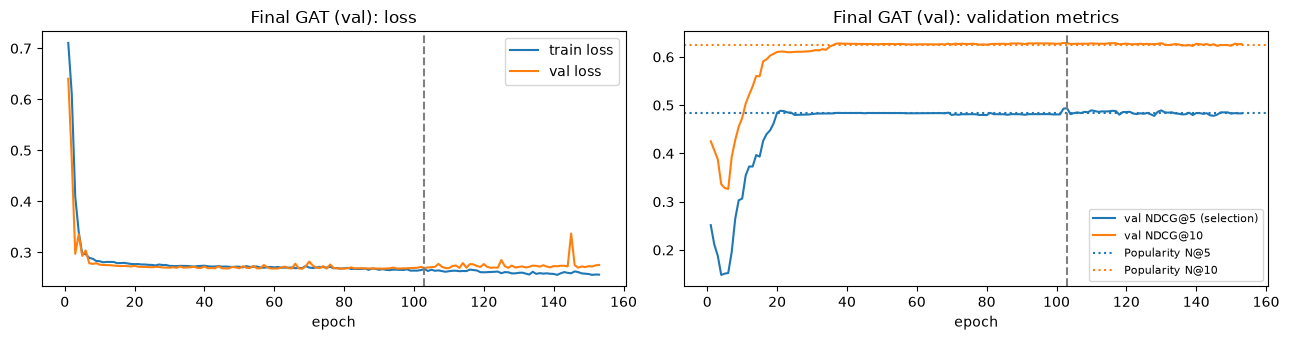

   round                                    change  Val NDCG@5  Val Recall@5  Val NDCG@10  Val Recall@10  Val PR-AUC  best_epoch                                     conclusion
0     G1  baseline (2L, 4 heads, d64, att-drop .1)      0.4939        0.4460       0.6287         0.7665      0.3991         103                                  GAT reference
1     G2                                 heads = 1      0.4916        0.4475       0.6264         0.7669      0.4054         268                                               
2     G2                                 heads = 2      0.4966        0.4489       0.6295         0.7661      0.3996         113                                               
3     G2                                 heads = 8      0.4975        0.4489       0.6283         0.7624      0.3947          50            best heads=8 gain +0.004 -> adopt 4
4     G3                                layers = 1      0.4942        0.4466       0.6277         0.7651      0.3888    

In [27]:
plot_curves(BEST_GAT_RUN, 'Final GAT (val)'); plt.tight_layout(); plt.show()
print(pd.DataFrame(EXP_LOG)[['round', 'change', 'Val NDCG@5', 'Val Recall@5', 'Val NDCG@10', 'Val Recall@10', 'Val PR-AUC', 'best_epoch', 'conclusion']].round(4).to_string())

**Insight (final GAT curves).** The final GAT is the G1 configuration, so its curve is the G1 trajectory with early stopping: the same dip below random in the first ~10 epochs (val NDCG@5 0.15 at epoch 5), a climb onto the **popularity line** by epoch ~20 (0.48), and then a flat plateau at 0.48–0.49. The checkpoint (epoch 103, NDCG@5 0.494) is one of many near-identical epochs, and training stopped at epoch 153. Train loss keeps falling (0.277 → 0.256) while val loss is flat to rising after its minimum around epoch 50–70: nothing generalisable is learned after the model has reached the popularity ordering.

The table above is the full tuning log; it is copied into the **Experiment Log** cell at the top at the end of the notebook.

## Phase 6 — Final evaluation on the TEST set (seeds 42, 43, 44)

**What:** for each of the group's final seeds **42, 43, 44**, retrain the final GAT, LogReg and MLP with exactly the tuned configs (train snapshots only, validation for early stopping on NDCG@5, same warm-up/patience), and evaluate each **once on the test targets** (2024-11 and 2024-12, 262 customer-months). Heuristics are deterministic (std 0). All metrics @3, @5, @10 and PR-AUC are reported; **NDCG@5 is the headline**.

**Decision rule (as EuroMart):** model A is called better than B only if mean(A) − mean(B) > max(std_A, std_B) on that metric.

In [28]:
SEEDS = [42, 43, 44]          # group protocol: same final seeds for every model
Y_TEST = stack(SPLIT_SNAPS['test'], 'Y')
MODELS = ['Popularity', 'Repeat-last-period', 'Repeat-frequent', 'LogReg', 'MLP', 'GAT']
FINAL = {m: [] for m in MODELS}; TEST_SCORES = {m: [] for m in MODELS}; RUNTIME = {m: [] for m in MODELS}; PARAMS = {}
FINAL_GAT = []

for name, fn in HEURISTICS.items():
    t0 = time.time(); S = np.vstack([fn(s) for s in SPLIT_SNAPS['test']]); RUNTIME[name].append(time.time() - t0)
    TEST_SCORES[name].append(S); FINAL[name].append(evaluate(S, Y_TEST)); PARAMS[name] = N_ITEMS if name == 'Popularity' else 0

for seed in SEEDS:
    for name, fitter in [('LogReg', fit_lr), ('MLP', fit_mlp)]:
        t0 = time.time(); m = fitter(seed); RUNTIME[name].append(time.time() - t0)
        S = np.vstack([sk_score(m)(s) for s in SPLIT_SNAPS['test']]); TEST_SCORES[name].append(S); FINAL[name].append(evaluate(S, Y_TEST))
        PARAMS[name] = m.coef_.size + 1 if name == 'LogReg' else sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)
    r = train_gnn(GAT_CUR, seed=seed)
    RUNTIME['GAT'].append(r['runtime']); PARAMS['GAT'] = r['params']; FINAL_GAT.append(r)
    S = gnn_scores(r['model'], SPLIT_SNAPS['test']); TEST_SCORES['GAT'].append(S); FINAL['GAT'].append(evaluate(S, Y_TEST))
    print(f"seed {seed} done | GAT best epoch {r['best_epoch']} | test N@5 {FINAL['GAT'][-1]['NDCG@5']:.4f} R@5 {FINAL['GAT'][-1]['Recall@5']:.4f}", flush=True)
print('all seeds finished')

seed 42 done | GAT best epoch 103 | test N@5 0.4662 R@5 0.4098
seed 43 done | GAT best epoch 91 | test N@5 0.4730 R@5 0.4311
seed 44 done | GAT best epoch 134 | test N@5 0.4848 R@5 0.4502
all seeds finished


In [29]:
METRICS = [f'{m}@{k}' for k in KS for m in ('NDCG', 'Recall', 'Precision', 'HitRate')] + ['PR-AUC']
rows = {}
for m, res in FINAL.items():
    d = pd.DataFrame(res)[METRICS]
    rows[m] = {**{k: f'{d[k].mean():.4f} ± {d[k].std(ddof=0):.4f}' for k in METRICS},
               'params': PARAMS[m], 'train time (s)': f'{np.mean(RUNTIME[m]):.1f}'}
FINAL_TABLE = pd.DataFrame(rows).T
MEAN = {m: pd.DataFrame(r)[METRICS].mean() for m, r in FINAL.items()}
STD = {m: pd.DataFrame(r)[METRICS].std(ddof=0) for m, r in FINAL.items()}
print('TEST, mean ± std over seeds 42, 43, 44 -- headline NDCG@5')
display(FINAL_TABLE[['NDCG@5', 'Recall@5', 'Precision@5', 'HitRate@5', 'PR-AUC', 'params', 'train time (s)']])
print('@3 and @10')
display(FINAL_TABLE[['NDCG@3', 'Recall@3', 'Precision@3', 'HitRate@3', 'NDCG@10', 'Recall@10', 'Precision@10', 'HitRate@10']])

def better(a, b, k):
    gap = MEAN[a][k] - MEAN[b][k]; thr = max(STD[a][k], STD[b][k])
    return gap, thr, ('BETTER' if gap > thr else 'WORSE' if -gap > thr else 'no difference')
for b in ['Popularity', 'Repeat-last-period', 'Repeat-frequent', 'LogReg', 'MLP']:
    print(f'GAT vs {b:18s}: ' + ' | '.join(f'{k} {better("GAT", b, k)[0]:+.4f} {better("GAT", b, k)[2]}' for k in ['NDCG@5', 'NDCG@3', 'NDCG@10', 'Recall@5', 'PR-AUC']))

TEST, mean ± std over seeds 42, 43, 44 -- headline NDCG@5


,NDCG@5,Recall@5,Precision@5,HitRate@5,PR-AUC,params,train time (s)
Popularity,0.4894 ± 0.0000,0.4482 ± 0.0000,0.4214 ± 0.0000,0.9580 ± 0.0000,0.4153 ± 0.0000,17,0.0
Repeat-last-period,0.4323 ± 0.0000,0.3995 ± 0.0000,0.3802 ± 0.0000,0.9237 ± 0.0000,0.3559 ± 0.0000,0,0.0
Repeat-frequent,0.4449 ± 0.0000,0.4113 ± 0.0000,0.3916 ± 0.0000,0.9160 ± 0.0000,0.3632 ± 0.0000,0,0.0
LogReg,0.4858 ± 0.0000,0.4347 ± 0.0000,0.4137 ± 0.0000,0.9313 ± 0.0000,0.4183 ± 0.0000,37,0.3
MLP,0.4383 ± 0.0272,0.4055 ± 0.0220,0.3845 ± 0.0209,0.9237 ± 0.0165,0.3497 ± 0.0355,2433,0.6
GAT,0.4747 ± 0.0077,0.4304 ± 0.0165,0.4084 ± 0.0141,0.9517 ± 0.0018,0.3810 ± 0.0056,23232,12.7


@3 and @10


,NDCG@3,Recall@3,Precision@3,HitRate@3,NDCG@10,Recall@10,Precision@10,HitRate@10
Popularity,0.4761 ± 0.0000,0.2894 ± 0.0000,0.4555 ± 0.0000,0.8588 ± 0.0000,0.6250 ± 0.0000,0.7626 ± 0.0000,0.3668 ± 0.0000,1.0000 ± 0.0000
Repeat-last-period,0.4202 ± 0.0000,0.2628 ± 0.0000,0.4109 ± 0.0000,0.8206 ± 0.0000,0.5738 ± 0.0000,0.7265 ± 0.0000,0.3469 ± 0.0000,1.0000 ± 0.0000
Repeat-frequent,0.4337 ± 0.0000,0.2739 ± 0.0000,0.4275 ± 0.0000,0.8359 ± 0.0000,0.5795 ± 0.0000,0.7261 ± 0.0000,0.3469 ± 0.0000,1.0000 ± 0.0000
LogReg,0.4834 ± 0.0000,0.2910 ± 0.0000,0.4606 ± 0.0000,0.8550 ± 0.0000,0.6283 ± 0.0000,0.7638 ± 0.0000,0.3664 ± 0.0000,1.0000 ± 0.0000
MLP,0.4243 ± 0.0287,0.2651 ± 0.0163,0.4152 ± 0.0253,0.8079 ± 0.0281,0.5714 ± 0.0315,0.7165 ± 0.0323,0.3421 ± 0.0152,0.9975 ± 0.0036
GAT,0.4722 ± 0.0085,0.2919 ± 0.0043,0.4584 ± 0.0060,0.8537 ± 0.0090,0.6194 ± 0.0025,0.7664 ± 0.0027,0.3676 ± 0.0005,1.0000 ± 0.0000


GAT vs Popularity        : NDCG@5 -0.0147 WORSE | NDCG@3 -0.0039 no difference | NDCG@10 -0.0056 WORSE | Recall@5 -0.0178 WORSE | PR-AUC -0.0344 WORSE
GAT vs Repeat-last-period: NDCG@5 +0.0424 BETTER | NDCG@3 +0.0519 BETTER | NDCG@10 +0.0456 BETTER | Recall@5 +0.0309 BETTER | PR-AUC +0.0251 BETTER
GAT vs Repeat-frequent   : NDCG@5 +0.0298 BETTER | NDCG@3 +0.0384 BETTER | NDCG@10 +0.0399 BETTER | Recall@5 +0.0191 BETTER | PR-AUC +0.0177 BETTER
GAT vs LogReg            : NDCG@5 -0.0111 WORSE | NDCG@3 -0.0112 WORSE | NDCG@10 -0.0089 WORSE | Recall@5 -0.0043 no difference | PR-AUC -0.0373 WORSE
GAT vs MLP               : NDCG@5 +0.0364 BETTER | NDCG@3 +0.0479 BETTER | NDCG@10 +0.0480 BETTER | Recall@5 +0.0249 BETTER | PR-AUC +0.0313 no difference


**Insight (test results). GAT does not beat popularity on test, on the headline metric or any other.**

| Test (mean ± std, seeds 42–44) | **NDCG@5** | NDCG@3 | NDCG@10 | Recall@5 | HitRate@5 | PR-AUC |
|---|---|---|---|---|---|---|
| **Popularity** | **0.489** | 0.476 | 0.625 | **0.448** | **0.958** | 0.415 |
| LogReg | 0.486 | **0.483** | **0.628** | 0.435 | 0.931 | **0.418** |
| **GAT** | 0.475 ± .008 | 0.472 ± .009 | 0.619 ± .003 | 0.430 ± .017 | 0.952 ± .002 | 0.381 ± .006 |
| Repeat-frequent | 0.445 | 0.434 | 0.580 | 0.411 | 0.916 | 0.363 |
| MLP | 0.438 ± .027 | 0.424 ± .029 | 0.571 ± .032 | 0.406 ± .022 | 0.924 ± .017 | 0.350 ± .036 |
| Repeat-last-period | 0.432 | 0.420 | 0.574 | 0.400 | 0.924 | 0.356 |

- **Headline: GAT NDCG@5 = 0.475 ± 0.008 vs Popularity 0.489 and LogReg 0.486.** By the seed-std rule GAT is **worse than Popularity** on NDCG@5, NDCG@10, Recall@5 and PR-AUC (no difference on NDCG@3), and **worse than LogReg** on NDCG@3/5/10 and PR-AUC.
- **GAT clearly beats both repeat heuristics and the MLP** on NDCG@3/5/10 and Recall@5.
- **PR-AUC dropped most** (0.381 vs 0.415): under full BCE the GAT's probabilities rank *cells across customers* worse than popularity does, even though its within-customer ordering is close.
- **The validation edge disappeared again**: on val the GAT led popularity by +0.011 NDCG@5; on test it trails by −0.015. Selection noise, as in EuroMart.
- HitRate@10 = 1.0 for every model: with ~5 positives out of 17, any top-10 contains at least one. @10 metrics are therefore lenient here, which is why @3 and @5 are the informative cut-offs.

*Caveat on the rule:* seed std measures training randomness only (3 seeds), and deterministic baselines have std 0. *Next:* a **paired bootstrap over test customer-months**, which measures the gaps against *sampling* noise.

In [30]:
def per_customer(S, Y, metric='ndcg', k=10):
    keep = Y.sum(1) > 0; S, Y = S[keep], Y[keep].astype(int)
    order = np.argsort(-(S + np.random.default_rng(0).random(S.shape) * 1e-9), 1); ranked = np.take_along_axis(Y, order, 1)
    if metric == 'recall': return ranked[:, :k].sum(1) / Y.sum(1)
    disc = 1 / np.log2(np.arange(2, k + 2)); idcg = np.array([disc[:min(p, k)].sum() for p in Y.sum(1)])
    return (ranked[:, :k] * disc).sum(1) / idcg

MEAN_SCORES = {m: np.mean(TEST_SCORES[m], 0) for m in TEST_SCORES}            # seed-averaged score matrices
boot = np.random.default_rng(SEED)
n_c = int((Y_TEST.sum(1) > 0).sum()); idx = boot.integers(0, n_c, (2000, n_c))
rows = []
for b in ['Popularity', 'LogReg', 'Repeat-frequent', 'MLP']:
    for metric, k in [('ndcg', 5), ('recall', 5), ('ndcg', 3), ('ndcg', 10)]:
        d = per_customer(MEAN_SCORES['GAT'], Y_TEST, metric, k) - per_customer(MEAN_SCORES[b], Y_TEST, metric, k)
        bs = d[idx].mean(1)
        rows.append({'GAT minus': b, 'metric': f'{metric}@{k}', 'diff': d.mean(), 'CI low': np.quantile(bs, .025), 'CI high': np.quantile(bs, .975),
                     'P(diff>0)': (bs > 0).mean()})
print(f'paired bootstrap over {n_c} test customer-months (2000 reps, seed-averaged scores)')
pd.DataFrame(rows).round(4)

paired bootstrap over 262 test customer-months (2000 reps, seed-averaged scores)


,GAT minus,metric,diff,CI low,CI high,P(diff>0)
0,Popularity,ndcg@5,-0.0067,-0.0215,0.0071,0.1720
1,Popularity,recall@5,-0.0133,-0.0273,0.0001,0.0255
2,Popularity,ndcg@3,0.0000,-0.0157,0.0149,0.4765
3,Popularity,ndcg@10,-0.0001,-0.0136,0.0126,0.4920
4,LogReg,ndcg@5,-0.0031,-0.0184,0.0119,0.3435
5,LogReg,recall@5,0.0002,-0.0187,0.0196,0.4940
6,LogReg,ndcg@3,-0.0073,-0.0207,0.0062,0.1465
7,LogReg,ndcg@10,-0.0034,-0.0119,0.0050,0.2260
8,Repeat-frequent,ndcg@5,0.0378,0.0107,0.0648,0.9960
9,Repeat-frequent,recall@5,0.0236,-0.0046,0.0504,0.9560


**Insight (paired bootstrap).** Against sampling noise (262 customer-months, seed-averaged GAT scores):
- **GAT vs Popularity: no detectable difference** on the headline NDCG@5 (−0.007, 95% CI [−0.022, +0.007]), on NDCG@3 (0.000) and NDCG@10 (0.000). Recall@5 is −0.013, CI [−0.027, +0.000], borderline.
- **GAT vs LogReg: no detectable difference** on any cut-off (NDCG@5 −0.003, CI [−0.018, +0.012]).
- **GAT vs Repeat-frequent: significantly better** (NDCG@5 +0.038, CI [+0.011, +0.065]). **vs MLP:** better on NDCG@3 and NDCG@10, borderline on NDCG@5 (+0.020, CI [−0.003, +0.042]).
- Note the seed-averaged GAT (an ensemble of 3) is closer to popularity (−0.007) than the per-seed mean (−0.015): averaging seeds removes some of each run's noise, pulling the ranking back toward popularity.

*Next:* *what* does the GAT rank first, per customer?

**What:** for every test customer-month, the GAT's (seed-averaged) top-5 categories, compared with the popularity top-5, broken down by test month; and how similar each customer's GAT score row is to the popularity vector.

In [31]:
pop_t = pop_vec(SPLIT_SNAPS['test'][0])
pop_top5 = ITEM_NAMES[np.argsort(-pop_t)[:5]]
G = MEAN_SCORES['GAT']
gat_top5 = pd.Series([tuple(ITEM_NAMES[np.sort(r)]) for r in np.argsort(-G, 1)[:, :5]])
print('popularity top-5:', list(pop_top5))
print('distinct GAT top-5 sets over', len(G), 'customer-months:', gat_top5.nunique())
print('most common GAT top-5 set:', list(gat_top5.value_counts().index[0]), f'({gat_top5.value_counts().iloc[0] / len(G):.0%} of rows)')
row_corr = np.array([np.corrcoef(G[i], pop_t)[0, 1] for i in range(len(G))])
row_rank = np.array([pd.Series(G[i]).rank().corr(pd.Series(pop_t).rank()) for i in range(len(G))])
print(f'corr(GAT score row, popularity): mean {row_corr.mean():.3f} (min {row_corr.min():.3f}) | Spearman rank corr mean {row_rank.mean():.3f}')
cmp = pd.DataFrame({'popularity rank': pd.Series(pop_t, index=ITEM_NAMES).rank(ascending=False).astype(int),
                    'GAT mean-score rank': pd.Series(G.mean(0), index=ITEM_NAMES).rank(ascending=False).astype(int),
                    '# products': df.groupby('category')['prod_id'].nunique().reindex(ITEM_NAMES).values,
                    'test buy rate % (buyers)': (Y_TEST[Y_TEST.sum(1) > 0].mean(0) * 100).round(1)}).sort_values('popularity rank')
n_nov = SPLIT_SNAPS['test'][0]['n']
for name, sl in [('2024-11', slice(0, n_nov)), ('2024-12', slice(n_nov, None))]:
    vc_m = gat_top5[sl].value_counts(normalize=True)
    print(f'{name}: {vc_m.iloc[0]:.1%} of customers get top-5 {list(vc_m.index[0])}')
cmp.T

popularity top-5: ['Fruits & Vegetables', 'Grains & Staples', 'Bakery', 'Household', 'Dairy & Eggs']
distinct GAT top-5 sets over 962 customer-months: 5
most common GAT top-5 set: ['Bakery', 'Fruits & Vegetables', 'Grains & Staples', 'Household', 'Snacks'] (50% of rows)
corr(GAT score row, popularity): mean 0.977 (min 0.948) | Spearman rank corr mean 0.968
2024-11: 99.6% of customers get top-5 ['Bakery', 'Dairy & Eggs', 'Fruits & Vegetables', 'Grains & Staples', 'Household']
2024-12: 99.6% of customers get top-5 ['Bakery', 'Fruits & Vegetables', 'Grains & Staples', 'Household', 'Snacks']


,Fruits & Vegetables,Grains & Staples,Bakery,Household,Dairy & Eggs,Beverages,Electronics,Snacks,Meat & Seafood,Clothing,Personal Care,Stationery,Baby Care,Health & Wellness,Books,Clothing Accessories,Footwear
popularity rank,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0
GAT mean-score rank,2.0,1.0,3.0,4.0,5.0,9.0,7.0,6.0,8.0,11.0,10.0,12.0,14.0,13.0,15.0,17.0,16.0
# products,8.0,8.0,5.0,5.0,5.0,5.0,5.0,4.0,4.0,4.0,4.0,3.0,2.0,2.0,2.0,1.0,1.0
test buy rate % (buyers),51.1,53.1,32.1,35.5,38.9,36.6,37.0,28.6,23.7,30.2,31.3,20.2,19.5,16.0,13.0,7.6,11.8


**Insight (what GAT ranks). The GAT is still a global ranker, not a personalised one.**
- Over 962 test customer-months there are only **5 distinct top-5 sets**, and two of them cover 99.6%: **in November every customer gets exactly the popularity top-5** (Fruits & Vegetables, Grains & Staples, Bakery, Household, Dairy & Eggs); **in December every customer gets the same set with Snacks in place of Dairy & Eggs**. The ranking changes with the *month's graph*, not with the customer. Each customer's score row correlates 0.98 with popularity (Spearman 0.97).
- The December swap is a mistake: Snacks (popularity rank 8, bought by 8.3% of eligible customers in December) displaces Dairy & Eggs (rank 5, 10.5%). That explains why the per-seed GAT trails popularity on NDCG@5 and Recall@5.
- Compared with the sampled-negative version, full BCE made the GAT *closer* to popularity (Nov top-5 identical, Spearman 0.97 vs 0.95), but it still invents one wrong swap.

**What next (H2, by node degree):** split test customer-months by history degree (distinct categories bought ≤ t) into roughly equal thirds: low (2–8), mid (9–11), high (12–16), and compare test **NDCG@5**.

customer-months per bin: {'low (2-8)': 96, 'mid (9-11)': 97, 'high (12-16)': 69}
mean # positives per bin: {'high (12-16)': 4.77, 'low (2-8)': 4.9, 'mid (9-11)': 4.9}


degree bin,low (2-8),mid (9-11),high (12-16)
model,,,
GAT,0.4771,0.4828,0.4600
LogReg,0.4963,0.4929,0.4611
MLP,0.4510,0.4532,0.3995
Popularity,0.5047,0.5015,0.4510
Repeat-frequent,0.4665,0.4443,0.4156


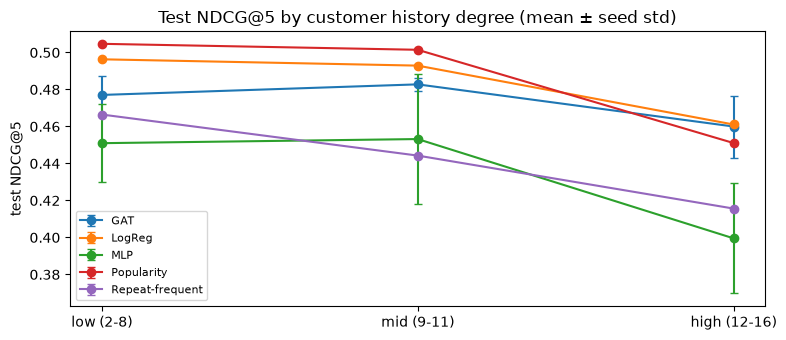

In [32]:
deg_test = np.concatenate([(s['cnt'] > 0).sum(1) for s in SPLIT_SNAPS['test']])
has_pos = Y_TEST.sum(1) > 0
bins = pd.cut(deg_test[has_pos], [0, 8, 11, 17], labels=['low (2-8)', 'mid (9-11)', 'high (12-16)'])
print('customer-months per bin:', bins.value_counts().sort_index().to_dict())
print('mean # positives per bin:', pd.Series(Y_TEST[has_pos].sum(1)).groupby(np.asarray(bins)).mean().round(2).to_dict())
deg_rows = []
for m in ['Popularity', 'Repeat-frequent', 'LogReg', 'MLP', 'GAT']:
    per_seed = [pd.Series(per_customer(S, Y_TEST, 'ndcg', 5)).groupby(np.asarray(bins)).mean() for S in TEST_SCORES[m]]
    df_s = pd.concat(per_seed, axis=1)
    for b in df_s.index: deg_rows.append({'model': m, 'degree bin': b, 'NDCG@5': df_s.loc[b].mean(), 'std': df_s.loc[b].std(ddof=0)})
DEG = pd.DataFrame(deg_rows)
cols = ['low (2-8)', 'mid (9-11)', 'high (12-16)']
piv = DEG.pivot(index='model', columns='degree bin', values='NDCG@5')[cols]
display(piv.round(4))
fig, ax = plt.subplots(figsize=(8, 3.5))
for m in piv.index:
    ax.errorbar(range(3), piv.loc[m], yerr=DEG.pivot(index='model', columns='degree bin', values='std').loc[m, cols], marker='o', capsize=3, label=m)
ax.set_xticks(range(3)); ax.set_xticklabels(cols); ax.set_ylabel('test NDCG@5'); ax.set_title('Test NDCG@5 by customer history degree (mean ± seed std)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Insight (H2, degree split).** Bins hold 96 / 97 / 69 customer-months (per-bin NDCG@5 SE ≈ ±0.025).
- **Low-degree customers (2–8 categories): GAT is *below* popularity** (NDCG@5 0.477 vs 0.505) and below LogReg (0.496). This is the group where H2 expected attention to help most, and it is the opposite, as in EuroMart.
- Mid-degree: GAT 0.483 vs popularity 0.502. High-degree (12–16): all models drop; GAT 0.460 is slightly above popularity (0.451) and level with LogReg (0.461), well within noise.
- **The number of positives does not grow with history degree** (4.8–4.9 in every bin): a customer who has bought more categories does not buy more next month. Another "independent draws" signature.

**H2 is not supported.**

## Shopping question (H4): what % of customers will buy each category next month?

**What:** turn scores into **probabilities over all eligible customers** (including those who buy nothing), average each column, and compare with the actual % per category and test month.
- LogReg outputs are probabilities.
- **GAT outputs are now probabilities too**: with full BCE over all cells the sigmoid of the dot product is trained as P(buy), so the Platt scaling step used with sampled negatives is no longer needed.
- Naive forecasters: **last month's rate**, and the **running mean** of all past monthly rates (sensible because Phase 2 found no seasonality).

Error: mean absolute error in percentage points over 17 categories × 2 test months.

In [33]:
Y_VAL = stack(SPLIT_SNAPS['val'], 'Y')
# full BCE over all cells -> the GAT's sigmoid outputs are already probabilities, so no Platt scaling is needed
calibrated = lambda S: S

rows_pct = []
for k, s in enumerate(SPLIT_SNAPS['test']):
    lo = sum(x['n'] for x in SPLIT_SNAPS['test'][:k]); hi = lo + s['n']
    actual = s['Y'].mean(0) * 100
    prev = SNAP[s['t']]['Y'].mean(0) * 100
    running = np.mean([SNAP[t]['Y'].mean(0) for t in range(1, s['t'] + 1)], 0) * 100
    est = {'LogReg': MEAN_SCORES['LogReg'][lo:hi].mean(0) * 100, 'GAT': calibrated(MEAN_SCORES['GAT'][lo:hi]).mean(0) * 100,
           'Naive: last month': prev, 'Naive: running mean': running}
    for j in range(N_ITEMS):
        rows_pct.append({'month': str(MONTHS[s['t1']]), 'category': ITEM_NAMES[j], 'actual %': actual[j], **{e: v[j] for e, v in est.items()}})
PCT = pd.DataFrame(rows_pct)
ests = ['LogReg', 'GAT', 'Naive: last month', 'Naive: running mean']
print('Error of predicted % buying, percentage points (17 categories x 2 test months):')
print(pd.DataFrame({'MAE (pp)': {e: (PCT[e] - PCT['actual %']).abs().mean() for e in ests},
                    'bias (pp)': {e: (PCT[e] - PCT['actual %']).mean() for e in ests},
                    'corr with actual': {e: np.corrcoef(PCT[e], PCT['actual %'])[0, 1] for e in ests}}).round(3).to_string())
print('\n% of eligible customers buying anything, per test month:',
      {str(MONTHS[s['t1']]): round((s['Y'].sum(1) > 0).mean() * 100, 1) for s in SPLIT_SNAPS['test']})

Error of predicted % buying, percentage points (17 categories x 2 test months):
                     MAE (pp)  bias (pp)  corr with actual
LogReg                  1.231      1.005             0.944
GAT                     2.051      1.690             0.871
Naive: last month       1.112      0.076             0.918
Naive: running mean     0.819      0.165             0.948

% of eligible customers buying anything, per test month: {'2024-11': np.float64(26.8), '2024-12': np.float64(27.7)}


**Insight (H4, aggregate accuracy).** All forecasters get the share of customers buying each category to within **~1–2 percentage points**. The **best is the naive running mean (MAE 0.82 pp)**, then last month (1.11), LogReg (1.23) and the **GAT (2.05 pp, bias +1.7 pp)**, the worst. Both models over-predict: the eligible-customer pool keeps growing while the number of active customers per month stays flat (~27–28% buy in each test month), so per-customer rates drift down after training. **H4 is supported**, but by a long-run average, not by a model.

**What next:** the answer table for the latest month (December 2024): actual vs predicted % buying each category, plus a chart.

,# products,2024-11 actual %,2024-11 Naive: running mean,2024-11 LogReg,2024-11 GAT,2024-12 actual %,2024-12 Naive: running mean,2024-12 LogReg,2024-12 GAT
category,,,,,,,,,
Grains & Staples,8,13.8,14.5,15.8,12.5,15.1,14.4,15.8,13.3
Fruits & Vegetables,8,13.2,13.6,14.4,11.9,14.7,13.6,14.4,13.3
Dairy & Eggs,5,10.7,10.3,10.9,11.0,10.5,10.3,11.0,11.8
Electronics,5,10.0,9.4,10.1,10.8,10.1,9.4,10.2,11.3
Beverages,5,10.0,10.1,11.1,10.1,9.9,10.1,11.2,11.5
Household,5,9.4,10.4,11.4,11.0,9.9,10.3,11.5,12.3
Personal Care,4,7.7,8.1,9.1,9.5,9.3,8.1,9.2,10.6
Snacks,4,7.3,8.6,9.4,10.3,8.3,8.5,9.4,11.8
Bakery,5,9.2,10.5,12.1,11.7,8.3,10.4,12.1,12.8


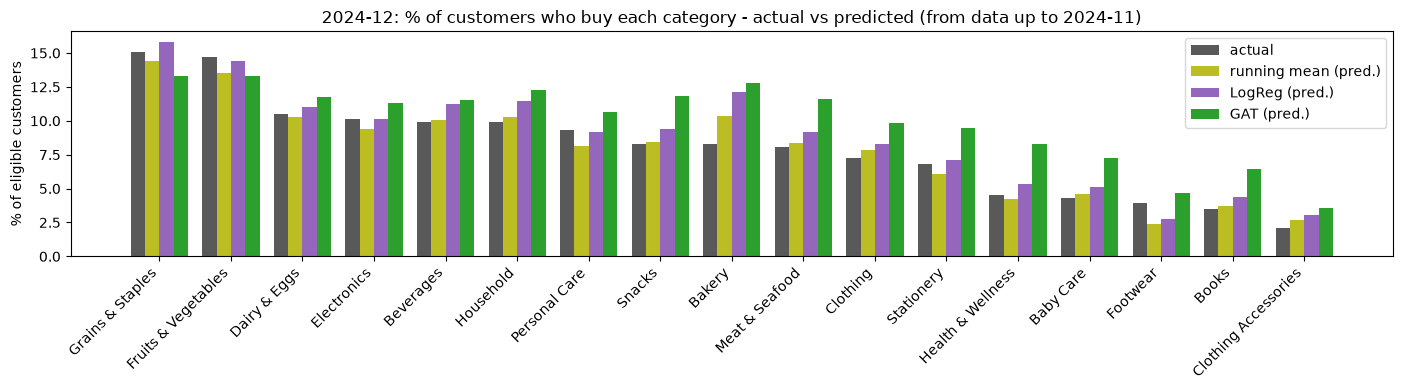

In [34]:
ANSWER = PCT.pivot_table(index='category', columns='month', values=['actual %', 'Naive: running mean', 'LogReg', 'GAT']).round(1)
ANSWER.columns = [f'{mo} {m}' for m, mo in ANSWER.columns]
order_cols = [f'{mo} {m}' for mo in ['2024-11', '2024-12'] for m in ['actual %', 'Naive: running mean', 'LogReg', 'GAT']]
ANSWER = ANSWER[order_cols].sort_values('2024-12 actual %', ascending=False)
ANSWER.insert(0, '# products', df.groupby('category')['prod_id'].nunique().reindex(ANSWER.index))
display(ANSWER)

dec = PCT[PCT.month == '2024-12'].set_index('category').loc[ANSWER.index]
fig, ax = plt.subplots(figsize=(14, 4)); x = np.arange(len(dec)); w = .2
ax.bar(x - 1.5 * w, dec['actual %'], w, label='actual', color='0.35')
ax.bar(x - .5 * w, dec['Naive: running mean'], w, label='running mean (pred.)', color='tab:olive')
ax.bar(x + .5 * w, dec['LogReg'], w, label='LogReg (pred.)', color='tab:purple')
ax.bar(x + 1.5 * w, dec['GAT'], w, label='GAT (pred.)', color='tab:green')
ax.set_xticks(x); ax.set_xticklabels(dec.index, rotation=45, ha='right'); ax.set_ylabel('% of eligible customers')
ax.set_title('2024-12: % of customers who buy each category - actual vs predicted (from data up to 2024-11)'); ax.legend()
plt.tight_layout(); plt.show()

**Insight (the answer table).** For **December 2024**, out of all customers seen before: **Grains & Staples 15.1%, Fruits & Vegetables 14.7%**, then a block of 8–11% (Dairy & Eggs 10.5, Electronics 10.1, Beverages 9.9, Household 9.9, Personal Care 9.3, Snacks 8.3, Bakery 8.3, Meat & Seafood 8.1), then the small categories (Footwear 3.9, Books 3.5, Clothing Accessories 2.1). The `# products` column almost sorts the table by itself: **expected % buying ≈ (share of customers active) × (products in the category / 68)**, a fixed catalogue property.

Two things stand out:
1. The running-mean forecast is closest because the monthly rates just fluctuate around a constant; month-to-month swings of ±2–3 pp in small categories are sampling noise that no model can forecast.
2. **The GAT's full-BCE probabilities are *compressed***: it under-predicts the two big staples (13.3% vs ~15%) and over-predicts every small category (Health & Wellness 8.3% vs 4.5%, Books 6.4% vs 3.5%, Baby Care 7.3% vs 4.3%). Its scores carry less of the catalogue-size signal than plain popularity, so its ranking is right at the top but its *levels* are pulled toward the average.

**What next (H5, H6):** (H5) does *when* someone shops change *what* they buy? χ² of **daypart (morning / afternoon / evening) × category** and **weekend × category** on purchase lines, with Cramér's V. (H6) seasonality: % of eligible customers active per month (χ²) and the category mix by month.

In [35]:
from scipy.stats import chi2_contingency
def cramers_v(ct):
    chi2, p, dof, _ = chi2_contingency(ct); n = ct.values.sum(); r, k = ct.shape
    return chi2, p, dof, np.sqrt(chi2 / (n * (min(r, k) - 1)))

daypart = pd.cut(df['event_time'].dt.hour, [-1, 11, 16, 24], labels=['morning (<12)', 'afternoon (12-16)', 'evening (17+)'])
for name, grp in [('daypart', daypart), ('weekend', df['weekend'].map({0.0: 'weekday', 1.0: 'weekend'}))]:
    ct = pd.crosstab(grp, df['category'])
    chi2, p, dof, v = cramers_v(ct)
    spread = (pd.crosstab(grp, df['category'], normalize='index') * 100).T
    print(f'H5 {name} x category: chi2={chi2:.1f}, dof={dof}, p={p:.3g}, Cramer V={v:.3f} | largest share gap {(spread.max(axis=1) - spread.min(axis=1)).max():.2f} pp')
print('order share by daypart:', daypart[df.order_id.drop_duplicates().index].value_counts(normalize=True).round(3).to_dict())

# H6: seasonality - % of eligible customers active per month (Feb-Dec, so every month has a prior pool)
act = df.groupby('m_idx')['cust_id'].nunique()
elig = pd.Series({t: df[df.m_idx <= t]['cust_id'].nunique() for t in act.index})
mon = pd.DataFrame({'active': act, 'eligible (seen up to and incl. month)': elig}).iloc[1:]
mon['% active'] = (mon.active / mon.iloc[:, 1] * 100).round(1); mon.index = [str(MONTHS[t]) for t in mon.index]
ct6 = pd.DataFrame({'active': mon.active, 'inactive': mon.iloc[:, 1] - mon.active})
chi2, p, dof, v = cramers_v(ct6)
print(f'\nH6 active vs month (Feb-Dec): chi2={chi2:.1f}, dof={dof}, p={p:.3g}, Cramer V={v:.3f}')
print('  (confounded: customers first seen in a month are active by definition, and new arrivals shrink over the year)')
# cleaner test: are orders spread over the months in proportion to the number of days?
from scipy.stats import chisquare
opm = df.groupby('month')['order_id'].nunique(); days = np.array([m.days_in_month for m in opm.index])
chi2, p = chisquare(opm.values, opm.sum() * days / days.sum())
print(f'H6 orders per month vs uniform-per-day: chi2={chi2:.1f}, dof={len(opm) - 1}, p={p:.3g} | orders per month: {opm.values.tolist()}')
act_ret = [len(set(df[df.m_idx == t].cust_id) & set(df[df.m_idx < t].cust_id)) for t in range(1, 12)]
print('returning active customers per month (Feb-Dec):', act_ret)
ct6b = pd.crosstab(df['month'], df['category'])
chi2, p, dof, v = cramers_v(ct6b)
print(f'H6b category MIX vs month: chi2={chi2:.1f}, dof={dof}, p={p:.3g}, Cramer V={v:.3f}')
mon.T

H5 daypart x category: chi2=54.0, dof=32, p=0.00875, Cramer V=0.053 | largest share gap 1.72 pp
H5 weekend x category: chi2=15.7, dof=16, p=0.472, Cramer V=0.040 | largest share gap 0.96 pp
order share by daypart: {'morning (<12)': 0.37, 'evening (17+)': 0.334, 'afternoon (12-16)': 0.296}

H6 active vs month (Feb-Dec): chi2=93.4, dof=10, p=1.12e-15, Cramer V=0.143
  (confounded: customers first seen in a month are active by definition, and new arrivals shrink over the year)
H6 orders per month vs uniform-per-day: chi2=4.1, dof=11, p=0.965 | orders per month: [185, 158, 162, 154, 171, 163, 170, 182, 155, 167, 157, 167]
returning active customers per month (Feb-Dec): [43, 61, 90, 109, 112, 125, 140, 124, 131, 128, 134]
H6b category MIX vs month: chi2=194.4, dof=176, p=0.163, Cramer V=0.043


,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12
active,131.0,140.0,140.0,145.0,136.0,144.0,156.0,130.0,139.0,134.0,138.0
eligible (seen up to and incl. month),240.0,319.0,369.0,405.0,429.0,448.0,464.0,470.0,478.0,484.0,488.0
% active,54.6,43.9,37.9,35.8,31.7,32.1,33.6,27.7,29.1,27.7,28.3


**Insight (H5, H6).**
- **H5 (when people shop changes what they buy): not supported in any practical sense.** Weekend vs weekday: p = 0.47, V = 0.04, largest share difference 0.96 pp. Daypart × category is *statistically* detectable (p = 0.009) but tiny (V = 0.053, largest difference 1.7 pp of a category's share). Shopping time cannot be used to personalise *what* to recommend.
- **H6 (seasonality): not supported.** The naive "% of eligible customers active" falls from 55% to 28% (χ² p ≈ 1e−15), but that is an artefact of the pool: customers first seen in a month are active by definition, and new arrivals dry up during the year. The clean test, orders per month against a uniform-per-day expectation, gives **χ² = 4.1 on 11 dof, p = 0.97**. That is not just "no seasonality": a p-value this close to 1 means the months are *more even than random sampling would produce*, the same under-dispersion seen for products (lines-per-product CV below the sampling floor). Returning active customers plateau at ~125–140 per month from July. The **category mix does not change by month** either (p = 0.16, V = 0.04).

*Implication:* there is nothing time-dependent to forecast. Expected % buying c next month ≈ constant activity × catalogue share of c, which is exactly what the running-mean forecaster encodes.

 
## Plots explaining how the GAT works

**Plot 1: one customer, fixed vs learned weights.** For one test customer (December snapshot, final GAT with seed 42), the weight with which each neighbouring category's message enters the customer's representation. Left: the fixed symmetric-normalised weight 1/√(d_u d_c) that a GCN would use (renormalised to sum to 1, self-loop included), as a reference for "degree-based" weighting. Right: GAT's learned attention α_uc in each of the 2 layers, averaged over the 4 heads.

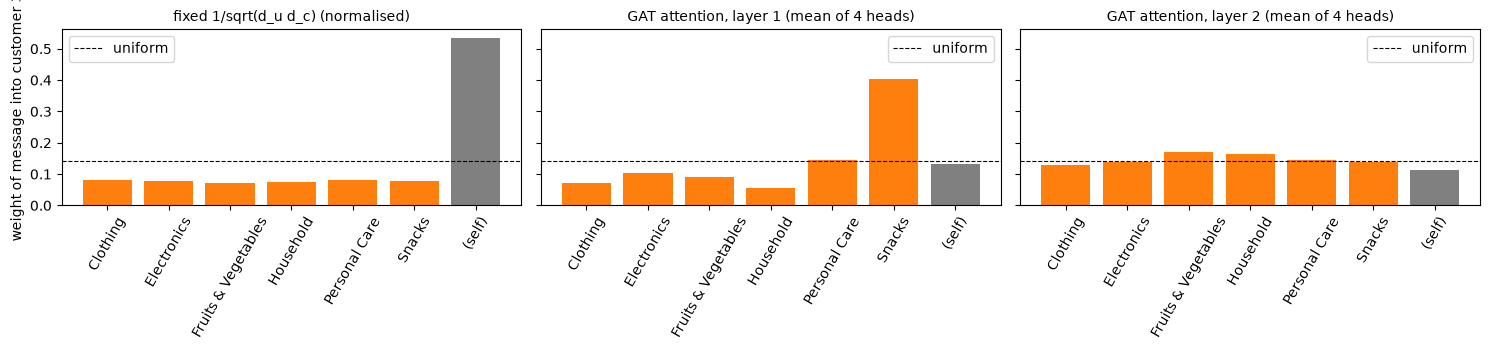

customer 3 (customer_id 4 ) neighbours and their degrees: {'Clothing': np.int64(307), 'Electronics': np.int64(335), 'Fruits & Vegetables': np.int64(406), 'Household': np.int64(354), 'Personal Care': np.int64(296), 'Snacks': np.int64(319)}
fixed : [0.081 0.077 0.07  0.075 0.082 0.079 0.535]
GAT L1: [0.072 0.102 0.089 0.056 0.145 0.402 0.132]
GAT L2: [0.13  0.139 0.17  0.165 0.145 0.137 0.114]


In [36]:
S_LAST = SNAP[11]; n = S_LAST['n']
A = np.zeros((n, N_ITEMS)); A[S_LAST['edges'].u, S_LAST['edges'].cat_id] = 1
gat0 = FINAL_GAT[0]['model']; gat0.eval()
with torch.no_grad():
    _, _, _, ATT = gat0.encode(S_LAST, return_att=True)                  # list of (edge_index incl. self-loops, alpha [E, heads])
deg_u = A.sum(1)
u = int(np.where(deg_u == 6)[0][0])                                      # a customer with 6 categories
nbrs = np.where(A[u] > 0)[0]
fixed = np.append([1 / np.sqrt((deg_u[u] + 1) * (A[:, c].sum() + 1)) for c in nbrs], 1 / (deg_u[u] + 1)); fixed /= fixed.sum()
labels = list(ITEM_NAMES[nbrs]) + ['(self)']
def att_into(layer, node):
    ei, a = ATT[layer]; ei = ei.cpu().numpy(); a = a.mean(1).cpu().numpy()
    m = ei[1] == node
    out = {('(self)' if s_ == node else ITEM_NAMES[s_ - n]): w_ for s_, w_ in zip(ei[0][m], a[m])}
    return np.array([out[l] for l in labels])
atts = [att_into(L, u) for L in range(len(ATT))]
fig, ax = plt.subplots(1, 1 + len(atts), figsize=(5 * (1 + len(atts)), 3.6), sharey=True)
for a_, w, t in zip(ax, [fixed] + atts, ['fixed 1/sqrt(d_u d_c) (normalised)'] + [f'GAT attention, layer {L + 1} (mean of 4 heads)' for L in range(len(atts))]):
    a_.bar(labels, w, color=['tab:orange'] * len(nbrs) + ['0.5']); a_.axhline(1 / len(labels), ls='--', c='k', lw=.8, label='uniform')
    a_.set_title(t, fontsize=10); a_.tick_params(axis='x', rotation=60); a_.legend()
ax[0].set_ylabel(f'weight of message into customer {u}')
plt.tight_layout(); plt.show()
print('customer', u, '(customer_id', df.drop_duplicates('cust_id').set_index('cust_id').loc[S_LAST['custs'][u], 'customer_id'], ') neighbours and their degrees:',
      dict(zip(ITEM_NAMES[nbrs], A[:, nbrs].sum(0).astype(int))))
print('fixed :', np.round(fixed, 3))
for L, a_ in enumerate(atts): print(f'GAT L{L + 1}:', np.round(a_, 3))

**Insight (Plot 1).** For customer 3 (6 categories: Clothing, Electronics, Fruits & Vegetables, Household, Personal Care, Snacks):
- The **fixed degree weights are nearly flat** across neighbours (0.070–0.082), because these categories have similar degrees (296–406), and the self-loop takes 54%.
- **GAT layer 1 is very selective**: **Snacks gets 0.40** (≈ 2.8× the uniform 1/7), Personal Care 0.15, while Household gets only 0.06. Self gets 0.13.
- **Layer 2 is close to uniform** over neighbours (0.13–0.17), with 11% on the self-loop.

So the GAT learns input-dependent, non-uniform weights in its first layer. *Next (Plot 2):* is this typical across all customers, and what do the weights correlate with?

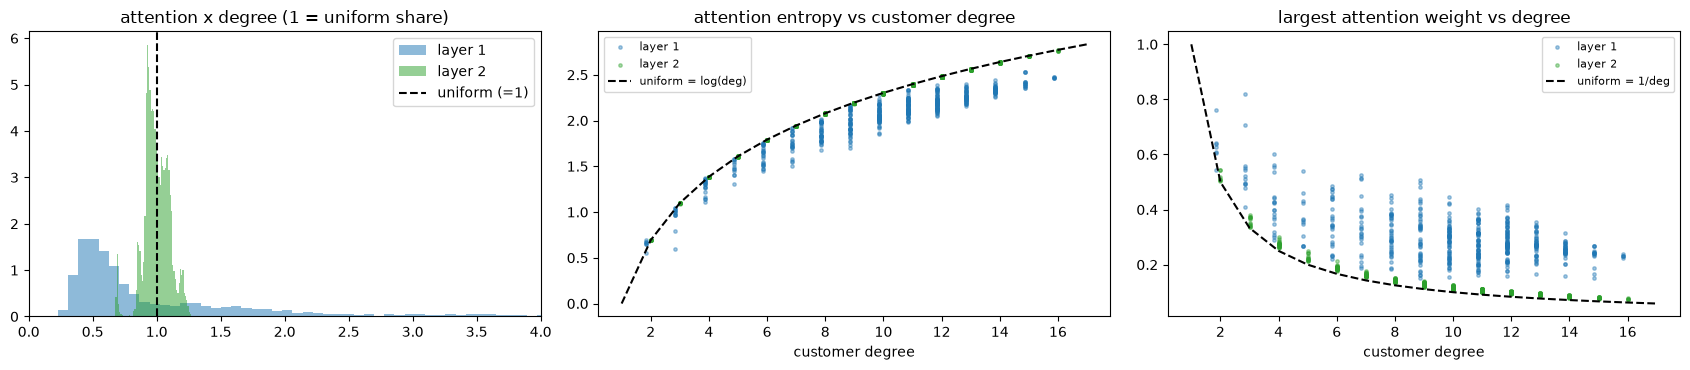

,layer 1,layer 2
mean normalised entropy (1=uniform),0.895257,0.997948
mean max-attention / uniform,2.878421,1.164598
"corr(item degree, attention)",-0.283548,0.415688
most-attended category,Snacks,Bakery
its mean share vs uniform,3.319426,1.185073
least-attended category,Beverages,Footwear
its mean share vs uniform,0.428818,0.697713


In [37]:
def attention_stats(layer):
    ei, a = ATT[layer]; dst = ei[1].cpu().numpy(); src = ei[0].cpu().numpy(); a = a.mean(1).cpu().numpy()
    d = pd.DataFrame({'dst': dst, 'src': src, 'a': a}); d = d[(d.dst < n) & (d.src != d.dst)]       # item -> customer messages, excl. self-loop
    d['a_norm'] = d.a / d.groupby('dst').a.transform('sum')                                         # renormalise over real neighbours
    g = d.groupby('dst')
    ent = g.a_norm.apply(lambda w: -(w * np.log(w)).sum()); k = g.size()
    return d, pd.DataFrame({'deg': k, 'entropy': ent, 'norm_entropy': ent / np.log(k.clip(lower=2)), 'max_att': g.a_norm.max(), 'uniform': 1 / k})

item_deg = A.sum(0)
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ATT_SUMMARY = {}
for L, c in zip(range(len(ATT)), ['tab:blue', 'tab:green', 'tab:red']):
    d, st = attention_stats(L)
    rel = d.a_norm * d.dst.map(st.deg)                                                               # 1 = uniform share
    ax[0].hist(rel, bins=60, alpha=.5, color=c, label=f'layer {L + 1}', density=True)
    ax[1].scatter(st.deg + (L - 1) * .15, st.entropy, s=6, alpha=.4, color=c, label=f'layer {L + 1}')
    ax[2].scatter(st.deg + (L - 1) * .15, st.max_att, s=6, alpha=.4, color=c, label=f'layer {L + 1}')
    per_item = rel.groupby(d.src - n).mean()
    ATT_SUMMARY[f'layer {L + 1}'] = {'mean normalised entropy (1=uniform)': st.norm_entropy[st.deg > 1].mean(),
                                     'mean max-attention / uniform': (st.max_att / st.uniform)[st.deg > 1].mean(),
                                     'corr(item degree, attention)': np.corrcoef(d.src.map(lambda s: item_deg[s - n]), rel)[0, 1],
                                     'most-attended category': ITEM_NAMES[per_item.idxmax()], 'its mean share vs uniform': per_item.max(),
                                     'least-attended category': ITEM_NAMES[per_item.idxmin()], 'its mean share vs uniform ': per_item.min()}
kk = np.arange(1, 18); ax[1].plot(kk, np.log(kk), 'k--', label='uniform = log(deg)'); ax[2].plot(kk, 1 / kk, 'k--', label='uniform = 1/deg')
ax[0].axvline(1, c='k', ls='--', label='uniform (=1)'); ax[0].set_title('attention x degree (1 = uniform share)'); ax[0].legend(); ax[0].set_xlim(0, 4)
ax[1].set_title('attention entropy vs customer degree'); ax[1].set_xlabel('customer degree'); ax[1].legend(fontsize=8)
ax[2].set_title('largest attention weight vs degree'); ax[2].set_xlabel('customer degree'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(ATT_SUMMARY)

**Insight (Plot 2, attention over all 484 customers).**
- **Layer 1 is selective, but not about taste.** Mean normalised entropy 0.90 (1 = uniform), the largest weight averages 2.9× the uniform share. Across customers it singles out the same category: **Snacks gets 3.3× the uniform weight on average**, Beverages only 0.43×. Attention correlates only weakly with category degree (r = −0.28), so this is a learned per-category preference, shared by everyone.
- **Layer 2 is essentially uniform** (entropy 0.998, max 1.16× uniform), mildly pro-popularity (r = +0.42; Bakery 1.19×, Footwear 0.70×).
- A plausible link to the test result: **Snacks is the most-attended category in layer 1, and it is exactly the category the GAT wrongly promotes into everyone's December top-5.** Suggestive, not proven.

Compared with the sampled-negative run (3 layers: −0.74 / +0.34 / +0.91 with degree), full BCE gives a 2-layer GAT whose attention tracks degree much less; but it still singles out one category globally rather than reflecting individual customers.

**Plot 3: over-smoothing.** Left: validation NDCG@5 / NDCG@10 vs number of layers (round G3). Right: mean pairwise cosine similarity of customer embeddings after each layer, for the 1-, 2- and 3-layer GATs on the December snapshot. Cosine → 1 means customers become indistinguishable.

GAT, 1 layer(s) (G1/G3 run, seed 42) cos per layer: [0.53 0.86]
GAT, 2 layer(s) (G1/G3 run, seed 42) cos per layer: [0.528 0.651 0.995]
GAT, 3 layer(s) (G1/G3 run, seed 42) cos per layer: [0.531 0.727 0.894 0.999]


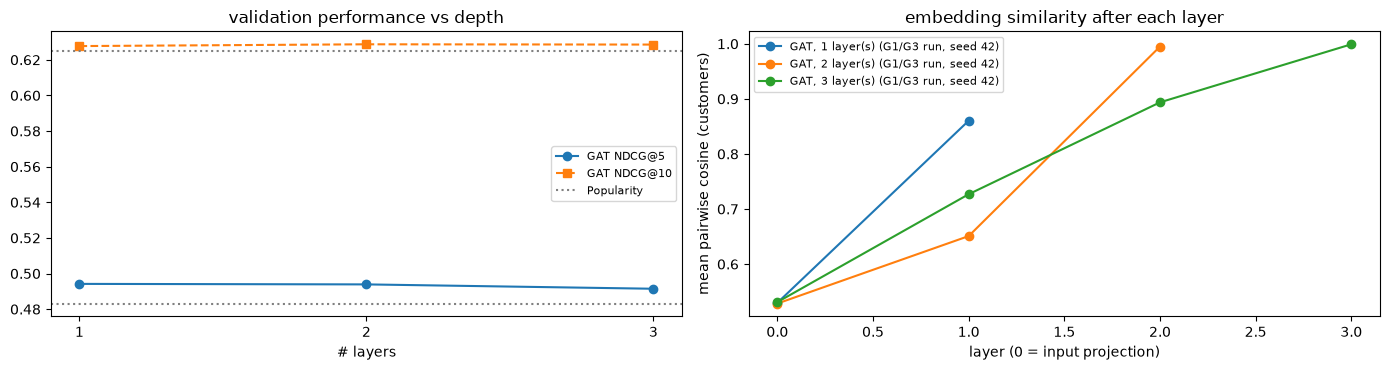

In [38]:
def mean_pairwise_cos(H):
    Hn = F.normalize(H, dim=1); S = Hn @ Hn.T; m = S.shape[0]
    return ((S.sum() - m) / (m * (m - 1))).item()
@torch.no_grad()
def layerwise_cos(model, s):
    model.eval(); _, _, layers_out, _ = model.encode(s, return_layers=True)
    return [mean_pairwise_cos(h[:s['n']]) for h in layers_out]

g3_keys = {dict(k)['layers']: k for k in RUN_CACHE
           if dict(k)['heads'] == 4 and dict(k)['att_dropout'] == 0.1 and dict(k)['dropout'] == 0.0 and dict(k)['wd'] == 0.0}   # the G1/G3 depth runs
depth_models = {f'GAT, {L} layer(s) (G1/G3 run, seed 42)': RUN_CACHE[g3_keys[L]]['model'] for L in sorted(g3_keys)}
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
sv = SENS['layers']; Ls = sorted(sv)
ax[0].plot(Ls, [sv[l]['NDCG@5'] for l in Ls], '-o', label='GAT NDCG@5'); ax[0].plot(Ls, [sv[l]['NDCG@10'] for l in Ls], '--s', label='GAT NDCG@10')
ax[0].axhline(RESULTS_VAL['Popularity']['NDCG@5'], c='grey', ls=':'); ax[0].axhline(RESULTS_VAL['Popularity']['NDCG@10'], c='grey', ls=':', label='Popularity')
ax[0].set_xticks(Ls); ax[0].set_xlabel('# layers'); ax[0].set_title('validation performance vs depth'); ax[0].legend(fontsize=8)
for name, m in depth_models.items():
    c = layerwise_cos(m, S_LAST); ax[1].plot(range(len(c)), c, marker='o', label=name); print(f'{name:30s} cos per layer: {np.round(c, 3)}')
ax[1].set_xlabel('layer (0 = input projection)'); ax[1].set_ylabel('mean pairwise cosine (customers)'); ax[1].set_title('embedding similarity after each layer'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Insight (Plot 3, over-smoothing).**
- **Performance vs depth is flat**: 1, 2 and 3 layers give val NDCG@5 0.494 / 0.494 / 0.492, all on top of each other and ~0.01 above popularity.
- **Embedding similarity collapses as soon as there is a round trip.** Customers start at mean cosine ~0.53 after the input projection. The final layer pushes them together: **0.86 (1 layer), 0.995 (2 layers), 0.999 (3 layers)**. In the 2-layer final model the hidden layer still separates customers (0.65); the last customer → category → customer hop makes them almost identical.
- With 17 category nodes each linked to 27–86% of customers, one round trip averages over most of the graph. This is the mechanism behind "one top-5 per month for everyone".

**Plot 4: UMAP of the final GAT embeddings** (seed 42, December snapshot). Left: customers and the 17 category nodes, customers coloured by their number of distinct categories so far. Right: customers only, coloured by log #orders. Spearman correlations of the UMAP axes with the customer features show what the embedding encodes.

/opt/anaconda3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/anaconda3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


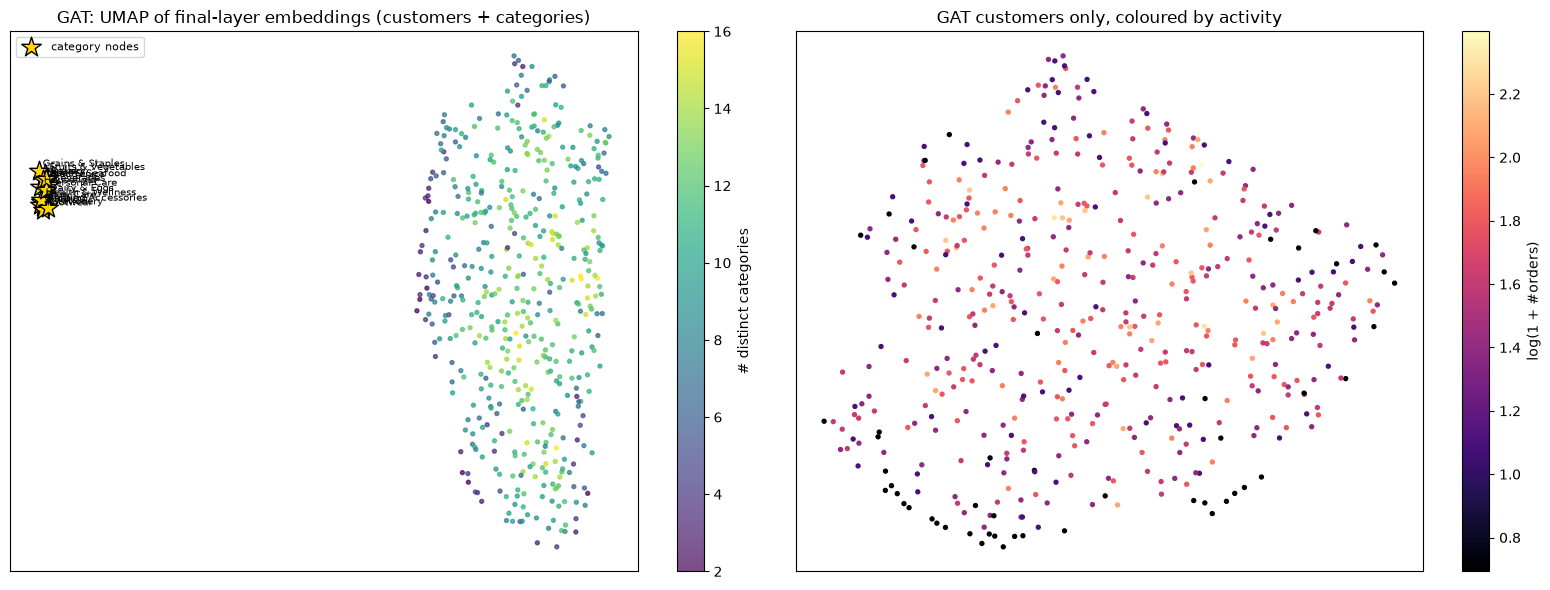

Spearman(UMAP-1, n_cats       ) = +0.14 | Spearman(UMAP-2, n_cats       ) = +0.30
Spearman(UMAP-1, log_orders   ) = +0.07 | Spearman(UMAP-2, log_orders   ) = +0.20
Spearman(UMAP-1, log_spend    ) = +0.05 | Spearman(UMAP-2, log_spend    ) = +0.23
Spearman(UMAP-1, recency_m    ) = -0.01 | Spearman(UMAP-2, recency_m    ) = -0.20
Spearman(UMAP-1, tenure_m     ) = +0.06 | Spearman(UMAP-2, tenure_m     ) = +0.11
Spearman(UMAP-1, share_weekend) = -0.04 | Spearman(UMAP-2, share_weekend) = -0.03
Spearman(UMAP-1, share_morning) = -0.00 | Spearman(UMAP-2, share_morning) = +0.05


In [39]:
import umap
from scipy.stats import spearmanr
with torch.no_grad(): zc, zi = gat0.encode(S_LAST)[:2]
Z = torch.cat([zc, zi]).cpu().numpy()
emb = umap.UMAP(n_neighbors=30, min_dist=0.3, metric='cosine', random_state=SEED).fit_transform(Z)
emb_c = umap.UMAP(n_neighbors=30, min_dist=0.3, metric='cosine', random_state=SEED).fit_transform(zc.cpu().numpy())
Xraw = S_LAST['X']
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sc = ax[0].scatter(emb[:n, 0], emb[:n, 1], c=Xraw['n_cats'], s=8, cmap='viridis', alpha=.7); plt.colorbar(sc, ax=ax[0], label='# distinct categories')
ax[0].scatter(emb[n:, 0], emb[n:, 1], marker='*', s=220, c='gold', edgecolors='k', label='category nodes')
for j in range(N_ITEMS): ax[0].annotate(ITEM_NAMES[j], emb[n + j], fontsize=7, xytext=(3, 3), textcoords='offset points')
ax[0].set_title('GAT: UMAP of final-layer embeddings (customers + categories)'); ax[0].legend(fontsize=8)
sc = ax[1].scatter(emb_c[:, 0], emb_c[:, 1], c=Xraw['log_orders'], s=8, cmap='magma'); plt.colorbar(sc, ax=ax[1], label='log(1 + #orders)')
ax[1].set_title('GAT customers only, coloured by activity')
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()
for f in ['n_cats', 'log_orders', 'log_spend', 'recency_m', 'tenure_m', 'share_weekend', 'share_morning']:
    print(f'Spearman(UMAP-1, {f:13s}) = {spearmanr(emb_c[:, 0], Xraw[f])[0]:+.2f} | Spearman(UMAP-2, {f:13s}) = {spearmanr(emb_c[:, 1], Xraw[f])[0]:+.2f}')

**Insight (Plot 4).** Two things:
1. **The 17 category nodes sit together, far from every customer** (cosine UMAP puts them in their own corner). That is expected with a dot-product decoder: ranking only needs the *projection* of customer vectors onto item vectors, not proximity.
2. **Customers form one undifferentiated cloud.** There is a faint gradient by breadth and activity along UMAP-2 (Spearman +0.30 with # categories, +0.20 with # orders, −0.20 with recency), and essentially nothing along UMAP-1 (|ρ| ≤ 0.14); shopping-time shares are ≈ 0. No taste clusters. *(The sampled-negative version had a separate island of exactly the customers who had bought Clothing Accessories; with full BCE and 2 layers that rare-item artefact is gone: a gap split along UMAP-1 isolates a single customer.)*

**Plot 5: hyper-parameter sensitivity.** One panel per tuned parameter, val Recall@10 (solid) and NDCG@10 (dashed), with the popularity reference lines.

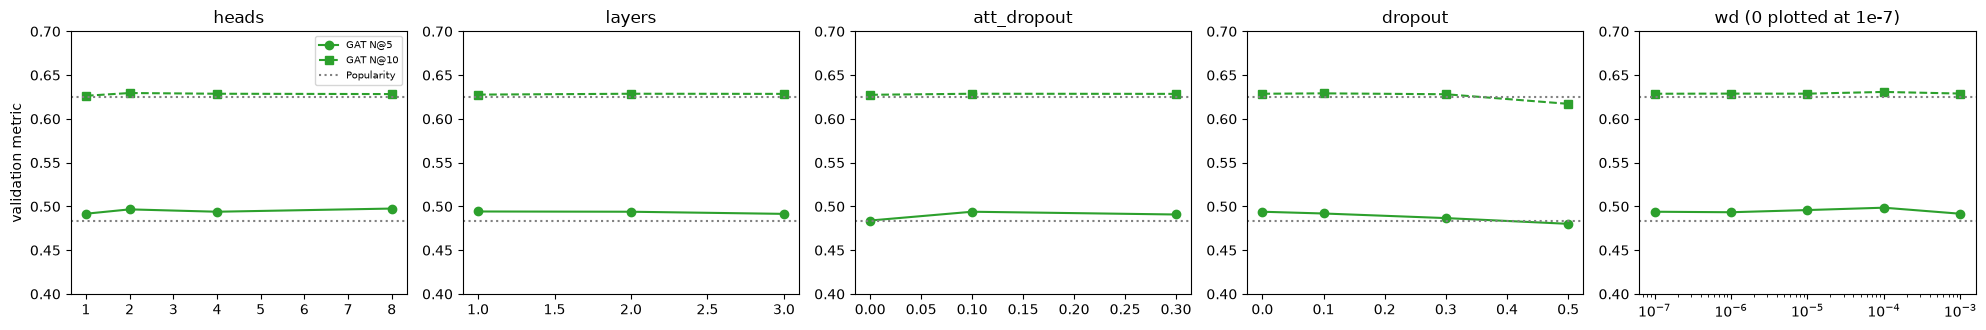

GAT heads       : NDCG@5 range 0.006 | NDCG@10 range 0.003
GAT layers      : NDCG@5 range 0.003 | NDCG@10 range 0.001
GAT att_dropout : NDCG@5 range 0.010 | NDCG@10 range 0.001
GAT dropout     : NDCG@5 range 0.014 | NDCG@10 range 0.012
GAT wd          : NDCG@5 range 0.007 | NDCG@10 range 0.002


In [40]:
params_order = [('heads', False), ('layers', False), ('att_dropout', False), ('dropout', False), ('wd', True)]
fig, axes = plt.subplots(1, len(params_order), figsize=(20, 3.4))
for a_, (p, logx) in zip(axes, params_order):
    sv = SENS[p]; xs_ = sorted(sv); xplot = [max(x, 1e-7) for x in xs_] if logx else xs_
    a_.plot(xplot, [sv[x]['NDCG@5'] for x in xs_], '-o', c='tab:green', label='GAT N@5')
    a_.plot(xplot, [sv[x]['NDCG@10'] for x in xs_], '--s', c='tab:green', label='GAT N@10')
    a_.axhline(RESULTS_VAL['Popularity']['NDCG@5'], c='grey', ls=':'); a_.axhline(RESULTS_VAL['Popularity']['NDCG@10'], c='grey', ls=':', label='Popularity')
    if logx: a_.set_xscale('log')
    a_.set_title(p + (' (0 plotted at 1e-7)' if p == 'wd' else '')); a_.set_ylim(0.40, 0.70)
axes[0].legend(fontsize=7); axes[0].set_ylabel('validation metric')
plt.tight_layout(); plt.show()
for p, sv in SENS.items():
    r = [v['NDCG@5'] for v in sv.values()]; nd = [v['NDCG@10'] for v in sv.values()]
    print(f'GAT {p:12s}: NDCG@5 range {max(r) - min(r):.3f} | NDCG@10 range {max(nd) - min(nd):.3f}')

**Insight (Plot 5, sensitivity).** **Every curve is flat**: across all tuned values val NDCG@5 moves by at most 0.014 (dropout, driven by 0.5 being slightly harmful) and NDCG@10 by at most 0.012, all sitting just above the popularity line. When the only learnable signal is the popularity ordering, every reasonable configuration recovers it, and none can do more.

**Plot 6: predicted vs actual for 30 test customers** (December, customers who bought something). Seed-averaged GAT probabilities and LogReg probabilities; rows are customers, columns categories ordered by actual December buy rate; black dots mark actual purchases.

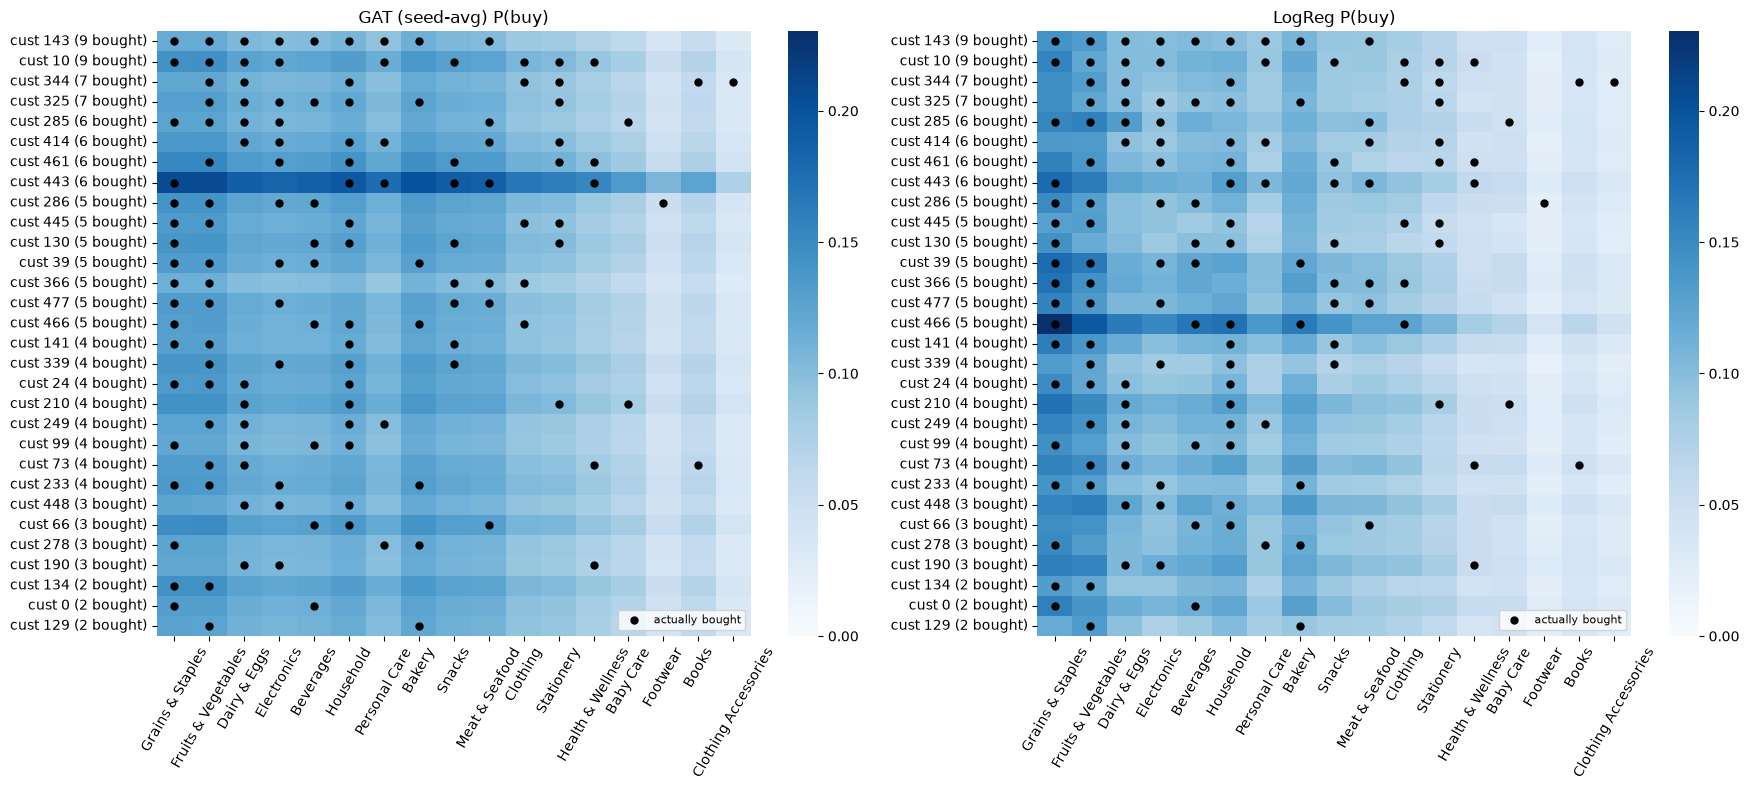

GAT   : mean corr(customer row, average row) = 1.000 | share of December buyers with >= 1 hit in their top-3 = 0.813
LogReg: mean corr(customer row, average row) = 0.993 | share of December buyers with >= 1 hit in their top-3 = 0.836


In [41]:
lo = SPLIT_SNAPS['test'][0]['n']; hi = lo + SPLIT_SNAPS['test'][1]['n']
Y12 = Y_TEST[lo:hi]; G12 = calibrated(MEAN_SCORES['GAT'][lo:hi]); L12 = MEAN_SCORES['LogReg'][lo:hi]
buyers = np.where(Y12.sum(1) > 0)[0]; pick = np.random.default_rng(5).choice(buyers, 30, replace=False)
pick = pick[np.argsort(-Y12[pick].sum(1))]
col_order = np.argsort(-Y12.mean(0))
vmax = max(G12[pick].max(), L12[pick].max())
fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a_, P, t in zip(ax, [G12, L12], ['GAT (seed-avg) P(buy)', 'LogReg P(buy)']):
    sns.heatmap(P[pick][:, col_order], ax=a_, cmap='Blues', vmin=0, vmax=vmax, xticklabels=ITEM_NAMES[col_order],
                yticklabels=[f'cust {SPLIT_SNAPS["test"][1]["custs"][i]} ({Y12[i].sum()} bought)' for i in pick])
    yy, xx = np.where(Y12[pick][:, col_order] == 1); a_.scatter(xx + .5, yy + .5, c='k', s=25, marker='o', label='actually bought')
    a_.set_title(t); a_.tick_params(axis='x', rotation=60); a_.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()
for name, P in [('GAT', G12), ('LogReg', L12)]:
    rc = np.mean([np.corrcoef(P[i], P.mean(0))[0, 1] for i in buyers])
    hit3 = np.mean([Y12[i][np.argsort(-P[i])[:3]].sum() > 0 for i in buyers])
    print(f'{name:6s}: mean corr(customer row, average row) = {rc:.3f} | share of December buyers with >= 1 hit in their top-3 = {hit3:.3f}')

**Insight (Plot 6).** **Every GAT row is the same picture** with a different overall intensity: the mean correlation of a customer's GAT probability row with the average row is **1.000** (LogReg: 0.993). Actual purchases (dots) are scattered across all 17 columns with no visible link to the row. Because baskets are wide (~5 categories), **81% of December buyers still have at least one hit in GAT's top-3** (LogReg 84%), almost entirely from the two 8-product staples.

**Plot 7: final comparison.** Test NDCG@5 (headline), Recall@5, NDCG@10 and PR-AUC for every model, mean ± std over seeds 42, 43, 44.

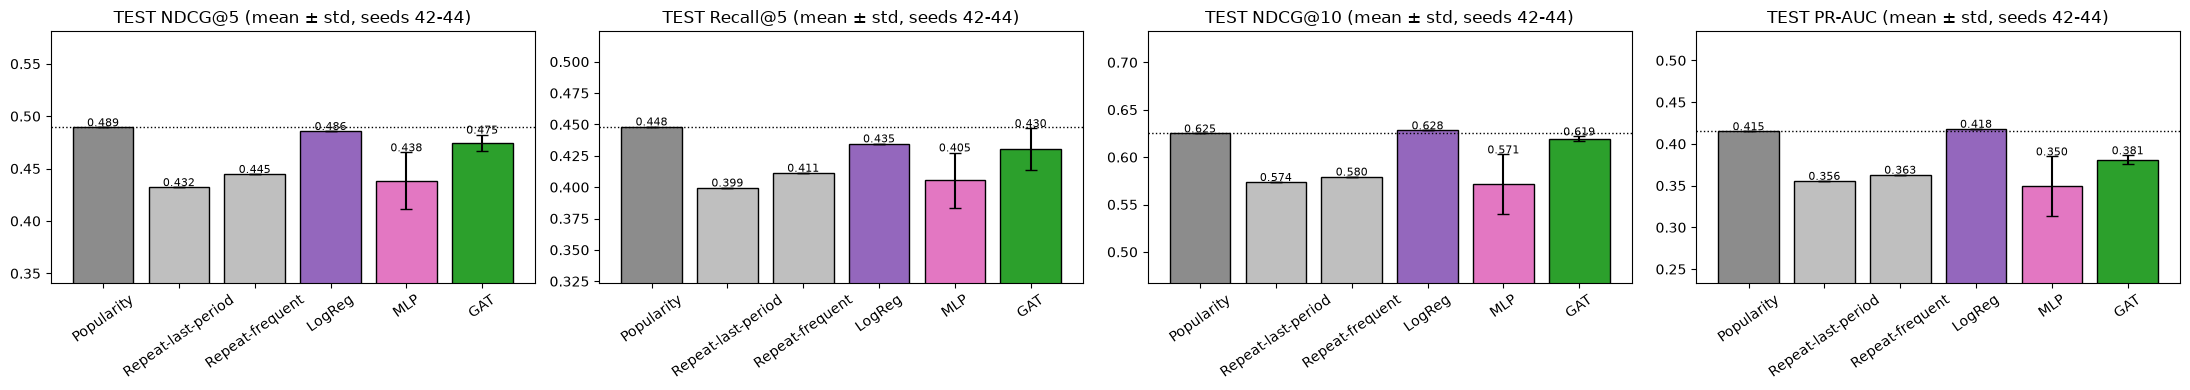

In [42]:
colors = ['0.55', '0.75', '0.75', 'tab:purple', 'tab:pink', 'tab:green']
fig, ax = plt.subplots(1, 4, figsize=(22, 4))
for a_, k in zip(ax, ['NDCG@5', 'Recall@5', 'NDCG@10', 'PR-AUC']):
    mu = [MEAN[m][k] for m in MODELS]; sd = [STD[m][k] for m in MODELS]
    a_.bar(MODELS, mu, yerr=sd, capsize=4, color=colors, edgecolor='k')
    a_.axhline(MEAN['Popularity'][k], c='k', ls=':', lw=1)
    a_.set_ylim(min(mu) - 3 * max(sd) - .01, max(mu) + 3 * max(sd) + .01)
    for i, (m_, s_) in enumerate(zip(mu, sd)): a_.text(i, m_ + s_ + .001, f'{m_:.3f}', ha='center', fontsize=8)
    a_.set_title(f'TEST {k} (mean ± std, seeds 42-44)'); a_.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.show()

**Insight (Plot 7).** Popularity (dotted line) is the bar to beat and **nothing beats it**. LogReg ties it. GAT sits just below on NDCG@5, Recall@5 and NDCG@10 and clearly below on PR-AUC, with visible seed spread on Recall@5. The repeat heuristics and the MLP are clearly worst. *(Y-axes are zoomed so sub-0.02 differences are visible; they do not start at 0.)*

*Next:* write the tuning log and test results into the **Experiment Log** cell at the top, then the Findings.

In [43]:
def exp_log_markdown():
    P = RESULTS_VAL['Popularity']
    lines = ['## Experiment Log', '',
             f"*Protocol: 12 months = train 8 / val 2 / test 2; full BCE; dot-product decoder fixed; final seeds 42, 43, 44; headline metric NDCG@5.*", '',
             f"*Validation set (targets 2024-09 and 2024-10, {P['n_cust']} customer-months). Adoption rule: change kept only if val NDCG@5 improves by >= 0.01. "
             f"Reference: Popularity NDCG@5 {P['NDCG@5']:.3f} / Recall@5 {P['Recall@5']:.3f} / NDCG@10 {P['NDCG@10']:.3f} / PR-AUC {P['PR-AUC']:.3f}.*", '',
             '| Round | Model | Change | Val NDCG@5 | Val Recall@5 | Val NDCG@10 | Val PR-AUC | Conclusion |', '|---|---|---|---|---|---|---|---|']
    for r in EXP_LOG:
        lines.append(f"| {r['round']} | {r['model']} | {r['change']} | {r['Val NDCG@5']:.4f} | {r['Val Recall@5']:.4f} | {r['Val NDCG@10']:.4f} | {r['Val PR-AUC']:.4f} | {r['conclusion']} |")
    lines += ['', f'**Final GAT config:** {GAT_CUR}', '',
              f"**Final TEST results (targets 2024-11 and 2024-12, {int((Y_TEST.sum(1) > 0).sum())} customer-months; mean ± std over seeds 42, 43, 44):**", '',
              '| Model | **NDCG@5** | Recall@5 | Precision@5 | HitRate@5 | NDCG@3 | NDCG@10 | Recall@10 | PR-AUC | Params | GAT vs this model (gap > seed std; NDCG@5 / NDCG@3 / NDCG@10 / PR-AUC) |',
              '|---|---|---|---|---|---|---|---|---|---|---|']
    for m in MODELS:
        v = 'reference' if m == 'GAT' else ' / '.join(better('GAT', m, k)[2] for k in ['NDCG@5', 'NDCG@3', 'NDCG@10', 'PR-AUC'])
        cells = ' | '.join(f"{MEAN[m][k]:.4f} ± {STD[m][k]:.4f}" for k in ['NDCG@5', 'Recall@5', 'Precision@5', 'HitRate@5', 'NDCG@3', 'NDCG@10', 'Recall@10', 'PR-AUC'])
        lines.append(f"| {m} | {cells} | {PARAMS[m]:,} | {v} |")
    return '\n'.join(lines)
EXP_MD = exp_log_markdown()
print(EXP_MD)

## Experiment Log

*Protocol: 12 months = train 8 / val 2 / test 2; full BCE; dot-product decoder fixed; final seeds 42, 43, 44; headline metric NDCG@5.*

*Validation set (targets 2024-09 and 2024-10, 255 customer-months). Adoption rule: change kept only if val NDCG@5 improves by >= 0.01. Reference: Popularity NDCG@5 0.483 / Recall@5 0.438 / NDCG@10 0.625 / PR-AUC 0.415.*

| Round | Model | Change | Val NDCG@5 | Val Recall@5 | Val NDCG@10 | Val PR-AUC | Conclusion |
|---|---|---|---|---|---|---|---|
| G1 | GAT | baseline (2L, 4 heads, d64, att-drop .1) | 0.4939 | 0.4460 | 0.6287 | 0.3991 | GAT reference |
| G2 | GAT | heads = 1 | 0.4916 | 0.4475 | 0.6264 | 0.4054 |  |
| G2 | GAT | heads = 2 | 0.4966 | 0.4489 | 0.6295 | 0.3996 |  |
| G2 | GAT | heads = 8 | 0.4975 | 0.4489 | 0.6283 | 0.3947 | best heads=8 gain +0.004 -> adopt 4 |
| G3 | GAT | layers = 1 | 0.4942 | 0.4466 | 0.6277 | 0.3888 |  |
| G3 | GAT | layers = 3 | 0.4915 | 0.4455 | 0.6285 | 0.4126 | best layers=1 gain +0.000 -> adop

# Findings

**Setup recap.** Retail POS transactions, 2024-01 to 2024-12 (10,000 lines → 9,701 after merging split lines; 488 customers, 1,991 orders). Customer × **category** (17) bipartite graph, **monthly** snapshots G_t → targets Y_{t+1}. **Group protocol:** 12 months = **train 8 / val 2 / test 2**; **full BCE**; **dot-product decoder fixed**; final seeds **42, 43, 44**; metrics @3, @5, @10 + PR-AUC with **NDCG@5 as headline** (also used for early stopping and tuning). Only GAT was trained; baselines as in EuroMart.

### Hypothesis scorecard

| ID | Hypothesis | Verdict | Evidence |
|---|---|---|---|
| H1 | GAT beats the non-graph baselines | ❌ **Not supported** | Test **NDCG@5: Popularity 0.489, LogReg 0.486, GAT 0.475 ± .008**. Seed-std rule: GAT worse than Popularity and LogReg; bootstrap vs Popularity −0.007 [−0.022, +0.007]. GAT beats only the repeat heuristics and the MLP |
| H2 | Learned attention helps low-degree customers most | ❌ **Not supported** | Low-degree NDCG@5: GAT 0.477 vs Popularity 0.505 (the largest gap of any bin) |
| H3 | Own history raises the chance of rebuying a category | ❌ **Not supported** | Controlled OR 1.02, 95% CI [0.95, 1.10]; repeat baselines are among the worst models |
| H4 | % of customers buying each category next month is predictable | ✅ **Supported** | MAE 0.82 pp (running mean), 1.11 (last month), 1.23 (LogReg), 2.05 (GAT) |
| H5 | When people shop changes what they buy | ❌ **Not supported (practically)** | weekend p = 0.47, V = 0.04; daypart p = 0.009 but V = 0.05, max gap 1.7 pp |
| H6 | Purchasing is seasonal by month | ❌ **Not supported** | orders per month vs uniform: p = 0.97 (*too* even); category mix by month p = 0.16 |

### Insights from the GAT

1. **It learns one ranking per month, not personal recommendations.** In November 99.6% of customers get exactly the popularity top-5; in December 99.6% get the same set with Snacks in place of Dairy & Eggs. Each customer's score row correlates 0.98 with popularity (1.00 between customers).
2. **Its only deviation from popularity is a mistake.** Snacks (8.3% of customers bought it in December) displaces Dairy & Eggs (10.5%), which is why GAT's NDCG@5 and Recall@5 trail popularity.
3. **Attention singles out one category for everyone.** Layer 1 is selective (entropy 0.90, top weight 2.9× uniform), and the same category, **Snacks (3.3× uniform)**, gets the most attention across customers, matching the December top-5 error. Layer 2 is uniform. Correlation of attention with category degree is weak (−0.28 / +0.42), so it is not even a clean popularity rule.
4. **Over-smoothing removes customer differences.** Mean pairwise cosine of customer embeddings goes 0.53 → 0.65 → **0.995** in the 2-layer model (0.999 with 3 layers). The UMAP shows one cloud with only faint breadth/activity gradients.
5. **Tuning hardly matters.** Across heads, depth, attention dropout, dropout and weight decay, val NDCG@5 stays in 0.480–0.499; **no change cleared the 0.01 rule**, so EuroMart's GAT config (2 layers, 4 heads, d = 64, att-dropout 0.1) is final. Its +0.011 validation edge over popularity turned into −0.015 on test. 23k parameters to match a 17-number popularity vector.
6. **Full BCE probabilities are usable but compressed.** No Platt scaling is needed any more, but GAT's per-category % forecasts are pulled toward the mean (under-predicting staples, over-predicting small categories by 3–4 pp), giving the worst H4 error (2.05 pp) and the lowest PR-AUC among the strong models (0.381 vs 0.415).

### Why: which property of this dataset explains the results?
The data contains **no signal beyond item popularity and customer volume**, and the popularity itself is a catalogue artefact:
- **Products are sampled near-uniformly**: 143 ± 10 lines per product (CV 0.074, *below* the 0.084 expected from random sampling), and category volume = number of products in it (r = 0.998).
- **No collaborative structure**: neighbourhood Jaccard equals a degree-preserving random graph (ratio 1.00 at category level, 1.01 at product level), and category lift matches the null.
- **No personal persistence**: controlled OR for "bought c before" = 1.02 [0.95, 1.10].
- **No time structure**: orders are spread over months more evenly than chance (p = 0.97), the category mix does not change by month, and next-month basket size does not grow with past breadth.
- **Dense, few items**: 17 categories at 59% density by December, so message passing over-smooths after one round trip.

Under these conditions **popularity is close to the Bayes-optimal ranking**. The GAT converges toward it but adds estimation noise (here, one wrong swap in December).

### Effect of the protocol change (sampled negatives + Recall@10 selection → full BCE + NDCG@5 selection)
- Best depth went from 3 layers back to 2 (the earlier 3-layer adoption was a +0.0106 edge just over the threshold). No other setting changed.
- GAT's ranking moved *closer* to popularity (November top-5 identical; Spearman 0.97 vs 0.95), but the test conclusion is unchanged: GAT ≤ Popularity ≈ LogReg.
- Full BCE needs the 50-epoch warm-up even more: val NDCG@5 dips to 0.15 (below random) around epoch 5 while the model first learns the base rate.

### Comparison with EuroMart (Dataset 2)
*EuroMart was run under the earlier protocol (quarterly, sampled negatives, Recall@10 selection, 5 seeds), so compare conclusions rather than exact numbers.*

| | EuroMart (sub-category, quarterly) | Retail POS (category, monthly) |
|---|---|---|
| items / density at test | 17 / 37% | 17 / 59% |
| eval customers val / test | 445 / 872 | 255 / 262 |
| positives per buying customer | ~2 | ~5 |
| Jaccard ratio vs null | 1.00 | 1.00 |
| controlled persistence OR | 1.01 [0.94, 1.09] | 1.02 [0.95, 1.10] |
| seasonality | volume yes (Q3/Q4), mix no | none (too even) |
| final GAT config | 2 layers, 4 heads, att-drop 0.1 | identical |
| GAT vs popularity on test | worse (NDCG@10 0.458 vs 0.475) | worse (NDCG@5 0.475 vs 0.489; bootstrap: no sig. difference) |
| customer embedding cosine (final layer) | 0.96–1.00 | 0.995 |

**Same conclusion on both datasets:** GAT recovers popularity and nothing more, because neither dataset has preference structure to learn.

### Limitations
- **One year of data, monthly periods**: only 2 val and 2 test months (255 / 262 customer-months), and only 3 final seeds, so differences below ~0.02 NDCG@5 cannot be resolved; per-degree-bin results (69–97 customer-months) are weaker still.
- **Cold-start customers** (first seen in t+1) are excluded: 4–8 per val/test month, 88 in February.
- **No customer attributes** in this dataset; all features are history-derived.
- **Homogeneous graph and static snapshots**: the category → product hierarchy is not modelled as typed edges, and there is no temporal GNN.
- **Unweighted full BCE** with an ~8% positive rate: probabilities are usable but compressed; a class-weighted variant was not tested (kept out to follow the group protocol).
- **Engineering note:** running scikit-learn `KMeans` after torch in the same kernel deadlocked the kernel earlier (likely an OpenMP clash), so the notebook avoids it.
- **Generalisability**: this dataset looks synthetic (uniform product sampling, uniform quantities 1–3, uniform lines per order 3–7, under-dispersed monthly counts). On real retail data with genuine co-purchase structure, attention may well help; Phase 2 is the test to run before investing in a GNN.

**Bottom line:** recommend categories by popularity (equivalently, by number of products in the category) and forecast next month's % buying with a running average. Under the group protocol the GAT converges to the same answer and is slightly worse on the headline NDCG@5.

In [44]:
# verification of numbers quoted in the Findings (final consistency check)
print('test customer-months:', int((Y_TEST.sum(1) > 0).sum()), '| val:', int((Y_VAL.sum(1) > 0).sum()))
print('test density (Dec snapshot):', round(len(S_LAST['edges']) / (S_LAST['n'] * N_ITEMS), 3))
print('GAT test means:', {k: round(MEAN['GAT'][k], 4) for k in ['NDCG@5', 'Recall@5', 'NDCG@3', 'NDCG@10', 'PR-AUC']})
print('Popularity / LogReg NDCG@5:', round(MEAN['Popularity']['NDCG@5'], 4), round(MEAN['LogReg']['NDCG@5'], 4))
print('final seeds:', SEEDS, '| split (train/val/test target months):', TRAIN_T1, VAL_T1, TEST_T1)
print('distinct GAT top-5 sets:', gat_top5.nunique(), '| mean row corr with popularity:', round(row_corr.mean(), 3))
print('attention corr with item degree per layer:', {k: round(v['corr(item degree, attention)'], 2) for k, v in ATT_SUMMARY.items()})
print('H4 MAE (pp):', {e: round((PCT[e] - PCT['actual %']).abs().mean(), 2) for e in ests})
print('GAT params:', PARAMS['GAT'])

test customer-months: 262 | val: 255
test density (Dec snapshot): 0.586
GAT test means: {'NDCG@5': np.float64(0.4747), 'Recall@5': np.float64(0.4304), 'NDCG@3': np.float64(0.4722), 'NDCG@10': np.float64(0.6194), 'PR-AUC': np.float64(0.381)}
Popularity / LogReg NDCG@5: 0.4894 0.4858
final seeds: [42, 43, 44] | split (train/val/test target months): [1, 2, 3, 4, 5, 6, 7] [8, 9] [10, 11]
distinct GAT top-5 sets: 5 | mean row corr with popularity: 0.977
attention corr with item degree per layer: {'layer 1': np.float64(-0.28), 'layer 2': np.float64(0.42)}
H4 MAE (pp): {'LogReg': np.float64(1.23), 'GAT': np.float64(2.05), 'Naive: last month': np.float64(1.11), 'Naive: running mean': np.float64(0.82)}
GAT params: 23232


## 3.5.1 Overall performance comparison (Retail POS, all four methods)

**What:** a 2×2 bar chart of the group's comparison table: test **Recall@10**, test **NDCG@10**, test **PR-AUC** and **training time per run**, for each owner's best (tuned) model. Values are copied from the group table (GCN, GraphSAGE and LightGCN rows from their owners; GAT from this notebook). Error bars show ± std over seeds where the owner reported it (GCN reported a single value, so it has no error bar).

**Why:** one figure (Figure 2) that shows accuracy and cost side by side. The metric axes start at 0 so that bar lengths stay honest; the exact values are printed on the bars because the differences between methods are very small.

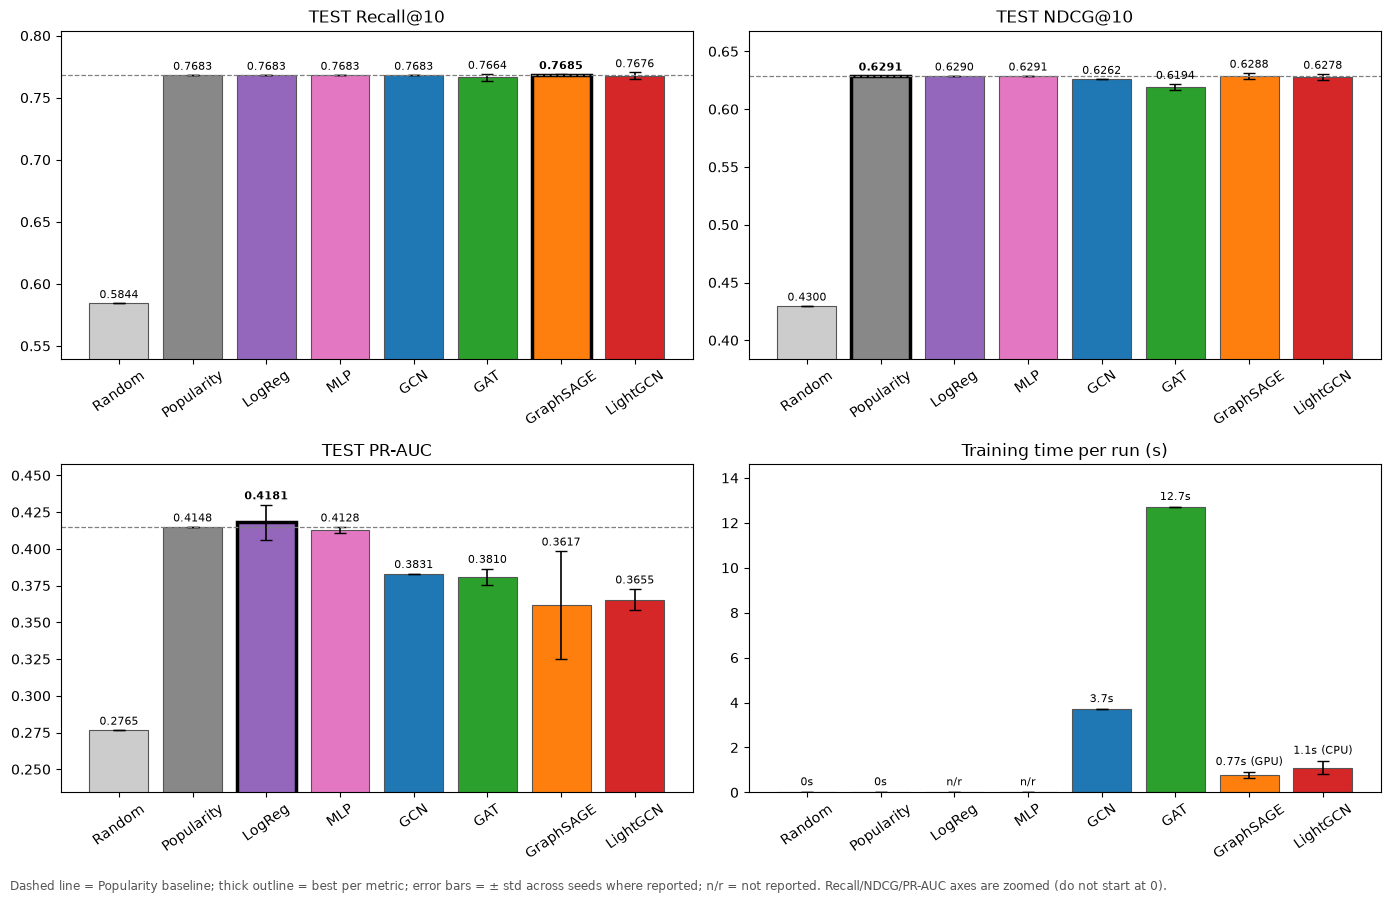

In [4]:
# Figure 2 - overall comparison on Retail POS: baselines vs. tuned GNNs (values from the group's 3.5.1 table)
import numpy as np
import matplotlib.pyplot as plt

methods = ['Random', 'Popularity', 'LogReg', 'MLP', 'GCN', 'GAT', 'GraphSAGE', 'LightGCN']
colors  = ['#cccccc', '#888888', '#9467bd', '#e377c2', '#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']
# mean, std (None = not reported)
results = {
    'TEST Recall@10': ([0.5844, 0.7683, 0.7683, 0.7683, 0.7683, 0.7664, 0.7685, 0.7676],
                       [None, None, 0.0000, 0.0000, None, 0.0027, 0.0004, 0.0028]),
    'TEST NDCG@10':   ([0.4300, 0.6291, 0.6290, 0.6291, 0.6262, 0.6194, 0.6288, 0.6278],
                       [None, None, 0.0001, 0.0000, None, 0.0025, 0.0027, 0.0028]),
    'TEST PR-AUC':    ([0.2765, 0.4148, 0.4181, 0.4128, 0.3831, 0.3810, 0.3617, 0.3655],
                       [None, None, 0.0118, 0.0020, None, 0.0056, 0.0367, 0.0071]),
}
# training time per run (s); None = not reported
train_time = ([0, 0, None, None, 3.7, 12.7, 0.77, 1.1],
              [None, None, None, None, None, None, 0.13, 0.3])
hw = ['', '', '', '', '', '', ' (GPU)', ' (CPU)']

x = np.arange(len(methods))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (metric, (mean, std)) in zip(axes.flat[:3], results.items()):
    mean = np.array(mean); err = np.array([s if s is not None else 0 for s in std])
    best = int(np.argmax(mean))
    bars = ax.bar(x, mean, yerr=err, capsize=4, color=colors, edgecolor='#555555', linewidth=0.8,
                  error_kw=dict(elinewidth=1.2, ecolor='black'))
    bars[best].set_edgecolor('black'); bars[best].set_linewidth(2.5)          # best per metric
    ax.axhline(mean[1], color='grey', linestyle='--', linewidth=0.9)          # Popularity reference line
    for i, (m, e) in enumerate(zip(mean, err)):
        ax.text(i, m + e + 0.002, f'{m:.4f}', ha='center', va='bottom', fontsize=8,
                fontweight='bold' if i == best else 'normal')
    lo, hi = mean.min(), (mean + err).max()
    ax.set_ylim(lo - 0.08 * (hi - lo) - 0.03, hi + 0.18 * (hi - lo))
    ax.set_title(metric)
    ax.set_xticks(x); ax.set_xticklabels(methods, rotation=35)

ax = axes.flat[3]
tm = np.array([t if t is not None else 0 for t in train_time[0]], dtype=float)
te = np.array([s if s is not None else 0 for s in train_time[1]])
ax.bar(x, tm, yerr=te, capsize=4, color=colors, edgecolor='#555555', linewidth=0.8,
       error_kw=dict(elinewidth=1.2, ecolor='black'))
for i, (t, e) in enumerate(zip(train_time[0], te)):
    lab = 'n/r' if t is None else f'{t:g}s{hw[i]}'
    ax.text(i, (t or 0) + e + 0.2, lab, ha='center', va='bottom', fontsize=8)
ax.set_ylim(0, max(tm) * 1.15)
ax.set_title('Training time per run (s)')
ax.set_xticks(x); ax.set_xticklabels(methods, rotation=35)

fig.text(0.01, 0.005, 'Dashed line = Popularity baseline; thick outline = best per metric; error bars = ± std across seeds where reported; '
         'n/r = not reported. Recall/NDCG/PR-AUC axes are zoomed (do not start at 0).', fontsize=8.5, color='#555555')
plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.show()


**Insight (Figure 2).**
- **Accuracy is essentially tied across all four GNNs.** The spread between the best and worst method is only **0.002 Recall@10** (0.7664–0.7685) and **0.009 NDCG@10** (0.6194–0.6288), smaller than or comparable to the seed std of most methods. GraphSAGE is nominally best on both, but within noise of GCN and LightGCN; GAT is nominally lowest.
- **PR-AUC separates them a little more** (0.3617–0.3831, spread 0.021). GCN (0.383) and GAT (0.381) lead; GraphSAGE has the lowest mean *and* by far the largest seed variance (± 0.037), so its PR-AUC is unstable.
- **Cost differs much more than accuracy.** GAT is the most expensive (12.7 s per run, ~23k parameters, attention over every edge), about 3–4× GCN (3.7 s) and over 10× LightGCN (1.1 s, CPU) and GraphSAGE (0.77 s, GPU). *Timings come from different machines (GPU vs CPU), so compare them as orders of magnitude, not exact ratios.*
- **Context from the baselines:** Popularity scores Recall@10 0.763, NDCG@10 0.625 and PR-AUC 0.415 on the same test set. All four GNNs land within about ±0.006 of it on the ranking metrics and *below* it on PR-AUC, consistent with Phase 2's finding that this dataset holds no signal beyond popularity.

**Takeaway:** on Retail POS the choice of GNN architecture barely affects accuracy, so the cheaper, simpler models (LightGCN, GraphSAGE, GCN) are preferable to GAT.